# Upper-bound $L$ experiment — $n=1000$, $p=100$

<span style="color:#4477AA">**New paper experiment.** Plotting reference: `M1_upsample_final.ipynb`, `M2_upsample_final.ipynb`, and `M3_upsample_final.ipynb`.</span>

Only the requested setting $n=1000$, $p=100$ is plotted here. The true number of signals is $L^\star=4$, with change points at fractional locations $0.2,0.5,0.8$. Each upper bound $L=1,\ldots,6$ is passed separately to the exact-count 10-fold CV helper. Training uses half-squared loss, held-out scoring uses absolute loss, and the minimum segment length is $\Delta_n=n/10$ (the same fraction is applied within each training fold). There are 100 paired trials.

The run cell is self-contained, reuses the validated per-trial checkpoints, and can generate missing trials. The plotting cell is independently self-contained and reads the saved experiment. No cells in other notebooks need to run first. Computation and scientific results are unchanged; the plots use the gold notebooks' actual TeX/serif configuration, error-bar calculation, and boxplot helpers.


In [1]:
# SELF-CONTAINED: run this cell directly after restarting the kernel.
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('MKL_NUM_THREADS','1')
import pickle, json, hashlib, time, random
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
from io import StringIO
import numpy as np
import jax
jax.config.update('jax_enable_x64',True)
import torch
from joblib import Parallel, delayed, parallel_config
from WERM.experiment_utils import weighted_erm_joint_cv
import WERM.experiment_utils as el_utils
import WERM.estimators as el_estimators
import WERM.config as el_config

EL_ROOT=Path('results/E_L_upperbound_gap10_n1000_p100')
EL_ROOT.mkdir(parents=True,exist_ok=True)
EL_SETTINGS=[(1000,100)]
EL_TRIALS=int(os.environ.get('EL_TRIALS','100'))
EL_JOBS=int(os.environ.get('EL_JOBS','36'))
EL_SEED=20261120
EL_BOUNDS=np.arange(1,7)
EL_LOSS=lambda prediction,truth:.5*(np.asarray(prediction)-np.asarray(truth))**2
EL_SCORE=lambda prediction,truth:np.abs(np.asarray(prediction)-np.asarray(truth))

def el_data(n,p,trial):
    rng=np.random.default_rng(np.random.SeedSequence([EL_SEED,n,p,trial]))
    beta=np.empty((p,4)); beta[:,0]=rng.normal(size=p)*np.sqrt(n/p)
    for k in range(1,4):beta[:,k]=beta[:,k-1]+1.5*np.sqrt(n/p)*rng.normal(size=p)
    X=rng.normal(size=(n,p))/np.sqrt(n)
    truth=np.rint(n*np.array([.2,.5,.8])).astype(int)
    state=np.searchsorted(truth,np.arange(n),side='right')
    mu=np.einsum('ij,ij->i',X,beta[:,state].T)
    y=mu+rng.normal(0,.5,n)
    return X,y,beta,truth,state,mu

def el_metrics(cp,truth,n):
    cp=np.asarray(cp,int)
    if cp.size:
        d=np.abs(cp[:,None]-truth[None,:])/n
        haus=float(max(d.min(axis=0).max(),d.min(axis=1).max()))
    else:haus=np.nan
    return dict(haus=haus,bounded_haus=haus if cp.size else 1.,empty=not bool(cp.size),
                count_error=abs(len(cp)-len(truth)),correct_count=len(cp)==len(truth))

# Cache only deterministic reference-grid enumeration, not fitted marginal
# curves or estimator outputs. GP optimization and all RNG calls are unchanged.
def el_enable_enumeration_cache():
    if not hasattr(el_config,'_el_original_enumeration'):
        el_config._el_original_enumeration=el_config.unif_prior_to_η_ϕ
        el_config._el_enumeration_cache={}
    def cached_enumeration(Lmin,Lmax,Delta,n,p_l=None):
        key=(int(Lmin),int(Lmax),int(Delta),int(n),None if p_l is None else tuple(np.asarray(p_l)))
        if key not in el_config._el_enumeration_cache:
            el_config._el_enumeration_cache[key]=el_config._el_original_enumeration(Lmin,Lmax,Delta,n,p_l=p_l)
        return el_config._el_enumeration_cache[key]
    el_config.unif_prior_to_η_ϕ=cached_enumeration

# State-aware replay cache: identical arguments AND entry RNG states are
# required for a hit; exit states are restored exactly. Thus repeated calls
# consume the same random stream and return the same original curve fit.
def el_enable_curve_replay_cache():
    if not hasattr(el_config,'_el_original_extrapolation'):
        el_config._el_original_extrapolation=el_config.extrapolated_marginals
    el_config._el_curve_replay_cache={}
    def replay_extrapolation(Lmin,Lmax,Delta_small,n_small=50,n_large=1000,p_l=None,verbose='summary'):
        entry=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        arguments=(Lmin,Lmax,Delta_small,n_small,n_large,None if p_l is None else tuple(p_l))
        key=hashlib.sha256(pickle.dumps((arguments,entry[0],entry[1].numpy().tobytes(),entry[2]))).hexdigest()
        if key in el_config._el_curve_replay_cache:
            value,exit_state=el_config._el_curve_replay_cache[key]
            np.random.set_state(exit_state[0]);torch.set_rng_state(exit_state[1]);random.setstate(exit_state[2])
            return value.copy()
        value=el_config._el_original_extrapolation(Lmin,Lmax,Delta_small,n_small,n_large,p_l=p_l,verbose=verbose)
        exit_state=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        el_config._el_curve_replay_cache[key]=(value.copy(),exit_state)
        return value
    el_config.extrapolated_marginals=replay_extrapolation

def el_trial(n,p,trial):
    path=EL_ROOT/f'n{n}_p{p}_trial{trial:03d}.pkl'
    if path.exists():
        with path.open('rb') as f:return pickle.load(f)
    el_enable_enumeration_cache()
    el_enable_curve_replay_cache()
    X,y,beta,truth,state,mu=el_data(n,p,trial)
    fits={}; trace={}; refits=[]; train_cp=[]; residuals=[]
    original_fit=el_utils.fit_weighted
    original_erm=el_estimators.weighted_erm
    def traced_fit(Xs,ys,*args,**kwargs):
        result=original_fit(Xs,ys,*args,**kwargs)
        refits.append(dict(rows=len(ys),norm=float(np.linalg.norm(result.coef)),
                           training_mse=float(np.mean((Xs@result.coef-ys)**2))))
        return result
    def traced_erm(*args,**kwargs):
        result=original_erm(*args,**kwargs)
        if len(kwargs.get('y',[]))<n:
            train_cp.append(dict(K=kwargs['L'],train_n=len(kwargs['y']),cp=np.asarray(result,int)))
        return result
    def traced_scorer(prediction,truth):
        residuals.extend((np.asarray(prediction)-np.asarray(truth)).reshape(-1).tolist())
        return EL_SCORE(prediction,truth)
    for upper in EL_BOUNDS:
        upper_start=time.perf_counter()
        # Reset stochastic marginal-curve optimizer restarts, so candidate fits
        # are identical when they recur under a larger upper bound.
        np.random.seed(EL_SEED+trial);torch.manual_seed(EL_SEED+trial)
        audit=trial==0 and upper==6
        if audit:
            el_utils.fit_weighted=traced_fit
            el_estimators.weighted_erm=traced_erm
        try:
            with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
                (selected,_),cp,diagnostic=weighted_erm_joint_cv(
                    X=X,y=y,M=EL_LOSS,M_scorer=traced_scorer if audit else EL_SCORE,
                    Lmax=int(upper),delta_fraction=1/10,
                    l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',
                    num_folds=10,n_jobs=1,standardize_y=False,
                    selection_strategy='exhaustive',return_diagnostics=True)
        finally:
            el_utils.fit_weighted=original_fit;el_estimators.weighted_erm=original_erm
        if trial==0:print(f'Diagnostic n={n} p={p} upper={upper}: {time.perf_counter()-upper_start:.1f}s',flush=True)
        assert len(cp)+1==selected and selected<=upper
        fits[int(upper)]=dict(selected=int(selected),cp=np.asarray(cp,int),
                             scores=np.asarray(diagnostic['scores']),**el_metrics(cp,truth,n))
    for upper in EL_BOUNDS[:-1]:
        np.testing.assert_allclose(fits[int(upper)]['scores'],fits[6]['scores'][:upper],rtol=1e-10,atol=1e-8)
    if trial==0:
        r=np.asarray(residuals).reshape(6,10,n//10)
        np.testing.assert_allclose(np.abs(r).sum(axis=(1,2)),fits[6]['scores'],rtol=1e-12)
        assert len(train_cp)==60 and len(refits)==210
        oracle_abs=[];oracle_rows=[];oracle_rank=[];oracle_cond=[]
        for fold in range(10):
            test=np.arange(fold,n,10);train=np.setdiff1d(np.arange(n),test)
            pred=np.empty(len(test))
            for k in range(4):
                tr=train[state[train]==k];te=np.flatnonzero(state[test]==k)
                coef,_,rank,singular=np.linalg.lstsq(X[tr],y[tr],rcond=None)
                pred[te]=X[test[te]]@coef
                oracle_rows.append(len(tr));oracle_rank.append(int(rank))
                oracle_cond.append(float(singular[0]/singular[-1]))
            oracle_abs.extend(np.abs(pred-y[test]))
        trace=dict(residuals=r,fold_absolute=np.abs(r).sum(axis=2),refits=refits,train_cp=train_cp,
                   oracle_absolute_mean=float(np.mean(oracle_abs)),oracle_train_rows=oracle_rows,
                   oracle_rank=oracle_rank,oracle_condition=oracle_cond,
                   known_beta_absolute_mean=float(np.abs(mu-y).mean()),
                   true_sizes=np.bincount(state),minimum_gap_full=n//10,
                   minimum_gap_train=int(.9*n/10))
    row=dict(n=n,p=p,trial=trial,fits=fits,trace=trace,truth=truth)
    temporary=path.with_suffix(f'.{os.getpid()}.tmp')
    with temporary.open('wb') as f:pickle.dump(row,f)
    temporary.replace(path)
    return row

def el_verify_replay_cache():
    X,y,*_=el_data(500,100,0)
    kwargs=dict(X=X,y=y,M=EL_LOSS,M_scorer=EL_SCORE,Lmax=4,delta_fraction=1/10,
        l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',num_folds=10,n_jobs=1,
        standardize_y=False,selection_strategy='exhaustive',return_diagnostics=True)
    out=[];states=[]
    for enabled in [False,True]:
        if not enabled:
            el_config.unif_prior_to_η_ϕ=getattr(el_config,'_el_original_enumeration',el_config.unif_prior_to_η_ϕ)
            el_config.extrapolated_marginals=getattr(el_config,'_el_original_extrapolation',el_config.extrapolated_marginals)
        else:el_enable_enumeration_cache();el_enable_curve_replay_cache()
        np.random.seed(73);torch.manual_seed(73);random.seed(73)
        with redirect_stdout(StringIO()),redirect_stderr(StringIO()):out.append(weighted_erm_joint_cv(**kwargs))
        states.append((np.random.get_state(),torch.get_rng_state(),random.getstate()))
        print('Whole CV complete; replay cache=',enabled,flush=True)
    assert out[0][0]==out[1][0]
    np.testing.assert_array_equal(out[0][1],out[1][1])
    np.testing.assert_array_equal(out[0][2]['scores'],out[1][2]['scores'])
    np.testing.assert_array_equal(states[0][0][1],states[1][0][1]);assert states[0][0][2:]==states[1][0][2:]
    assert torch.equal(states[0][1],states[1][1]);assert states[0][2]==states[1][2]
    print('Whole 10-fold CV scores and selected partition bitwise identical; all RNG exit states identical.')
    with (EL_ROOT/'replay_cache_verification.pkl').open('wb') as f:
        pickle.dump(dict(cv_scores_bitwise_equal=True,selected_cp_bitwise_equal=True,all_rng_exit_states_equal=True,
            scores=out[0][2]['scores'],cp=out[0][1]),f)

if not (EL_ROOT/'replay_cache_verification.pkl').exists():
    el_verify_replay_cache()

el_rows={}
with parallel_config(backend='loky',inner_max_num_threads=1):
    for n,p in EL_SETTINGS:
        rows=[]
        for start in range(0,EL_TRIALS,EL_JOBS):
            rows.extend(Parallel(n_jobs=EL_JOBS)(delayed(el_trial)(n,p,t) for t in range(start,min(start+EL_JOBS,EL_TRIALS))))
            print(f'n={n}, p={p}: {len(rows)}/{EL_TRIALS}',flush=True)
        el_rows[(n,p)]=rows
assert all(np.isfinite(r['fits'][6]['scores']).all() for rows in el_rows.values() for r in rows)
assert all(len(rows)==EL_TRIALS for rows in el_rows.values())
EL_OUTPUT=Path('results/E_L_upper_bound_n1000_p100_gap10')
EL_OUTPUT.mkdir(parents=True,exist_ok=True)
with (EL_OUTPUT/'study.pkl').open('wb') as f:
    pickle.dump(dict(rows=el_rows,settings=EL_SETTINGS,trials=EL_TRIALS,seed=EL_SEED,
                     delta_fraction=1/10,folds=10,true_L=4,scorer='absolute error',fit='half squared error'),f)
print('Saved',EL_OUTPUT/'study.pkl',flush=True)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


n=1000, p=100: 36/100


n=1000, p=100: 72/100


n=1000, p=100: 100/100


Saved results/E_L_upper_bound_n1000_p100_gap10/study.pkl


## Figures

<span style="color:#4477AA">Appendix G.6, **Sensitivity to number of change points**: sensitivity to the upper bound $L$ at $n=1000$, $p=100$.</span>

The line plots use the same mean/percentile error-bar calculation as the gold-standard notebooks. Boxplots show every trial using the same jitter and collapsed-box conventions, with darker scattered points. Change-point plots display selected segments minus one and include a horizontal gray reference line at $L^\star-1=3$. Hausdorff distances are normalized by $n$ and require a nonempty estimate, so $L=1$ has no Hausdorff point or box; its tick remains present exactly once. The larger, spaced histogram panels pool fractional estimated locations and show the true change points as black dashed lines. Their common density axis is capped at 20; no KDE is fitted or plotted. Empty estimates are recorded in the printed summary, not in panel titles.

The updated $n/10$ results and summaries are generated in the plotting cell. The earlier multi-setting diagnosis and original comments are retained in the archived notebook. The native helper's final full-data marginal approximation uses randomized optimization: identical selected counts can occasionally produce different final locations across bounds. These native outputs are retained without replacing them by controlled refits.


n=1000, p=100; Delta_n=n/10; 100 paired trials; 10-fold absolute-error CV.
L | selected number of signals | correct-count frequency | empty frequency | Hausdorff dist. / n
1 | 1.000 | 0.000 | 1.000 | undefined
2 | 2.000 | 0.000 | 0.000 | 0.303
3 | 2.350 | 0.000 | 0.000 | 0.273
4 | 3.980 | 0.990 | 0.000 | 0.012
5 | 4.010 | 0.990 | 0.000 | 0.010
6 | 4.010 | 0.990 | 0.000 | 0.010


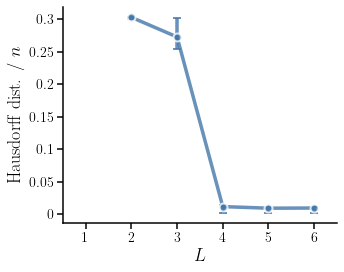

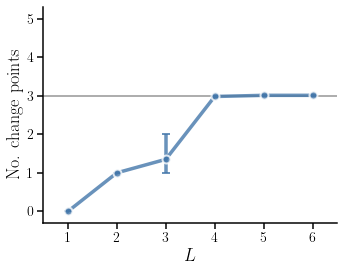

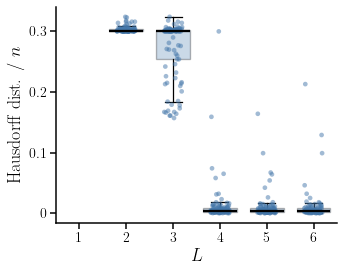

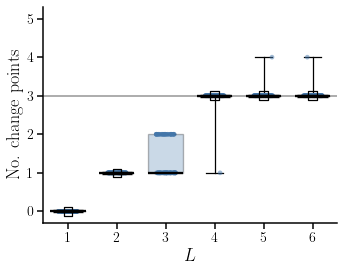

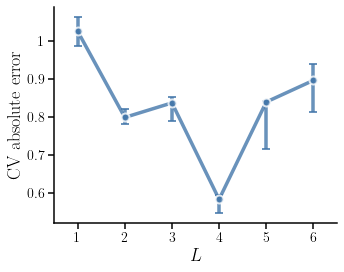

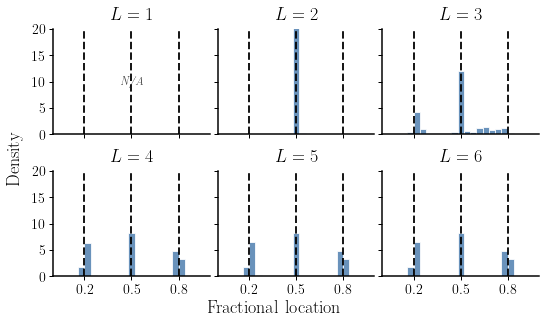

All figures use only n=1000,p=100. All bound-axis ticks are exactly 1,2,3,4,5,6.


In [2]:
# SELF-CONTAINED plotting cell. Gold-standard rcParams and box helpers copied
# verbatim from M3_upsample_final.ipynb; only labels/data dimensions differ.
import pickle, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator, FixedFormatter
plt.switch_backend('module://matplotlib_inline.backend_inline')
plt.rcParams.update({'pgf.texsystem': 'pdflatex', 'pgf.preamble': '\n        \\usepackage{amsmath}\n        \\usepackage{amsfonts}\n        \\usepackage{amssymb}\n        \\usepackage{siunitx}\n    ', 'font.size': 14, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'], 'text.usetex': True, 'axes.linewidth': 1.5, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14, 'legend.frameon': True, 'legend.fancybox': True, 'legend.edgecolor': 'black', 'legend.framealpha': 0.95, 'lines.linewidth': 4.0, 'lines.markersize': 8, 'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1})
_COLLAPSED_STYLES = {"line", "line_and_marker", "none"}
def get_asymmetric_errors(data):
    """Calculate asymmetric error bars using 25th and 75th percentiles, ignoring NaNs"""
    means = np.nanmean(data, axis=1)
    p25 = np.nanpercentile(data, 25, axis=1)
    p75 = np.nanpercentile(data, 75, axis=1)
    lower_errors = np.abs(means - p25)
    upper_errors = np.abs(p75 - means)
    return [lower_errors, upper_errors]

def _finite_1d(values):
    """Return a flattened float array containing only finite observations."""
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def _distribution_summary(values):
    """Compute the summaries used by all distribution-plotting modes."""
    values = _finite_1d(values)
    if values.size == 0:
        return None

    q05, q25, median, q75, q95 = np.percentile(
        values, [5, 25, 50, 75, 95]
    )
    data_scale = max(
        1.0,
        float(np.max(np.abs(values))),
        float(np.ptp(values)),
    )
    collapsed = np.isclose(
        q25,
        q75,
        rtol=1e-10,
        atol=1e-12 * data_scale,
    )

    return {
        "n": int(values.size),
        "n_unique": int(np.unique(values).size),
        "min": float(np.min(values)),
        "q05": float(q05),
        "q25": float(q25),
        "median": float(median),
        "q75": float(q75),
        "q95": float(q95),
        "max": float(np.max(values)),
        "iqr": float(q75 - q25),
        "collapsed": bool(collapsed),
    }

def _jittered_x(position, n, rng, jitter_width):
    """Generate reproducible horizontal jitter without changing y values."""
    if n <= 1 or jitter_width <= 0:
        return np.full(n, position, dtype=float)
    return position + rng.uniform(-jitter_width, jitter_width, size=n)

def _draw_raw_points(
    ax,
    values,
    position,
    color,
    rng,
    jitter_width=0.18,
    point_size=22,
    point_alpha=0.16,
):
    """Overlay all observations using x-only jitter."""
    x = _jittered_x(position, values.size, rng, jitter_width)
    ax.scatter(
        x,
        values,
        s=point_size,
        facecolor=color,
        edgecolor="none",
        alpha=point_alpha,
        zorder=4,
        clip_on=True,
        label="_nolegend_",
    )

def _draw_collapsed_iqr(
    ax,
    position,
    median,
    box_width,
    collapsed_style="line_and_marker",
):
    """
    Make a zero-IQR group visible without inventing a nonzero statistical box.

    The optional square is a display glyph only; it does not encode an interval.
    """
    if collapsed_style not in _COLLAPSED_STYLES:
        raise ValueError(
            f"collapsed_style must be one of {sorted(_COLLAPSED_STYLES)}, "
            f"got {collapsed_style!r}."
        )
    if collapsed_style == "none":
        return

    half_width = 0.43 * box_width
    ax.plot(
        [position - half_width, position + half_width],
        [median, median],
        color="black",
        linewidth=3.4,
        solid_capstyle="butt",
        zorder=7,
        label="_nolegend_",
    )

    if collapsed_style == "line_and_marker":
        ax.scatter(
            [position],
            [median],
            marker="s",
            s=72,
            facecolor="none",
            edgecolor="black",
            linewidth=1.25,
            zorder=8,
            label="_nolegend_",
        )

def _draw_box_jitter_group(
    ax,
    values,
    position,
    color,
    rng,
    summary,
    box_width,
    jitter_width,
    point_size,
    point_alpha,
    collapsed_style,
):
    """Draw one honest boxplot and overlay all observations."""
    bp = ax.boxplot(
        [values],
        positions=[position],
        widths=box_width,
        patch_artist=True,
        showfliers=False,       # every observation is shown by the scatter layer
        whis=1.5,
        autorange=True,         # if IQR=0, extend whiskers to min/max
        manage_ticks=False,
        medianprops={
            "color": "black",
            "linewidth": 2.3,
            "zorder": 6,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.35,
            "zorder": 2,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
        capprops={
            "color": "black",
            "linewidth": 1.25,
            "zorder": 2,
        },
    )

    patch = bp["boxes"][0]
    patch.set_facecolor(color)
    patch.set_alpha(0.28)
    patch.set_edgecolor("black")

    _draw_raw_points(
        ax=ax,
        values=values,
        position=position,
        color=color,
        rng=rng,
        jitter_width=jitter_width,
        point_size=point_size,
        point_alpha=point_alpha,
    )

    # Reinforce the statistical line when the box height is genuinely zero.
    if summary["collapsed"]:
        _draw_collapsed_iqr(
            ax=ax,
            position=position,
            median=summary["median"],
            box_width=box_width,
            collapsed_style=collapsed_style,
        )
# Plot ONLY the selected n=1000, p=100 experiment.
with Path('results/E_L_upper_bound_n1000_p100_gap10/study.pkl').open('rb') as handle:
    study = pickle.load(handle)
assert study['settings'] == [(1000, 100)]
rows = study['rows'][(1000, 100)]
assert len(rows) == 100 and all(r['n'] == 1000 and r['p'] == 100 for r in rows)
L_values = np.arange(1, 7)
blue = '#4477AA'
truth = np.array([.2, .5, .8])
figures_dir = Path('figures'); figures_dir.mkdir(exist_ok=True)
plot_audit = []
fmt = FuncFormatter(lambda value, pos: f'{value:.3f}'.rstrip('0').rstrip('.') if abs(value) > 1e-12 else '0')

def finish_axes(ax, ylabel):
    ax.set_xlabel(r'$L$', fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    # Fixed positions AND fixed labels, after drawing boxes: no Matplotlib-managed duplicates.
    ax.xaxis.set_major_locator(FixedLocator(L_values))
    ax.xaxis.set_major_formatter(FixedFormatter([str(L) for L in L_values]))
    ax.set_xlim(.5, 6.5)
    ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis='both', which='major', width=1.5, length=6, labelsize=14)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5); ax.spines['bottom'].set_linewidth(1.5)
    np.testing.assert_array_equal(ax.get_xticks(), L_values)
    assert [t.get_text() for t in ax.get_xticklabels()] == ['1','2','3','4','5','6']

def save_figure(fig, suffix):
    for extension in ['pdf','png','pgf']:
        fig.savefig(figures_dir / f'E_L_upper_bound_n1000_p100_gap10_{suffix}.{extension}', dpi=600 if extension == 'png' else None)
    fig.canvas.draw()
    plot_audit.append(dict(name=suffix,settings=dict(n=1000,p=100),figsize=list(fig.get_size_inches()),axes=[dict(
        xlabel=ax.get_xlabel(),ylabel=ax.get_ylabel(),title=ax.get_title(),
        xticks=ax.get_xticks().tolist(),xticklabels=[t.get_text() for t in ax.get_xticklabels()],
        xlabel_size=ax.xaxis.label.get_fontsize(),ylabel_size=ax.yaxis.label.get_fontsize(),
        ylim=list(ax.get_ylim())) for ax in fig.axes]))
    plt.show()

print('n=1000, p=100; Delta_n=n/10; 100 paired trials; 10-fold absolute-error CV.')
print('L | selected number of signals | correct-count frequency | empty frequency | Hausdorff dist. / n')
for L in L_values:
    fits=[r['fits'][int(L)] for r in rows]
    finite=[f['haus'] for f in fits if np.isfinite(f['haus'])]
    h=f'{np.mean(finite):.3f}' if finite else 'undefined'
    print(f'{L} | {np.mean([f["selected"] for f in fits]):.3f} | '
          f'{np.mean([f["correct_count"] for f in fits]):.3f} | '
          f'{np.mean([f["empty"] for f in fits]):.3f} | {h}')

# Same error-bar calculation and drawing syntax as the canonical gold plots.
for metric, ylabel, suffix in [('haus',r'Hausdorff dist. / $n$','location_asymmetric_errors'),
                              ('change_points','No. change points','change_points_asymmetric_errors')]:
    values=np.array([[(r['fits'][int(L)]['selected']-1 if metric=='change_points' else r['fits'][int(L)][metric]) for r in rows] for L in L_values],float)
    keep=np.isfinite(values).any(axis=1)
    fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
    means=np.nanmean(values[keep],axis=1)
    errors=get_asymmetric_errors(values[keep])
    ax.errorbar(L_values[keep],means,yerr=errors,marker='o',ls='-',color=blue,
                capsize=4,capthick=2,markersize=8,linewidth=3.5,
                markeredgewidth=2,markeredgecolor='white',alpha=.8)
    finish_axes(ax,ylabel)
    if metric=='change_points':
        ax.set_yticks([0,1,2,3,4,5]);ax.set_ylim(-.3,5.3)
        ax.axhline(3,color='gray',linewidth=1.5,alpha=.85,zorder=0)
    fig.tight_layout();save_figure(fig,suffix)

# Literally copied gold-standard box/jitter renderer (manage_ticks=False).
for metric,ylabel,suffix in [('haus',r'Hausdorff dist. / $n$','location_boxplots'),
                            ('change_points','No. change points','change_points_boxplots')]:
    fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
    rng=np.random.default_rng(2026)
    for L in L_values:
        values=_finite_1d([r['fits'][int(L)]['selected']-1 if metric=='change_points' else r['fits'][int(L)][metric] for r in rows])
        summary=_distribution_summary(values)
        if summary is None:continue
        _draw_box_jitter_group(ax=ax,values=values,position=float(L),color=blue,rng=rng,
            summary=summary,box_width=.72,jitter_width=.20,point_size=22,
            point_alpha=.50,collapsed_style='line_and_marker')
    finish_axes(ax,ylabel)
    if metric=='change_points':
        ax.set_yticks([0,1,2,3,4,5]);ax.set_ylim(-.3,5.3)
        ax.axhline(3,color='gray',linewidth=1.5,alpha=.85,zorder=0)
    fig.tight_layout();save_figure(fig,suffix)

# Retained score diagnostic, restricted to the same selected setting.
scores=np.array([r['fits'][6]['scores'] for r in rows])/1000
fig,ax=plt.subplots(1,1,figsize=(5.0,4.0))
ax.errorbar(L_values,scores.mean(axis=0),yerr=get_asymmetric_errors(scores.T),
    marker='o',ls='-',color=blue,capsize=4,capthick=2,markersize=8,
    linewidth=3.5,markeredgewidth=2,markeredgecolor='white',alpha=.8)
finish_axes(ax,'CV absolute error')
fig.tight_layout();save_figure(fig,'cv_scores')

# Larger, spaced histogram panels:25 bins, white edges, black dashed truths; no KDE.
fig,axes=plt.subplots(2,3,figsize=(2.5*3,2.2*2),sharex=True,sharey=True,
    gridspec_kw={'wspace':.05,'hspace':.35})
fig.patch.set_facecolor('white')
for ax,L in zip(axes.flat,L_values):
    pooled=np.concatenate([np.asarray(r['fits'][int(L)]['cp'])/1000 for r in rows])
    ax.set_facecolor('white')
    if len(pooled):
        ax.hist(pooled,bins=np.linspace(0,1,26),alpha=.8,color=blue,
            density=True,edgecolor='white',linewidth=1.0)
    else:
        ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,ha='center',va='center',fontsize=12,alpha=.7,style='italic')
    for boundary in truth:ax.axvline(boundary,color='black',linestyle='--',linewidth=2,alpha=.9,zorder=10)
    ax.set_title(rf'$L={L}$',fontsize=18,pad=10)
    ax.set_xlim(0,1)
    ax.set_xticks(truth);ax.set_xticklabels([r'$0.2$',r'$0.5$',r'$0.8$'],fontsize=14)
    ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis='both',which='major',width=1,length=4,labelsize=14)
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5);ax.spines['bottom'].set_linewidth(1.5)
    assert ax.get_title()==rf'$L={L}$' and 'empty' not in ax.get_title()
# Requested common density range; histogram-only display.
axes[0,0].set_ylim(0,20)
axes[0,0].set_yticks([0,5,10,15,20])
fig.text(.5,.005,'Fractional location',ha='center',va='bottom',fontsize=18)
fig.text(.005,.5,'Density',va='center',rotation='vertical',fontsize=18)
fig.subplots_adjust(left=.09,right=.99,bottom=.13,top=.91)
save_figure(fig,'changepoint_histograms')
with Path('results/E_L_upper_bound_n1000_p100/plot_audit.json').open('w') as handle:
    json.dump(plot_audit,handle,indent=2)
print('All figures use only n=1000,p=100. All bound-axis ticks are exactly 1,2,3,4,5,6.')


## Updated consistent plots

Plotting reference: **Canonical M1 tighter-layout plots (alpha = 0.3)** in `M1_upsample_final.ipynb`. Error-bar plots use its 5 by 4 inch canvas, 18 pt axis labels and 14 pt ticks; among Hausdorff, count and runtime comparisons, only Runtime displays a legend. These cells load saved results only; the original experiment and plotting cells above are unchanged. Run the setup below, then the desired plotting cell. PDFs and PNGs are saved under `results/consistent_plots_20261102/E_L_upper_bound/`.

Line summaries retain their original statistic (quartile-distance bars, or mean ± SE where stated); boxplots use 1.5-IQR whiskers and faint deterministic trial jitter. Histograms follow canonical M1: 12 data-range bins, five-fold bandwidth-selected Gaussian KDE, grey overlay, truth-position ticks, and density range 0–18. These histogram display choices can differ from the older plots; the samples do not change. Empty estimates are omitted from conditional localization and pooled location densities, not assigned zero error. Histograms retain every selected setting and method in one grid, with no three-row or three-column cap: 2.5 inches per column and 2.2 inches per row, matching the reference. Other diagnostic plots retain their compact presentation.

In [1]:
"""Approved publication style; also embedded verbatim in final notebook cells.

Only plotting helpers live here. All data choices and plot calls are visible in
the notebook cells. No fitting, simulation, CV for estimators, or job submission.
Histogram KDE bandwidth CV is the canonical M1 visualization procedure.
"""
from pathlib import Path
import hashlib
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from IPython.display import display, Image

PAPER_WIDTH = 427.64493 / 72.27
PANEL_WIDTH = .49 * PAPER_WIDTH
SCALE = 10.5 / 18
PAPER_STYLE = {
    'text.usetex': True, 'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'], 'font.size': 8.5,
    'axes.labelsize': 10.5, 'axes.titlesize': 10.5,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8,
    'axes.linewidth': .85, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'xtick.major.width': .85, 'ytick.major.width': .85,
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
    'savefig.bbox': None, 'figure.dpi': 120, 'savefig.dpi': 180,
    'figure.autolayout': False, 'figure.constrained_layout.use': False,
    'legend.frameon': False, 'axes.formatter.useoffset': False,
    'text.latex.preamble': '', 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}

# Reference: M1_upsample_final, "Canonical M1 tighter-layout plots (alpha=0.3)".
# Keep this separate from the compact style used for unrelated diagnostic plots.
CANONICAL_STYLE = {
    **PAPER_STYLE,
    'font.size': 14, 'axes.labelsize': 18, 'axes.titlesize': 18,
    'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14,
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'legend.frameon': True, 'legend.fancybox': True,
    'legend.edgecolor': 'black', 'legend.framealpha': .95,
    'lines.linewidth': 4, 'lines.markersize': 8,
    'figure.dpi': 72, 'savefig.dpi': 300, 'savefig.pad_inches': .1,
}

METHODS = {
    'McScan': ('McScan', '#AA3377', 'o', '--'),
    'MOSEG': ('MOSEG', '#228833', 's', '-.'),
    'DCDP': ('DCDP', '#EE6677', 'X', '--'),
    'DPDU': ('DPDU', '#4477AA', 'P', ':'),
    'charcoal': ('charcoal', '#336677', 'v', '-.'),
    'GLMBSA-CV': ('GLMBSA', '#E69F00', 'p', ':'),
    'WERM-unp': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-unp-10fold': (r'\textbf{WERM}', 'black', 'D', '-'),
    'WERM-L1-jointCV': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
    'WERM-L1-fullCV-2fold': (r'\textbf{WERM+L1}', 'black', 'D', '-'),
}
SOURCE_HASHES, FIGURE_AUDIT = {}, []
KDE_CACHE = {}

def load_saved(filename):
    path = Path(filename)
    raw = path.read_bytes()  # fail explicitly if a result is missing; no dummy data
    SOURCE_HASHES[str(path)] = hashlib.sha256(raw).hexdigest()
    return pickle.loads(raw)

def clean(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]

def paper_panel(full=False, height=2.05):
    fig, ax = plt.subplots(figsize=(PAPER_WIDTH if full else PANEL_WIDTH, height))
    fig.subplots_adjust(left=.11 if full else .19, right=.98, bottom=.23, top=.97)
    ax.yaxis.set_major_locator(MaxNLocator(4))
    return fig, ax

def export_plot(fig, name, description=''):
    """Export PDF + embedded PNG, retaining canonical geometry and input hashes."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    canonical = getattr(fig, '_canonical_m1', False)
    bounds = fig.get_tightbbox(renderer).padded(.1) if canonical else fig.bbox_inches
    pixels = bounds.transformed(fig.dpi_scale_trans)
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer)
        if bbox is not None:
            assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2, (name, 'left/bottom clipping', bbox)
            assert bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'right/top clipping', bbox)
    for text in fig.texts:
        bbox = text.get_window_extent(renderer)
        assert bbox.x0 >= pixels.x0-2 and bbox.y0 >= pixels.y0-2 and bbox.x1 <= pixels.x1+2 and bbox.y1 <= pixels.y1+2, (name, 'figure text clipping')
    fig.savefig(OUTPUT_DIR / f'{name}.pdf', bbox_inches=bounds)
    fig.savefig(OUTPUT_DIR / f'{name}.png', bbox_inches=bounds)
    FIGURE_AUDIT.append(dict(name=name, description=description,
        size_inches=[bounds.width, bounds.height],
        canvas_inches=fig.get_size_inches().tolist(),
        canonical_m1=canonical,
        legends=sum(a.get_legend() is not None for a in fig.axes)+len(fig.legends),
        axes=[dict(bounds=list(a.get_position().bounds), xlabel=a.get_xlabel(),
                   ylabel=a.get_ylabel(), title=a.get_title(), ylim=list(a.get_ylim())) for a in fig.axes]))
    print(description or name)
    display(Image(filename=str(OUTPUT_DIR / f'{name}.png')))
    plt.close(fig)
    (OUTPUT_DIR/'manifest.json').write_text(json.dumps(dict(
        style=PAPER_STYLE, sources=SOURCE_HASHES, figures=FIGURE_AUDIT), indent=2))

def verify_sources():
    for path, digest in SOURCE_HASHES.items():
        assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
    print(f'Exported {len(FIGURE_AUDIT)} figures to {OUTPUT_DIR}; saved inputs unchanged.')

def error_series(ax, x, groups, label, color='black', marker='D', ls='-', error='quartile', scale=SCALE):
    xplot, means, low, high = [], [], [], []
    for xx, group in zip(x, groups):
        v = clean(group)
        if not len(v):
            continue
        mean = v.mean()
        if error == 'se':
            lo = hi = v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else 0
        else:
            q25, q75 = np.percentile(v, [25,75])
            lo, hi = abs(mean-q25), abs(q75-mean)
        xplot.append(xx); means.append(mean); low.append(lo); high.append(hi)
    ax.errorbar(xplot,means,yerr=[low,high],label=label,color=color,marker=marker,ls=ls,
        linewidth=3.5*scale,markersize=8*scale,capsize=4*scale,capthick=2*scale,
        markeredgewidth=2*scale,markeredgecolor='white',alpha=.8)

def box_group(ax, values, position, color, rng, width=.65, jitter=.19):
    v=clean(values)
    if not len(v):
        return
    bp=ax.boxplot([v],positions=[position],widths=width,patch_artist=True,
        showfliers=False,whis=1.5,autorange=True,manage_ticks=False,
        medianprops=dict(color='black',linewidth=2.3*SCALE,zorder=6),
        boxprops=dict(color='black',linewidth=1.35*SCALE),
        whiskerprops=dict(color='black',linewidth=1.25*SCALE),
        capprops=dict(color='black',linewidth=1.25*SCALE))
    bp['boxes'][0].set(facecolor=color,alpha=.28)
    ax.scatter(position+rng.uniform(-jitter,jitter,len(v)),v,s=3,alpha=.12,
               color=color,linewidths=0,zorder=4)
    q25,med,q75=np.percentile(v,[25,50,75])
    if np.isclose(q25,q75,rtol=1e-10,atol=1e-12*max(1.,np.max(np.abs(v)))):
        ax.plot([position-.43*width,position+.43*width],[med,med],
                color='black',lw=3.4*SCALE,zorder=7)

def histogram_grid(groups, titles, colors, truth, name, row_labels=None,
                   panel_titles=None, density_limit=18, density_label_x=.07):
    """Canonical M1 histogram grid with every selected row and method column.

    groups[row][column] contains pooled fractional change-point estimates.
    Uses the exact M1 12-bin/data-range and five-fold Gaussian-KDE setup.
    The fixed canonical density range is retained; clipped peaks are reported.
    """
    with plt.rc_context(CANONICAL_STYLE):
        rows, cols=len(groups),len(titles)
        assert rows>=1 and cols>=1 and all(len(g)==cols for g in groups)
        fig, axes=plt.subplots(rows,cols,figsize=(2.5*cols,2.2*rows),
            sharex=True,sharey=True,squeeze=False,
            gridspec_kw=dict(wspace=.05,hspace=.55 if panel_titles and rows>1 else .08))
        fig._canonical_m1 = True
        peak=0.
        for row in range(rows):
            for col in range(cols):
                ax=axes[row,col]; values=clean(groups[row][col])
                assert np.all((values>=0)&(values<=1)), 'Histogram expects fractional locations'
                if len(values):
                    hist, edges, _=ax.hist(values,bins=12,alpha=.8,color=colors[col],
                        density=True,edgecolor='white',linewidth=1.0)
                    assert np.isclose(np.sum(hist*np.diff(edges)),1)
                    peak=max(peak,float(hist.max()))
                    if len(values)>6:
                        key=hashlib.sha256(values.tobytes()).hexdigest()
                        if key not in KDE_CACHE:
                            cv=GridSearchCV(KernelDensity(kernel='gaussian'),
                                {'bandwidth':np.logspace(-2,0,50)},cv=5,n_jobs=1)
                            cv.fit(values.reshape(-1,1))
                            x=np.linspace(0,1,200)
                            KDE_CACHE[key]=(x,np.exp(cv.best_estimator_.score_samples(x.reshape(-1,1))))
                        x,y=KDE_CACHE[key]
                        ax.plot(x,y,color='#555555',lw=1.0,ls='-',alpha=.8,zorder=2)
                        ax.fill_between(x,y,color='#999999',alpha=.2,zorder=1)
                        peak=max(peak,float(y.max()))
                else:
                    ax.text(.5,.5,r'\textit{N/A}',transform=ax.transAxes,
                        ha='center',va='center',fontsize=12,alpha=.7)
                for cp in truth:
                    ax.axvline(cp,color='black',ls='--',lw=2,alpha=.9,zorder=10)
                ax.set(xlim=(0,1),ylim=(0,density_limit))
                ax.set_xticks(truth,[f'${cp:.2f}$' for cp in truth])
                ax.set_yticks([0,8,16] if density_limit==18 else [0,density_limit/2,density_limit])
                ax.tick_params(width=1,length=4,labelsize=14)
                for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1)
                if row==0 or panel_titles:
                    ax.set_title(panel_titles[row][col] if panel_titles else titles[col],
                                 fontsize=18,pad=10)
                if col==cols-1 and row_labels:
                    ax.text(1.05,.5,row_labels[row],transform=ax.transAxes,rotation=90,
                        va='center',ha='left',fontsize=18)
        fig.text(.5,.01,'Fractional location',ha='center',va='bottom',fontsize=18)
        fig.text(density_label_x,.5,'Density',va='center',rotation='vertical',fontsize=18)
        fig.tight_layout(rect=[.03,.05,.96,.96])
        # Keep the shared x label clear of tick labels in shorter grids.
        if rows==1:fig.subplots_adjust(bottom=.28,top=.78)
        elif rows==2:fig.subplots_adjust(bottom=.16)
        if peak>density_limit:
            print(f'{name}: maximum density {peak:.2f}; canonical display limit {density_limit} (peaks above this are clipped).')
        export_plot(fig,name,'Change-point location histograms: canonical M1 bins, KDE, ticks and layout.')

def comparison_plots(filename, prefix, methods, min_x=None, m3=False,
                     histogram_stride=3, metrics=('haus','size','runtime'), histograms=True):
    payload=load_saved(filename); results,params=payload['results'],payload['params']
    raw_x=np.asarray(params['kappa_list'] if m3 else params['delta_list'])
    keep=np.flatnonzero(raw_x>=min_x) if min_x is not None else np.arange(len(raw_x))
    x=raw_x[keep]**2 if m3 else raw_x[keep]
    xlabel=r'$\kappa^2$' if m3 else r'$\delta=n/p$'
    truth=np.asarray(params['fractional_chgpt_locations'])
    values={}
    for method in methods:
        sizes=np.asarray(results['size_'+method],float)[keep]
        assert sizes.shape[1]==params['num_trials']
        for metric in metrics:
            v=(np.abs(sizes-len(truth)) if metric=='size_error' else
               np.asarray(results[metric+'_'+method],float)[keep].copy())
            if metric=='haus':v=np.where(sizes>0,v,np.nan)
            if metric=='size_error':v=np.abs(sizes-len(truth))
            values[metric,method]=v
    for metric in metrics:
        ylabel={'haus':r'Hausdorff dist. / $n$','size':'No. change points',
                'runtime':'Runtime (s)','size_error':'Set size error'}[metric]
        for kind in ('line','box'):
            with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5.,4.))
                    fig._canonical_m1 = True
                else:
                    fig,ax=paper_panel()
                rng=np.random.default_rng(42)
                handles=[]
                for j,method in enumerate(methods):
                    label,color,marker,ls=METHODS[method];v=values[metric,method]
                    if kind=='line':
                        error_series(ax,x,v,label,color,marker,ls,scale=1)
                    else:
                        for k,g in enumerate(v):box_group(ax,g,k*(len(methods)+1)+j,color,rng)
                        handles.append(Patch(facecolor=color,alpha=.28,edgecolor='black',label=label))
                if kind=='line':
                    if m3:
                        # Preserve the canonical M3 logarithmic kappa-squared axis.
                        ax.set_xscale('log')
                        ax.set_xticks([10,100,1000],['10','100','1000'])
                        ax.xaxis.set_minor_formatter(NullFormatter())
                    else:
                        ax.set_xticks(x[::2],[f'{xx:g}' for xx in x[::2]])
                else:
                    ax.set_xticks(np.arange(len(x))[::2]*(len(methods)+1)+(len(methods)-1)/2,
                                  [f'{xx:.0f}' if m3 else f'{xx:g}' for xx in x[::2]])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='size':
                    ax.axhline(len(truth),color='gray',lw=2.5*(1 if kind=='line' else SCALE),alpha=.8,zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4,integer=True));ax.set_ylim(bottom=-.15)
                    if m3:
                        ax.set_ylim(0,params['L']);ax.set_yticks(np.arange(params['L']+1))
                elif metric=='size_error':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
                elif metric=='runtime':ax.set_ylim(bottom=0)
                if metric == ('size' if m3 else 'runtime'):
                    ax.legend(handles=handles if kind=='box' else None,loc='best',
                              prop={'size':14 if kind=='line' else 8},
                              fancybox=True,framealpha=.4)
                if kind=='line':
                    ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
                    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
                    for spine in ('left','bottom'):ax.spines[spine].set_linewidth(1.5)
                    fig.tight_layout()
                export_plot(fig,f'{prefix}_{metric}_{kind}',
                    f'{prefix}: {ylabel}; '+('mean and absolute distances to quartiles' if kind=='line' else 'boxplots with faint trial jitter'))
    if not histograms:return
    # Preserve all selected settings and methods in one canonical grid.
    row_idx=keep[::histogram_stride]
    keys=list(reversed(methods));groups=[]
    for index in row_idx:
        n=int(params['p']*(params['fixed_delta'] if m3 else raw_x[index]))
        group=[]
        for key in keys:
            parts=[np.asarray(cps).ravel() for i,cps in results['chgpts_'+key] if i==index]
            cp=np.concatenate(parts) if parts else np.array([])
            group.append(cp[cp!=-1]/n)
        groups.append(group)
    histogram_grid(groups,[METHODS[k][0] for k in keys],[METHODS[k][1] for k in keys],truth,
        f'{prefix}_hist',
        [rf'$\kappa^2={raw_x[i]**2:.0f}$' if m3 else rf'$\delta={raw_x[i]:g}$' for i in row_idx])


def simple_summary(groups, x, xlabel, ylabel, name, colors=None, error='quartile',
                   kind='box', labels=None, truth=None, title=None):
    with plt.rc_context(CANONICAL_STYLE if kind=='line' else PAPER_STYLE):
        canonical = kind=='line'
        fig,ax=plt.subplots(figsize=(5.,4.)) if canonical else paper_panel()
        fig._canonical_m1 = canonical
        colors=colors or ['black']*len(x)
        if kind=='line':error_series(ax,x,groups,'',error=error,scale=1)
        else:
            rng=np.random.default_rng(42)
            for xx,g,color in zip(x,groups,colors):box_group(ax,g,xx,color,rng,width=.55,jitter=.16)
        ax.set_xticks(x,labels or [str(xx) for xx in x])
        ax.set(xlabel=xlabel,ylabel=ylabel)
        if truth is not None:ax.axhline(truth,color='gray',lw=2.5*(1 if canonical else SCALE),alpha=.8,zorder=0)
        if title:
            fig.subplots_adjust(top=.86)
            ax.set_title(title,pad=4)
        if ylabel=='No. change points':ax.yaxis.set_major_locator(MaxNLocator(4,integer=True))
        if canonical:
            ax.tick_params(axis='both',which='major',width=1.5,length=6,labelsize=14)
            fig.tight_layout()
        export_plot(fig,name)

OUTPUT_DIR=Path('results/consistent_plots_20261102/E_L_upper_bound')


### Upper-bound sensitivity: n = 1000, p = 100

upper_L_haus_line


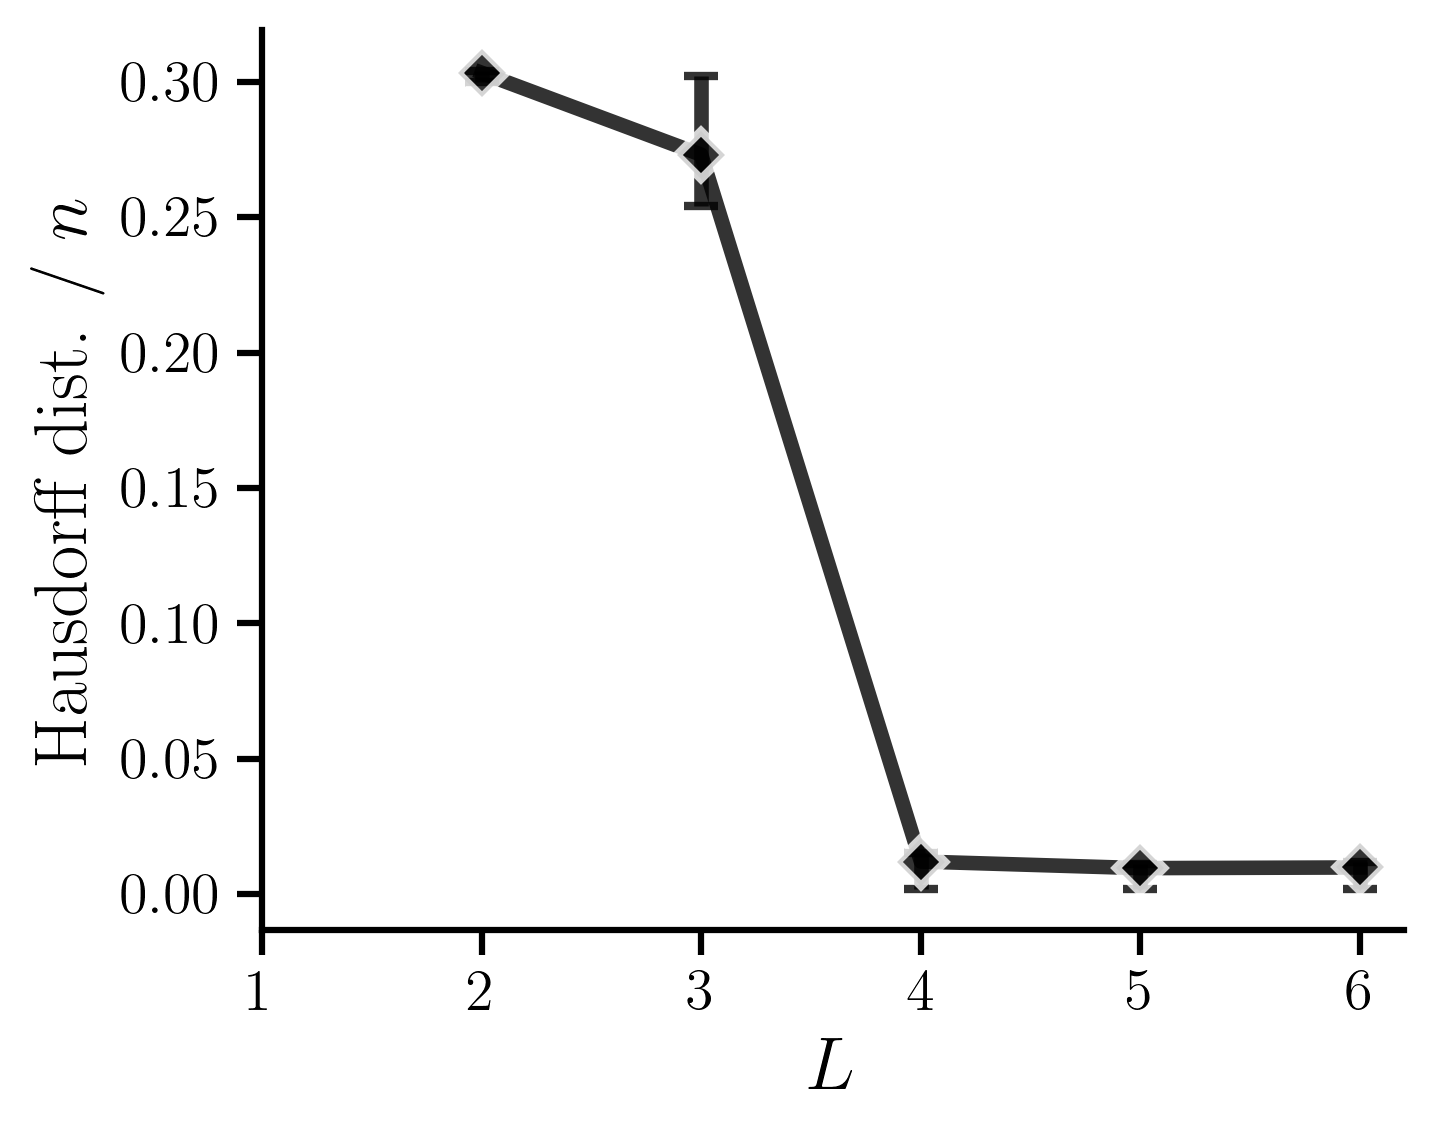

upper_L_haus_box


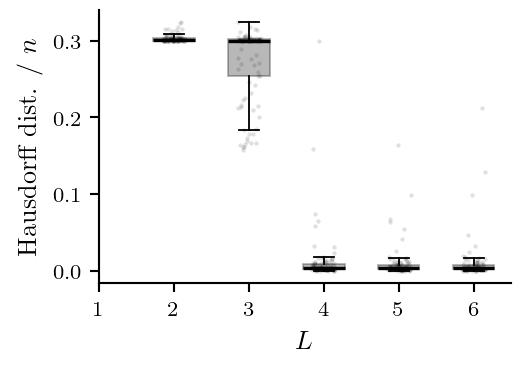

upper_L_count_line


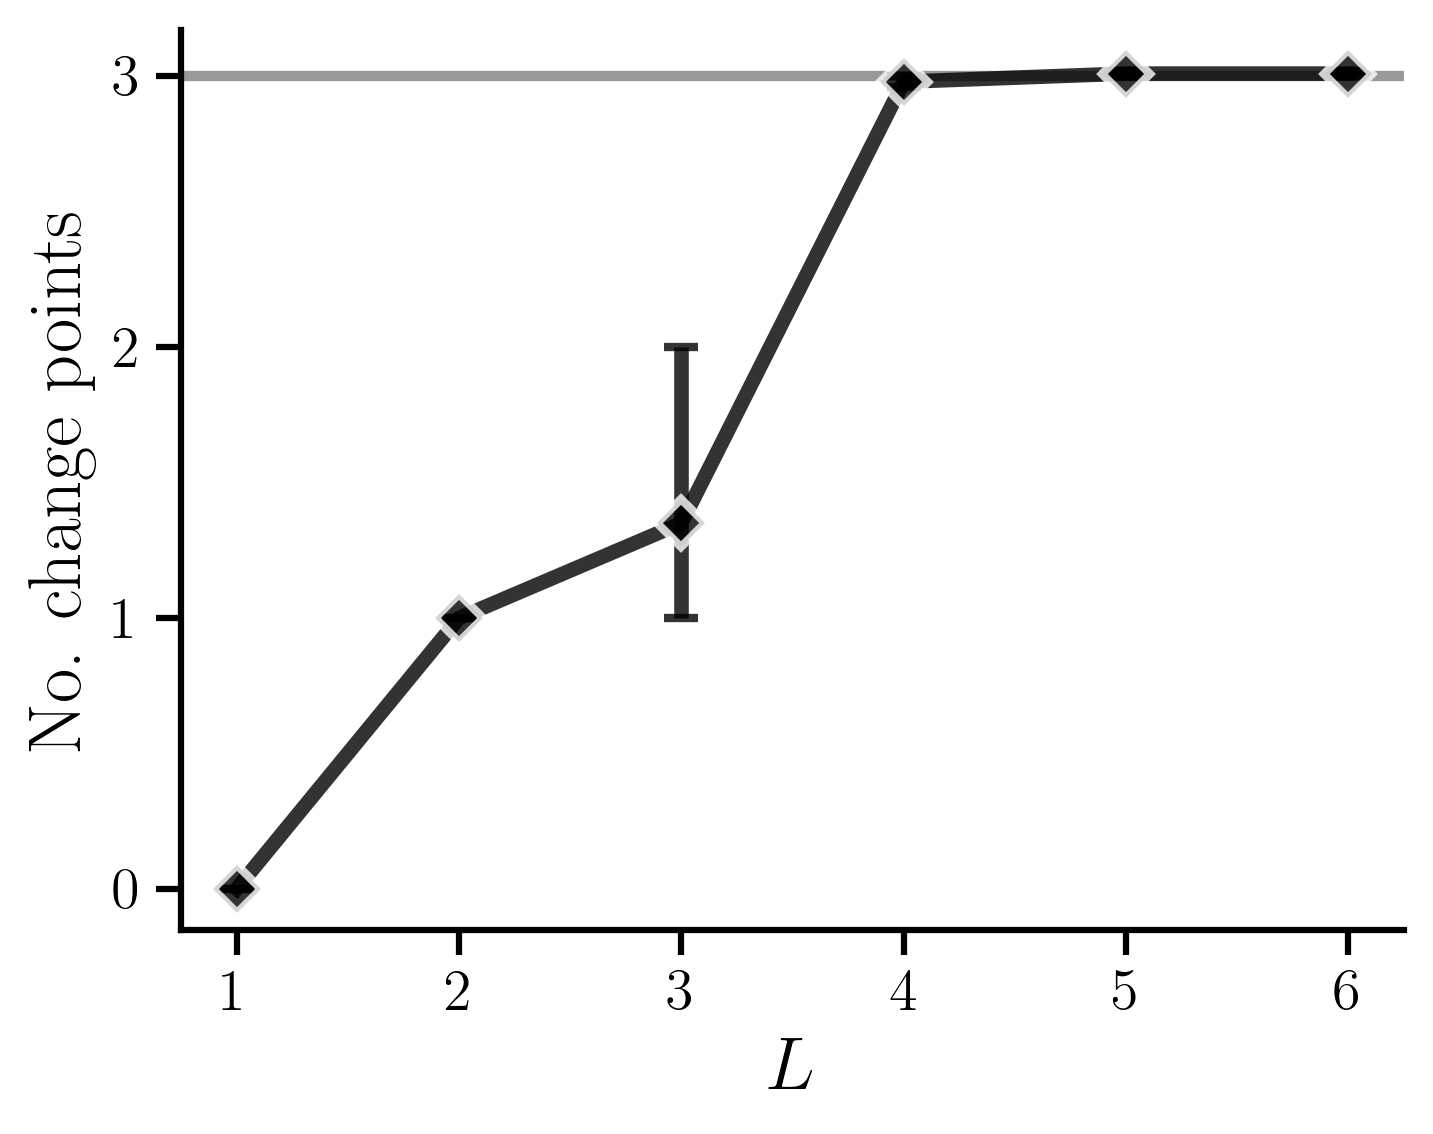

upper_L_count_box


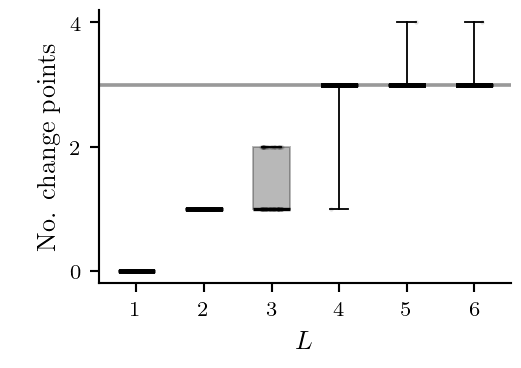

upper_L_cv_scores


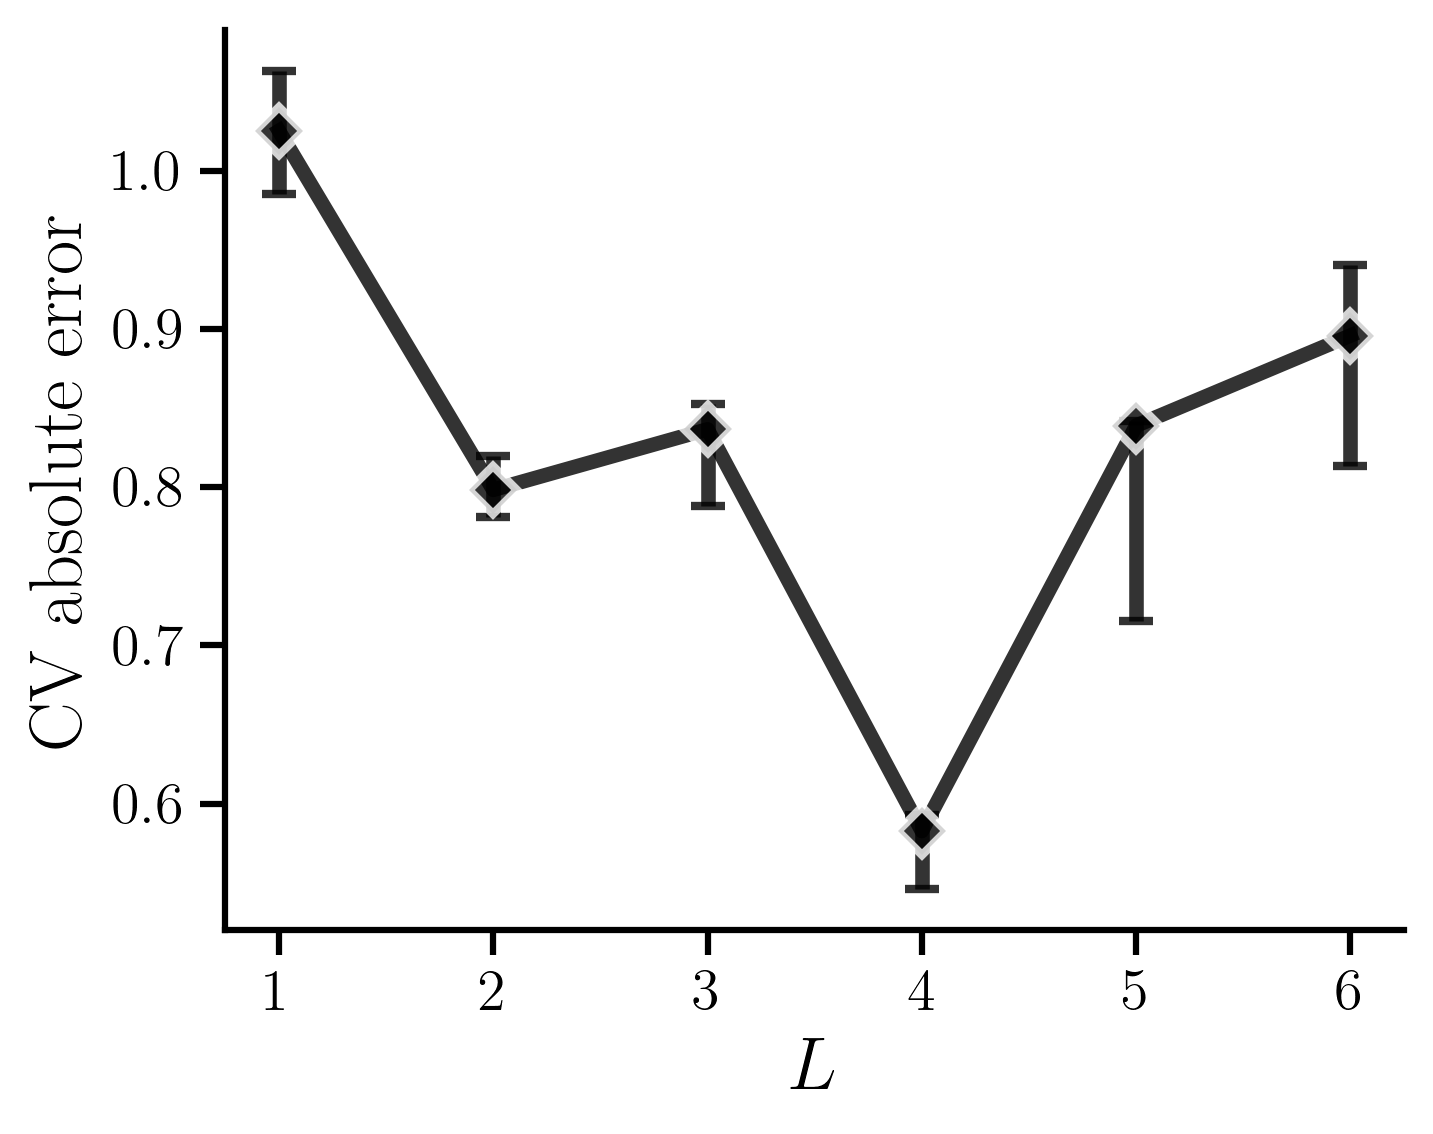

/tmp/ipykernel_709799/3143913581.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


upper_L_histograms: maximum density 135.32; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


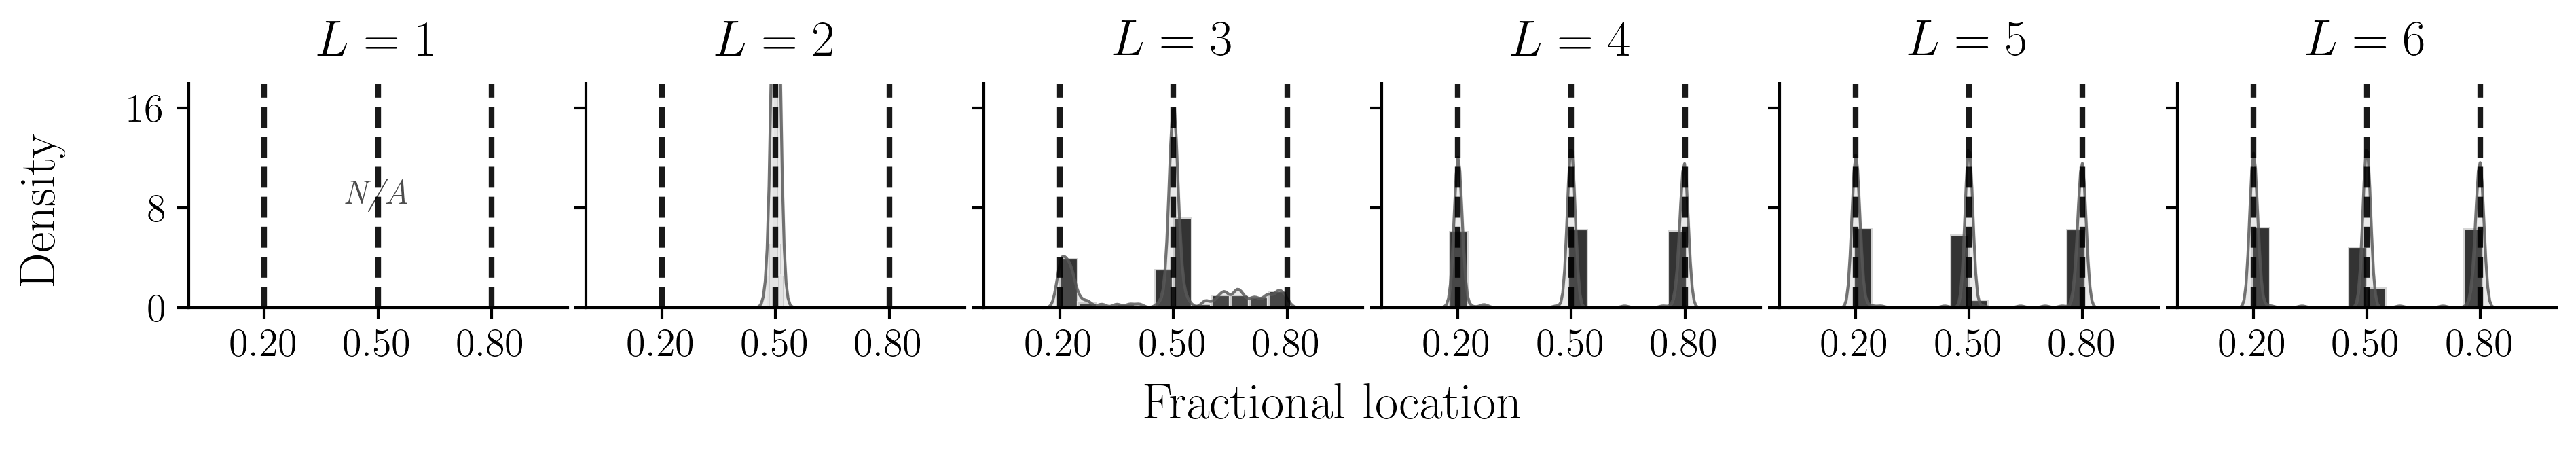

In [2]:
study=load_saved('results/E_L_upper_bound_n1000_p100_gap10/study.pkl')
assert study['settings']==[(1000,100)]
rows=study['rows'][(1000,100)];assert len(rows)==100
Ls=np.arange(1,7);truth=np.array([.2,.5,.8])
with plt.rc_context(PAPER_STYLE):
    for metric,ylabel in [('haus',r'Hausdorff dist. / $n$'),('count','No. change points')]:
        groups=[[r['fits'][int(L)]['selected']-1 if metric=='count' else r['fits'][int(L)]['haus'] for r in rows] for L in Ls]
        for kind in ('line','box'):
            simple_summary(groups,Ls,r'$L$',ylabel,f'upper_L_{metric}_{kind}',kind=kind,
                           truth=3 if metric=='count' else None)
    scores=np.array([r['fits'][6]['scores'] for r in rows])/1000
    simple_summary(scores.T,Ls,r'$L$','CV absolute error','upper_L_cv_scores',kind='line')
    pools=[np.concatenate([np.asarray(r['fits'][int(L)]['cp'])/1000 for r in rows]) for L in Ls]
    histogram_grid([pools],['']*len(Ls),['black']*len(Ls),truth,'upper_L_histograms',
                   panel_titles=[[rf'$L={L}$' for L in Ls]])

In [3]:
verify_sources()

Exported 6 figures to results/consistent_plots_20261102/E_L_upper_bound; saved inputs unchanged.


## Search-penalty count selection: empirical WERM and state evolution

This additional study retains the existing **$n=1000$, $p=100$, 100 paired trials**,
Gaussian data generator, base seed 20261120, noise standard deviation 0.5,
and three true changes at $(0.2,0.5,0.8)n$ ($L^\star=4$).
The CV results above remain a separate experiment.

For each upper bound $L\in\{1,\ldots,6\}$, fit the $L$ unpenalized weighted
least-squares regressions **once**, with upper-bound occupancy weights from a
uniform prior on segment counts $1,\ldots,L$ and a conditional uniform location prior.
Then minimize
$$\sum_{i=1}^n \frac12(y_i-\hat\theta_{i,\psi_i})^2
+6\log\binom{n-1}{K-1},\qquad 1\le K\le L.$$
This is the exact search penalty from `E_search_penalty.ipynb`, with **$\gamma=6$**
as requested, matching that notebook's frozen M3 multiplier. It is used here
without calibration against this study's CV or true counts. Coefficients are
not refitted at each candidate $K$; the search uses the first $K$ of the $L$ fits.
The internal-boundary separation is $n/10$; as in the native DP, end segments need
only be nonempty. There is **no CV and no adjusted-WERM search** in these additions.

Native marginal interpolation uses the same 50-point reference grid (gap 5),
with seed 0 and frozen weights shared by empirical WERM and theory.
The empirical data exactly reproduce the existing study's data generator.
All original cells and outputs above are preserved.

### SE equations and the distinction between true and fitted dimensions

Use the squared-loss specialization in `JRSSB_v2.tex`,
`eq:ls-b-linear-model`–`eq:ls-kappa-linear-model`, equivalently the general
fixed-point equations `eq:b-fp-implicit`–`eq:cross-cov-fp-implicit`.
For **half-squared** loss, solve
$$\frac1n\sum_i(1+b_\ell\pi_i^{(\ell)})^{-1}=1-\delta^{-1},
\qquad \omega_{i\ell}=\frac{b_\ell\pi_i^{(\ell)}}{1+b_\ell\pi_i^{(\ell)}}.$$
The factor 2 in the paper's unhalved squared loss is absorbed into $b$; the resulting
$\omega$, bias matrix and covariance are unchanged by this loss rescaling.
Keep all four true regimes, even when $L<4$: $\Gamma=B^\top B/n$ is $4\times4$,
$\Lambda$ is $4\times L$, and $K$ is $L\times L$. With $e_r\in\mathbb R^4$,
$$\lambda_\ell=\frac\delta n\sum_i\omega_{i\ell}e_{\Psi_i},\qquad
s_{\ell m}=\frac\delta n\sum_i\omega_{i\ell}\omega_{im},$$
$$K_{\ell m}=\frac{\frac\delta n\sum_i\omega_{i\ell}\omega_{im}
(\lambda_\ell-e_{\Psi_i})^\top\Gamma(\lambda_m-e_{\Psi_i})+s_{\ell m}\sigma^2}
{1-s_{\ell m}}.$$
These finite-sum equations compute the SE parameters directly after scalar root solves;
they do not use a low-dimensional population regression in place of SE.
The rectangular form retains the original four-state response law rather than
discarding true regimes when fitting fewer columns. This is a numerical study of
that extension, not a new proof of a misspecification theorem.

Independently of the empirical design and noise, draw $Z_i\sim N(0,\Gamma)$,
$G_i\sim N(0,K)$, and $\varepsilon_i^{\rm SE}\sim N(0,0.5^2)$; set
$$y_i^{\rm SE}=Z_{i,\Psi_i}+\varepsilon_i^{\rm SE},\qquad
\theta_{i\ell}^{\rm SE}=(1-\omega_{i\ell})(Z_i^\top\lambda_\ell+G_{i\ell})
+\omega_{i\ell}y_i^{\rm SE}.$$
Apply **the identical penalized or fixed-count partition search** to these proximal
fits and synthetic responses. This is the fitted-$\Theta$ representation in the
paper, not its adjusted-$\Theta$ representation.

Theory uses the oracle signal-strength matrix only to evaluate predictions;
the empirical estimator never receives it, the true count, or the true locations.
There are 20 independent SE draws for each of the 100 signal matrices, giving
2,000 theory realizations per setting. No empirical estimate or selected count
is supplied to the theory search. These are finite-size SE predictions; agreement
is assessed from the output, not enforced.

In [1]:
# Self-contained setup: run here without executing any original CV cells.
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from tools.el_state_evolution import prepare, run, summary, MODES
SE_ROOT, SE_SPEC, SE_WEIGHTS = prepare(trials=100,theory_draws=20,penalty_weight=6.)
print('SE experiment directory:',SE_ROOT)
# Shared trial job computes both sections; validated checkpoints are reused.
SE_STUDY = run(SE_ROOT,SE_SPEC,SE_WEIGHTS,jobs=int(os.environ.get('EL_SE_JOBS','12')))
SE_SUMMARY = summary(SE_STUDY)
display(SE_SUMMARY[SE_SUMMARY['mode']=='penalty'].round(4))

SE experiment directory: results/E_L_SE_penalty_fixed/982fa979e869


[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    1.7s
[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    1.9s
[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    1.9s


[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    1.9s
[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:    2.0s
[Parallel(n_jobs=12)]: Batch computation too fast (0.1941181799846847s.) Setting batch_size=2.
[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    2.0s


[Parallel(n_jobs=12)]: Done  62 tasks      | elapsed:    2.2s
[Parallel(n_jobs=12)]: Batch computation too fast (0.18279767036437988s.) Setting batch_size=4.
[Parallel(n_jobs=12)]: Done  77 out of 100 | elapsed:    2.2s remaining:    0.7s
[Parallel(n_jobs=12)]: Done  88 out of 100 | elapsed:    2.2s remaining:    0.3s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    2.3s finished


,mode,fitted_segments,x,source,draws,empty,mean_count,correct_count,mean_haus,median_haus
0,penalty,1,1,empirical,100,100,0.000,0.0000,NaN,NaN
1,penalty,1,1,theory,2000,2000,0.000,0.0000,NaN,NaN
2,penalty,2,2,empirical,100,0,1.000,0.0000,0.3041,0.3020
3,penalty,2,2,theory,2000,0,1.000,0.0000,0.3046,0.3020
4,penalty,3,3,empirical,100,0,2.000,0.0000,0.2970,0.3000
5,penalty,3,3,theory,2000,0,2.000,0.0000,0.2953,0.2990
6,penalty,4,4,empirical,100,0,3.000,1.0000,0.2219,0.2305
7,penalty,4,4,theory,2000,0,2.999,0.9990,0.2170,0.2200
8,penalty,5,5,empirical,100,0,3.980,0.0200,0.1368,0.1245
9,penalty,5,5,theory,2000,0,3.962,0.0340,0.1324,0.1230


### Plots: search-penalty upper-bound study

Black curves: empirical WERM; blue diamond scatter markers: SE mean predictions,
following `SE match estimation - plotting.ipynb` (marker `d`, white edges).
SE markers have no connecting lines or error bars. Mean panels use the canonical
final-M1 5×4-inch canvas, 18 pt labels and 14 pt ticks. Empirical bars show means
with absolute distances to the first/third quartiles across 100 trials, not confidence
intervals. SE means use all 2,000 realizations.
Boxplots use 1.5-IQR whiskers and deterministic faint jitter (SE jitter
is thinned to 100 points for legibility; its box statistics use all draws).

Hausdorff distance is normalized by $n$ and conditional on a nonempty estimate;
the summary retains empty rates. In particular $L=1$ has no Hausdorff value.
Histograms use the first independent SE realization from each of the 100 signal
matrices, matching the empirical number of realizations. This choice is fixed by
draw index, not outcomes; all 2,000 draws still enter line and boxplot statistics.
Histograms use canonical 12-bin densities, five-fold bandwidth-selected Gaussian
KDE, truth ticks and the fixed 0–18 density display range. Clipped peaks are reported.
The x-axis below is the **upper bound on segments**, not the selected count.

penalty_haus_line


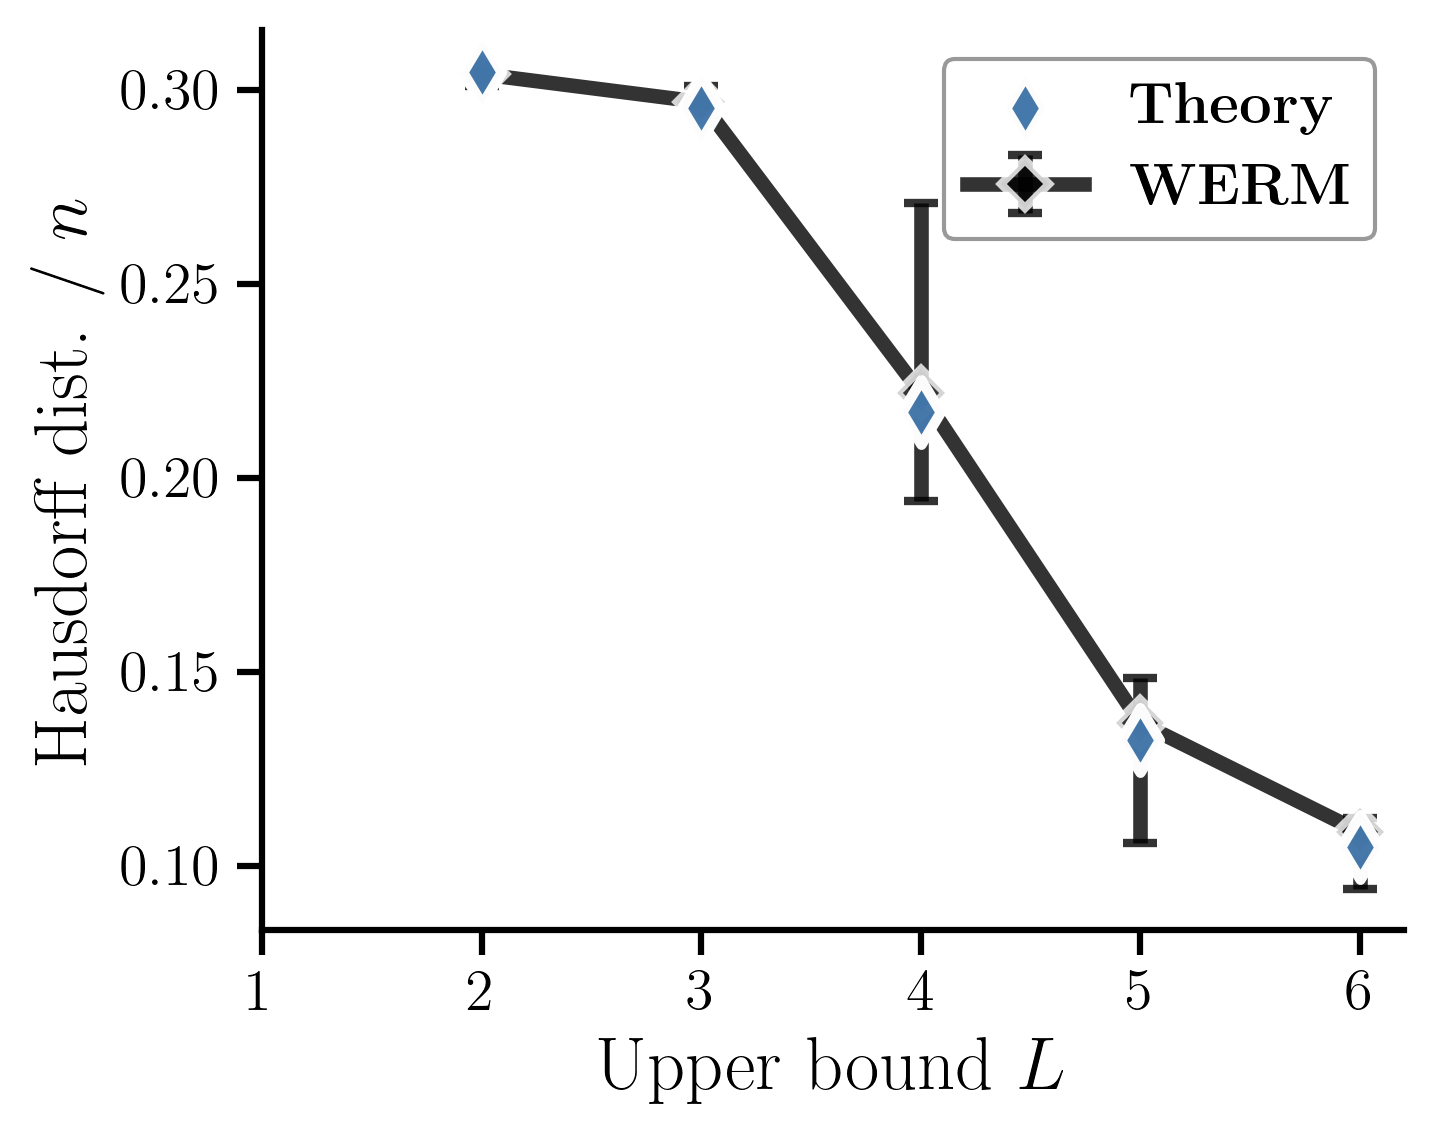

penalty_haus_box


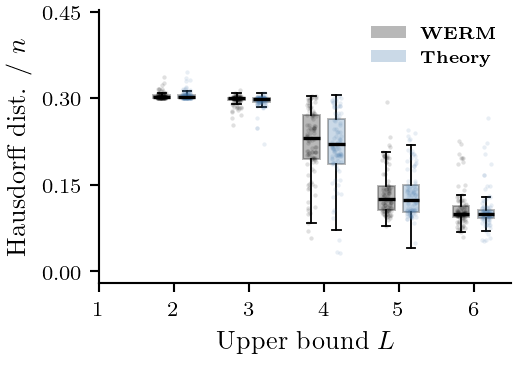

penalty_count_line


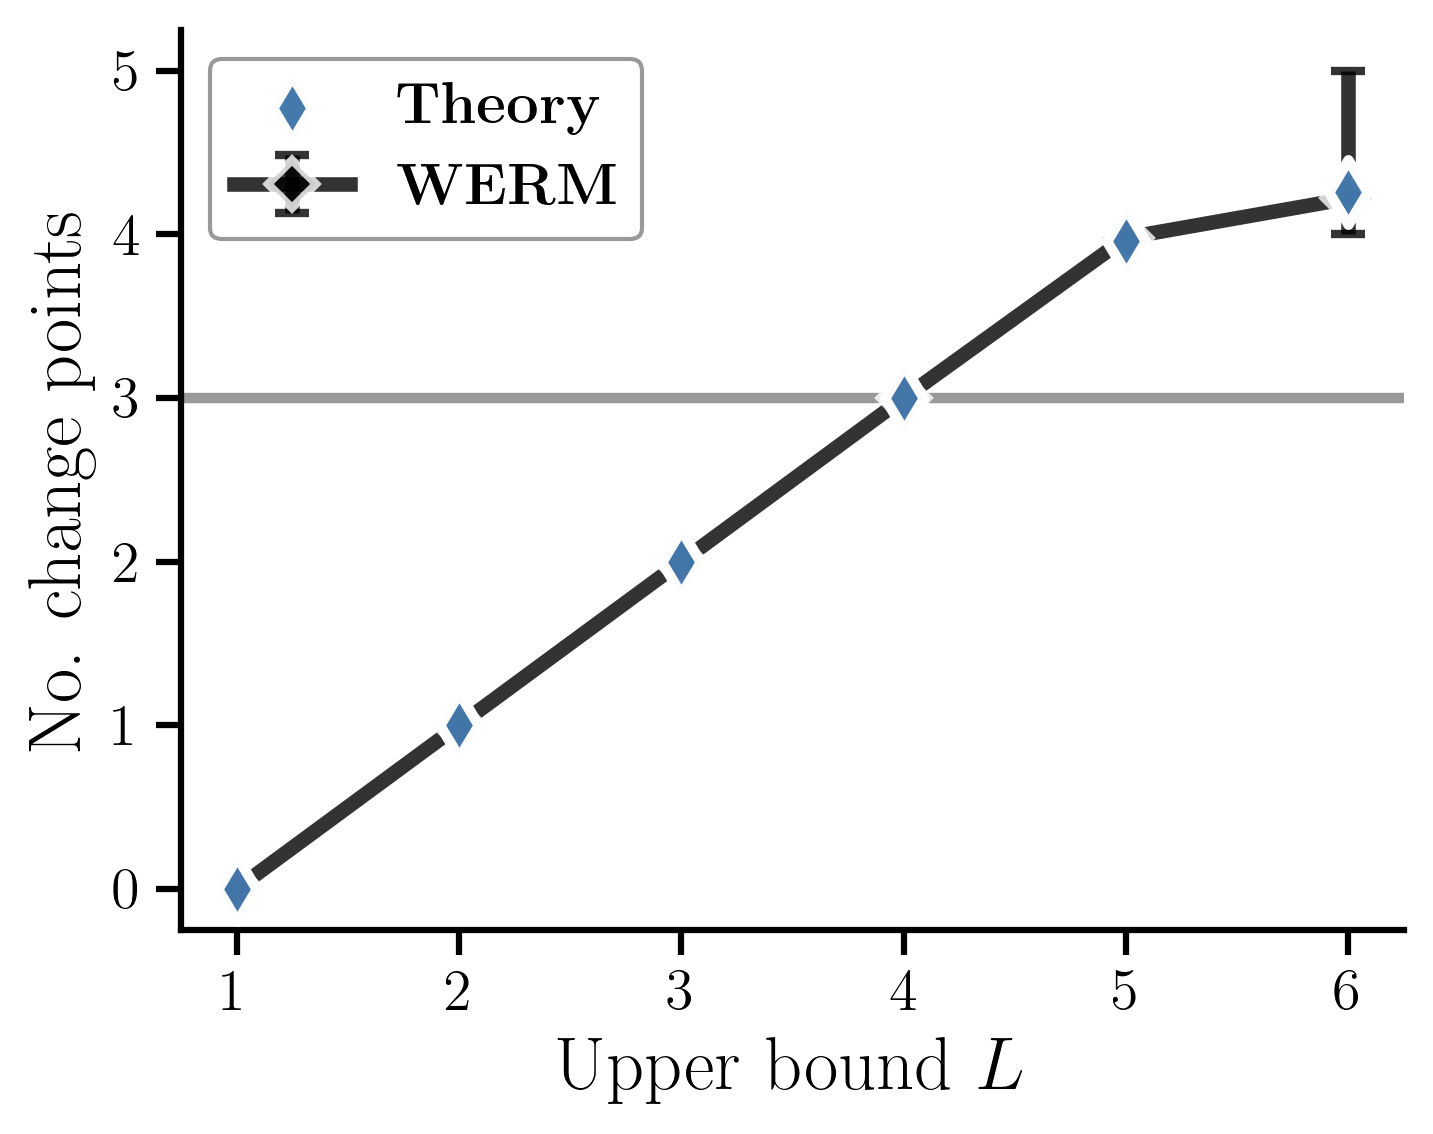

penalty_count_box


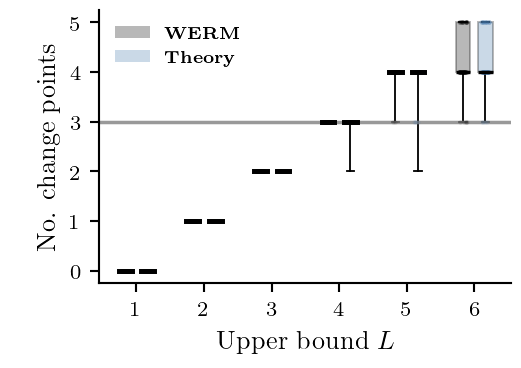

penalty_histograms: maximum density 125.00; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


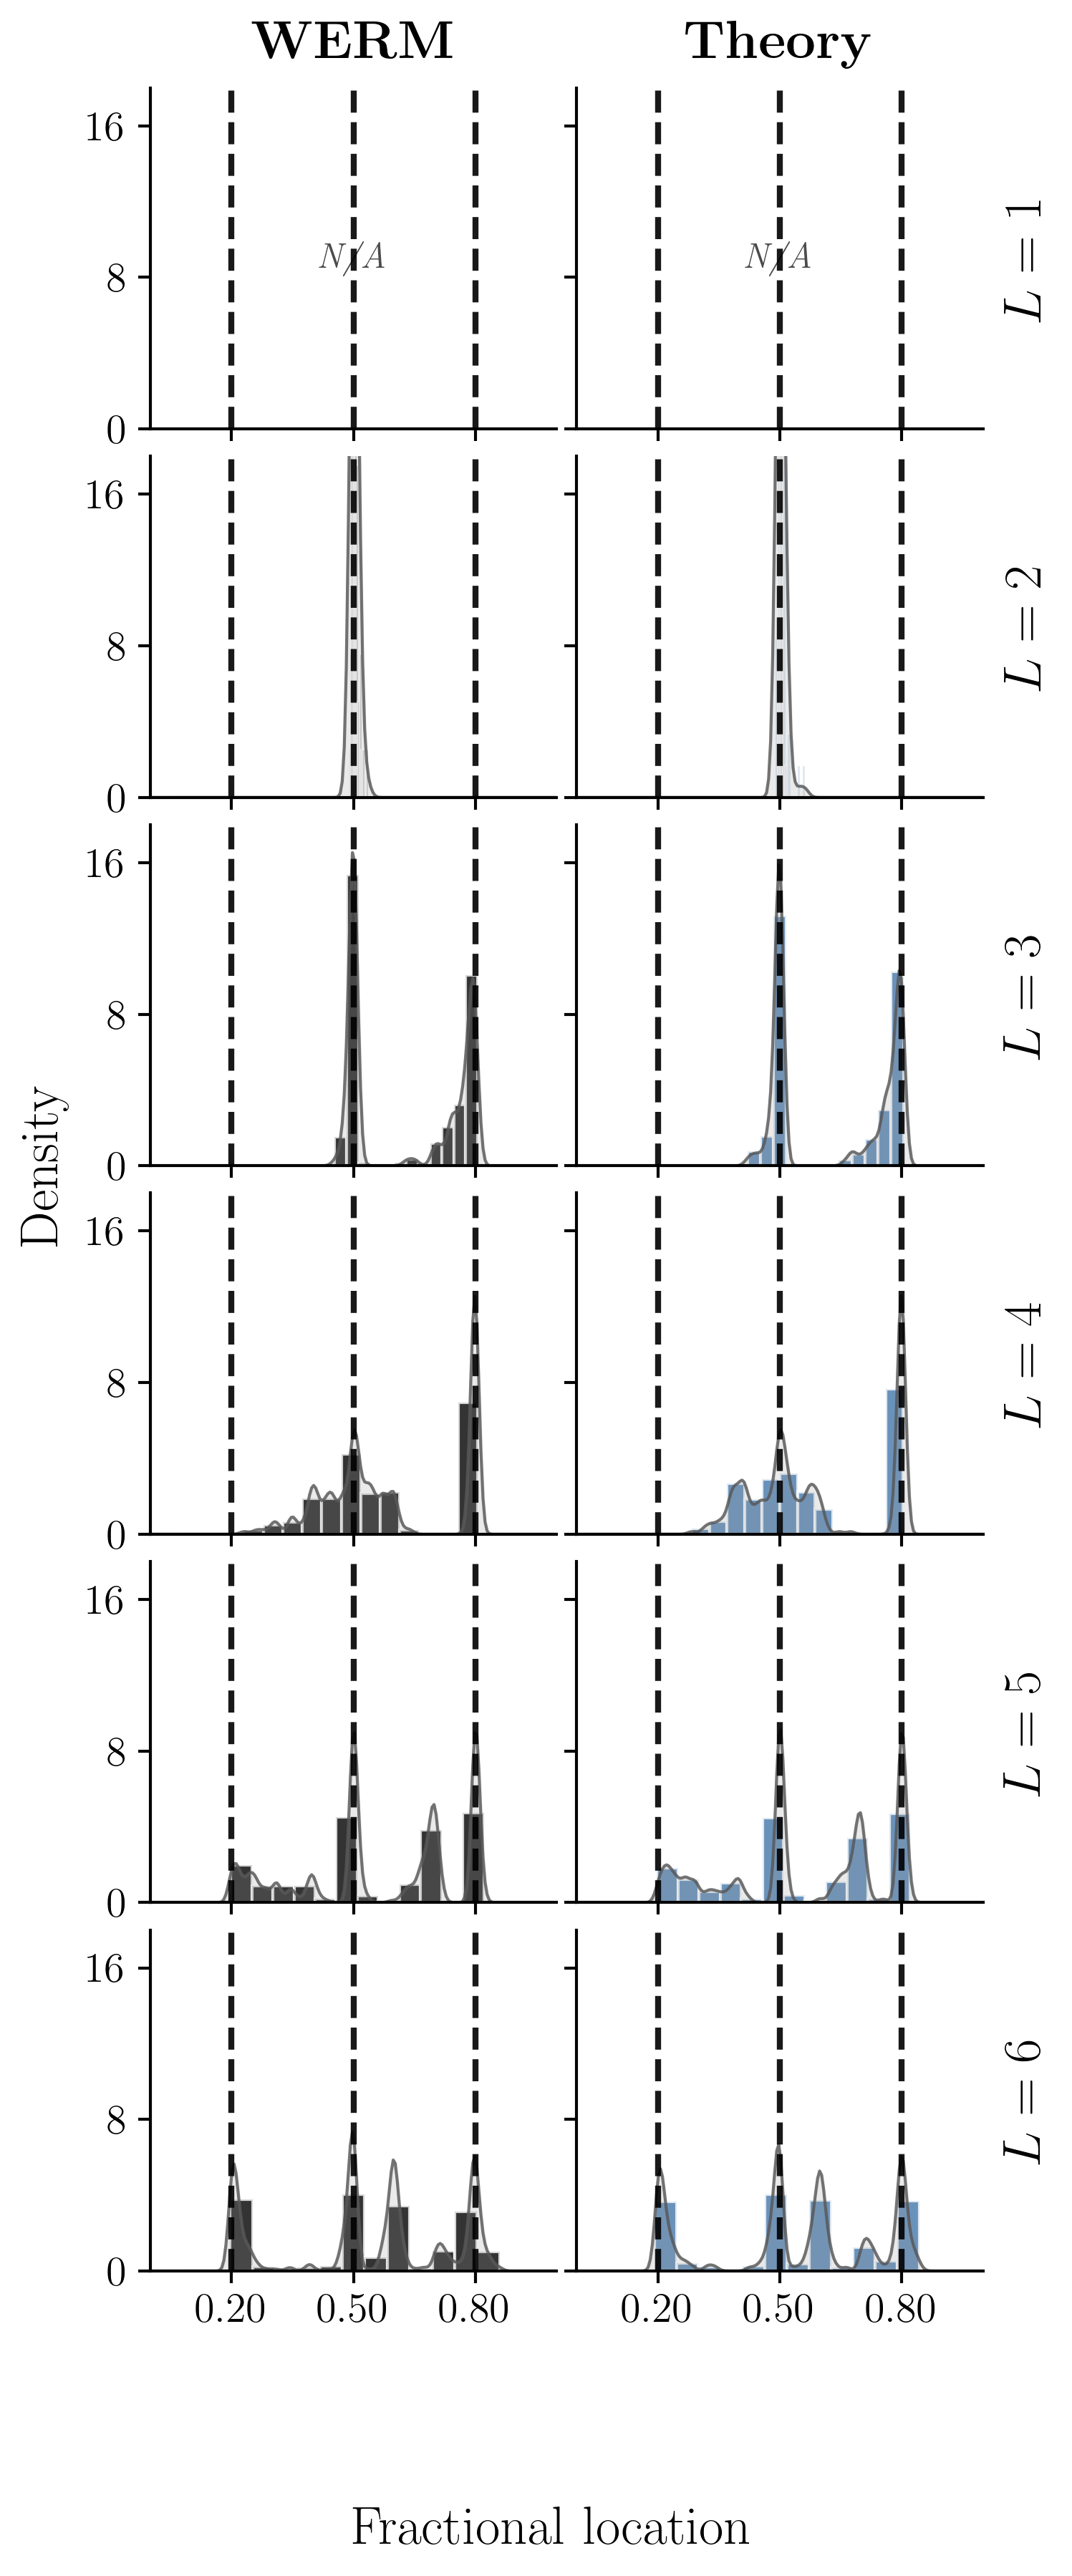

Exported 5 figures to results/E_L_SE_penalty_fixed/982fa979e869/figures; saved inputs unchanged.


In [2]:
import tools.consistent_plotting as se_style
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
se_style.OUTPUT_DIR=SE_ROOT/'figures'
se_style.SOURCE_HASHES.clear();se_style.FIGURE_AUDIT.clear()
SE_LABELS=(r'\textbf{WERM}',r'\textbf{Theory}')
SE_COLORS=('black','#4477AA')

def se_groups(payload,mode,source,metric):
    output=[]
    for count in MODES[mode]:
        settings=[r['fits'][mode,count] for r in payload['records']]
        fits=([s['empirical'] for s in settings] if source=='empirical'
              else [fit for s in settings for fit in s['theory']])
        output.append(np.array([f[metric] for f in fits]))
    return output

def plot_el_se(mode):
    saved=se_style.load_saved(SE_ROOT/'study.pkl')
    counts=np.array(MODES[mode]);x=counts if mode=='penalty' else counts-1
    xlabel=r'Upper bound $L$' if mode=='penalty' else 'Assumed number of change points'
    for metric,ylabel in [('haus',r'Hausdorff dist. / $n$'),('count','No. change points')]:
        for kind in ('line','box'):
            with plt.rc_context(se_style.CANONICAL_STYLE if kind=='line' else se_style.PAPER_STYLE):
                if kind=='line':
                    fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
                else:
                    fig,ax=se_style.paper_panel();rng=np.random.default_rng(42)
                for j,source in enumerate(('empirical','theory')):
                    groups=se_groups(saved,mode,source,metric)
                    if kind=='line':
                        if source=='theory':
                            means=np.array([np.mean(v[np.isfinite(v)])
                                if np.isfinite(v).any() else np.nan for v in groups])
                            ax.scatter(x,means,label=SE_LABELS[j],marker='d',
                                color=SE_COLORS[j],s=120,edgecolor='white',
                                linewidth=2.5,alpha=.99,zorder=5)
                        else:
                            se_style.error_series(ax,x,groups,SE_LABELS[j],SE_COLORS[j],
                                'D','-',scale=1)
                    else:
                        for i,values in enumerate(groups):
                            previous=len(ax.collections)
                            se_style.box_group(ax,values,3*i+j,SE_COLORS[j],rng)
                            # Box statistics retain all SE draws; show a comparable
                            # number of raw points for each method in the scatter.
                            if source=='theory':
                                for points in ax.collections[previous:]:
                                    offsets=points.get_offsets()
                                    if len(offsets)>100:
                                        points.set_offsets(offsets[np.linspace(0,len(offsets)-1,100,dtype=int)])
                if kind=='line':
                    ax.set_xticks(x)
                else:
                    ax.set_xticks(np.arange(len(x))*3+.5,[str(v) for v in x])
                ax.set(xlabel=xlabel,ylabel=ylabel)
                if metric=='count':
                    ax.axhline(3,color='gray',lw=2.5 if kind=='line' else 1.4,alpha=.8)
                    ax.set_yticks(range(6))
                if kind=='line':
                    ax.legend(loc='best',prop={'size':14},framealpha=.4)
                    fig.tight_layout()
                else:
                    ax.legend(handles=[Patch(facecolor=c,alpha=.28,label=l) for c,l in zip(SE_COLORS,SE_LABELS)],
                              loc='best',fontsize=7)
                se_style.export_plot(fig,f'{mode}_{metric}_{kind}')
    pools=[]
    for count in counts:
        settings=[r['fits'][mode,int(count)] for r in saved['records']]
        empirical=np.concatenate([s['empirical']['cp']/SE_SPEC['n'] for s in settings])
        theory=np.concatenate([s['theory'][0]['cp']/SE_SPEC['n'] for s in settings])
        pools.append([empirical,theory])
    row_labels=([rf'$L={c}$' for c in counts] if mode=='penalty'
                else [rf'$K-1={c-1}$' for c in counts])
    se_style.histogram_grid(pools,SE_LABELS,SE_COLORS,[.2,.5,.8],f'{mode}_histograms',
        row_labels=row_labels,density_label_x=.005)
    se_style.verify_sources()

plot_el_se('penalty')

## Fixed assumed count: under- and over-specification with SE

Keep $L^\star=4$ (three true changes) and the same 100 datasets, but now assume
**exactly 1, 2, 3, 4 or 5 change points**: fitted segment counts $K=2,\ldots,6$.
Each setting has its own fixed-count prior weights and coefficient fits. The search
is constrained to exactly $K$ segments, with **no search penalty and no CV**.
The SE calculation uses those same weights and applies that same exact-count search.

The x-axis is now the **assumed number of change points**; it is not an upper bound.
Hausdorff error and location distributions provide the nontrivial theory comparison.
The count plot is deterministic by construction and is included only as a protocol check.
All four true regimes are retained for the underspecified settings.

,mode,fitted_segments,x,source,draws,empty,mean_count,correct_count,mean_haus,median_haus
12,fixed,2,1,empirical,100,0,1.0,0.0,0.3033,0.3010
13,fixed,2,1,theory,2000,0,1.0,0.0,0.3031,0.3020
14,fixed,3,2,empirical,100,0,2.0,0.0,0.2119,0.2085
15,fixed,3,2,theory,2000,0,2.0,0.0,0.2139,0.2100
16,fixed,4,3,empirical,100,0,3.0,1.0,0.0050,0.0035
17,fixed,4,3,theory,2000,0,3.0,1.0,0.0046,0.0030
18,fixed,5,4,empirical,100,0,4.0,0.0,0.0802,0.0795
19,fixed,5,4,theory,2000,0,4.0,0.0,0.0826,0.0830
20,fixed,6,5,empirical,100,0,5.0,0.0,0.1311,0.1330
21,fixed,6,5,theory,2000,0,5.0,0.0,0.1299,0.1320


fixed_haus_line


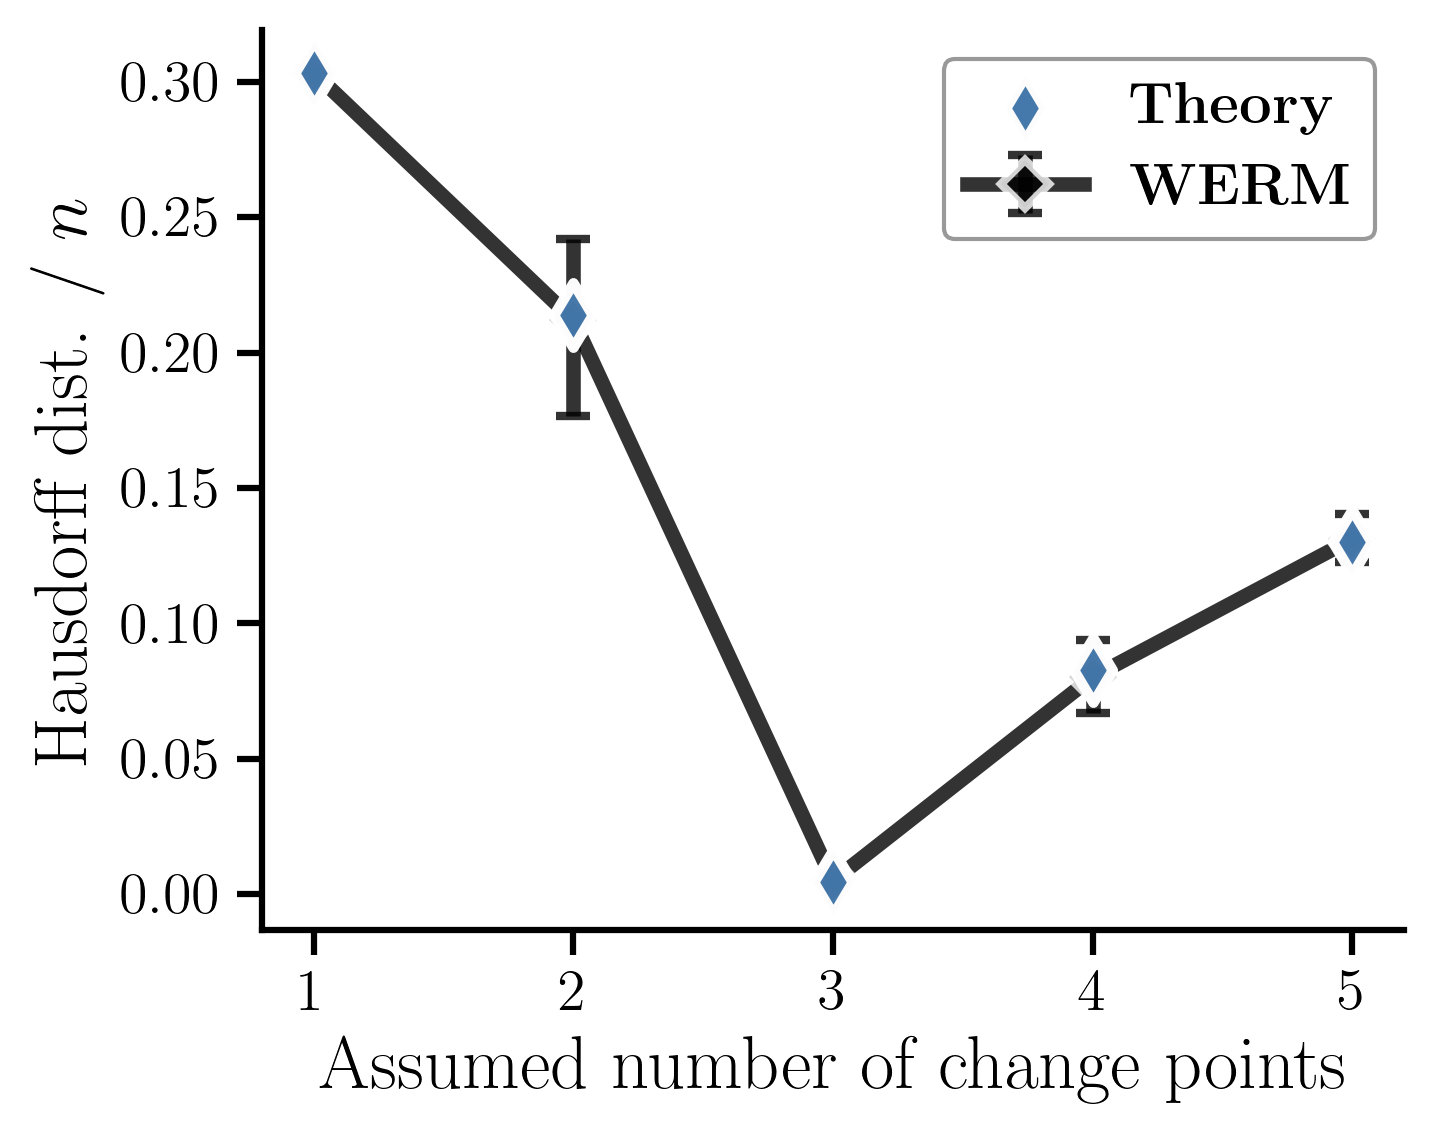

fixed_haus_box


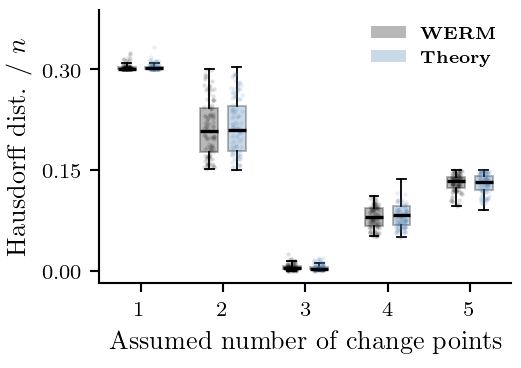

fixed_count_line


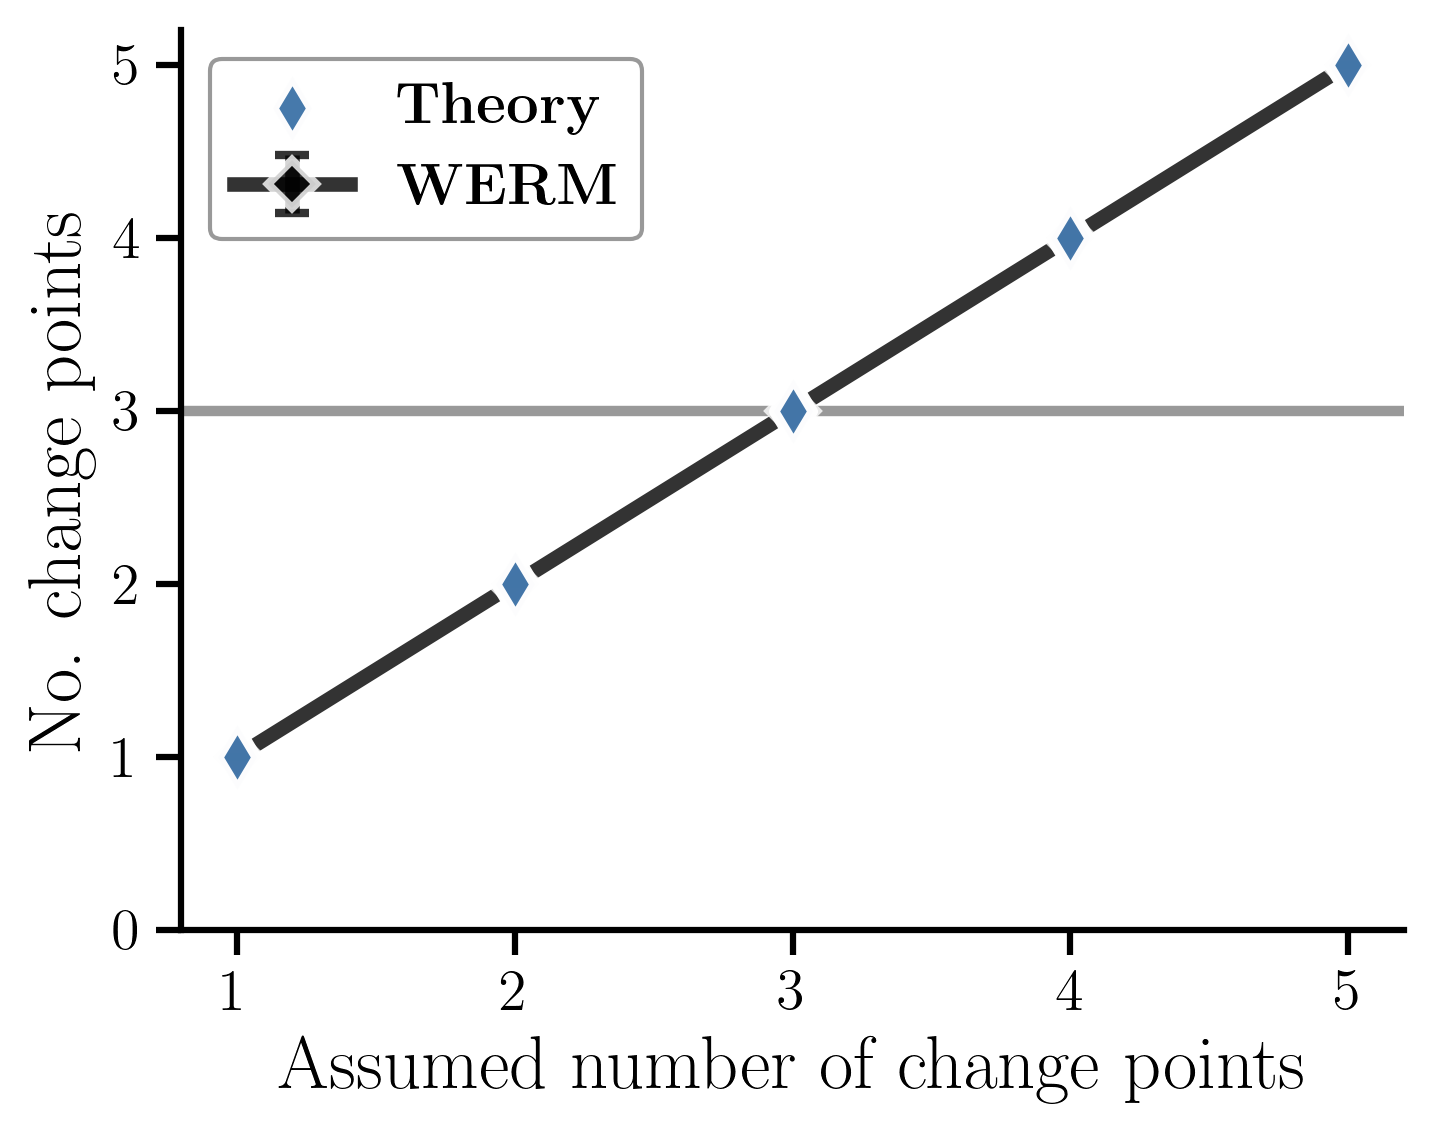

fixed_count_box


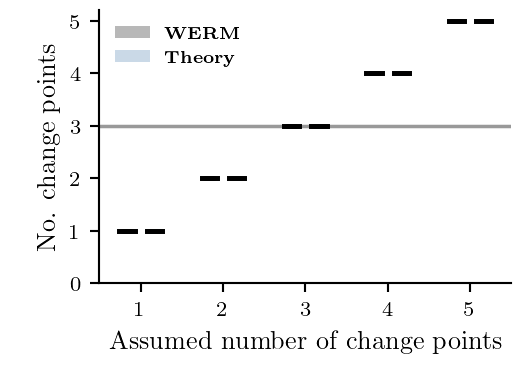

fixed_histograms: maximum density 135.32; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


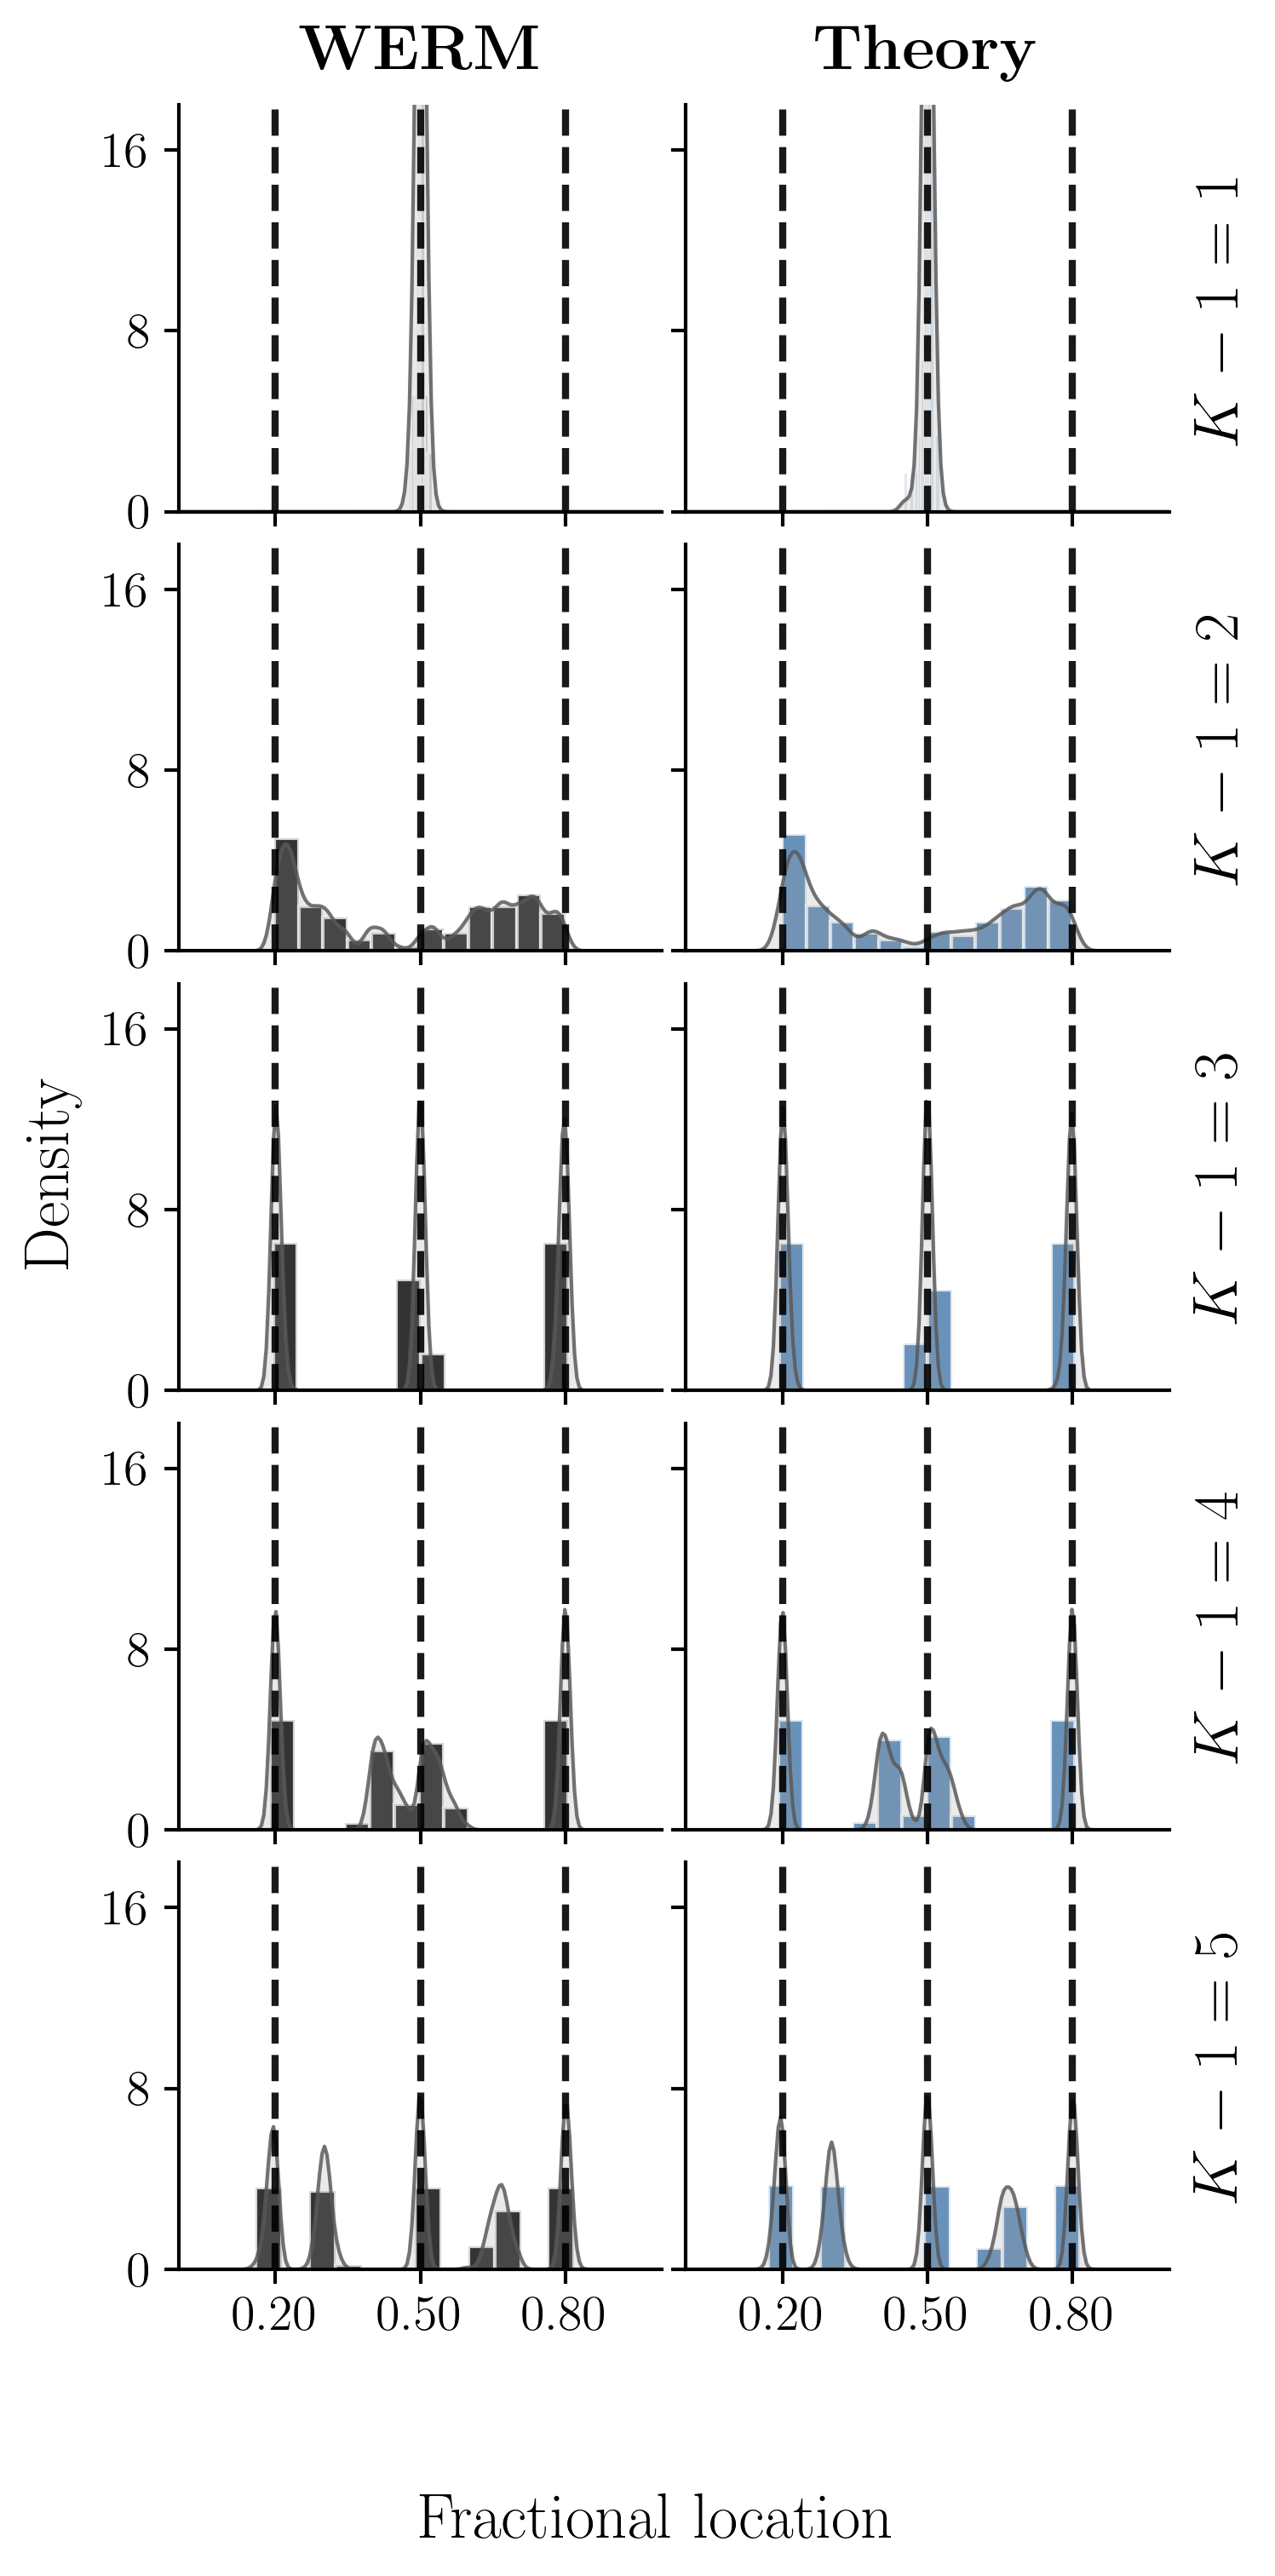

Exported 10 figures to results/E_L_SE_penalty_fixed/982fa979e869/figures; saved inputs unchanged.


In [3]:
display(SE_SUMMARY[SE_SUMMARY['mode']=='fixed'].round(4))
plot_el_se('fixed')

### Agreement and solver diagnostics

The table reports SE minus empirical differences in mean count and conditional
mean normalized Hausdorff error. Empty estimates are kept in count summaries and
omitted only from conditional localization and location densities. The two sets
of draws are independent conditional on each trial's true signal matrix; 2,000
SE realizations are not 2,000 independent draws of that matrix.

Residuals check the scalar curvature equations, Gaussian score orthogonality and
the full covariance fixed-point equation. Tests also independently evaluate the
general moment equations by Monte Carlo, verify classical homogeneous least
squares, and compare the search against the native exact DP.

In [4]:
agreement=[]
for mode,counts in MODES.items():
    for count in counts:
        frame=SE_SUMMARY[(SE_SUMMARY['mode']==mode)&(SE_SUMMARY.fitted_segments==count)].set_index('source')
        agreement.append(dict(mode=mode,x=count if mode=='penalty' else count-1,
            empirical_haus=frame.loc['empirical','mean_haus'],
            theory_haus=frame.loc['theory','mean_haus'],
            haus_difference=frame.loc['theory','mean_haus']-frame.loc['empirical','mean_haus'],
            empirical_count=frame.loc['empirical','mean_count'],
            theory_count=frame.loc['theory','mean_count'],
            count_difference=frame.loc['theory','mean_count']-frame.loc['empirical','mean_count']))
agreement=pd.DataFrame(agreement)
agreement.to_csv(SE_ROOT/'agreement.csv',index=False)
display(agreement.round(4))
from IPython.display import Markdown
penalty_rows=SE_SUMMARY[SE_SUMMARY['mode']=='penalty']
if np.allclose(penalty_rows['mean_count'],penalty_rows['fitted_segments']-1):
    display(Markdown(f"**Observed count-selection limitation:** at gamma={SE_SPEC['penalty_weight']:g}, "
        'every empirical and SE search selected the maximum allowed count. '
        'The count overlay is therefore exact but supplies only a limited count-selection check. '
        'Gamma was not retuned after seeing these results.'))
display(Markdown('Maximum absolute empirical–SE difference in mean normalized Hausdorff error: '
                 f"**{agreement.haus_difference.abs().max():.4f}**. These are finite-size Monte Carlo results."))
states=[fit['se'] for row in SE_STUDY['records'] for fit in row['fits'].values()]
diagnostics={key:max(s[key] for s in states)
             for key in ('b_residual','bias_residual','covariance_residual')}
diagnostics['minimum_covariance_eigenvalue']=min(s['min_eigenvalue'] for s in states)
display(pd.Series(diagnostics,name='SE diagnostics'))
assert len(SE_STUDY['records'])==100
assert all(len(f['theory'])==20 for r in SE_STUDY['records'] for f in r['fits'].values())
assert max(diagnostics[k] for k in ('b_residual','bias_residual','covariance_residual'))<1e-9
se_style.verify_sources()
print('Completed 100 empirical trials and 2,000 SE realizations at each setting.')

,mode,x,empirical_haus,theory_haus,haus_difference,empirical_count,theory_count,count_difference
0,penalty,1,NaN,NaN,NaN,0.00,0.000,0.000
1,penalty,2,0.3041,0.3046,0.0004,1.00,1.000,0.000
2,penalty,3,0.2970,0.2953,-0.0016,2.00,2.000,0.000
3,penalty,4,0.2219,0.2170,-0.0049,3.00,2.999,-0.001
4,penalty,5,0.1368,0.1324,-0.0044,3.98,3.962,-0.018
5,penalty,6,0.1086,0.1048,-0.0038,4.22,4.257,0.037
6,fixed,1,0.3033,0.3031,-0.0002,1.00,1.000,0.000
7,fixed,2,0.2119,0.2139,0.0020,2.00,2.000,0.000
8,fixed,3,0.0050,0.0046,-0.0004,3.00,3.000,0.000
9,fixed,4,0.0802,0.0826,0.0024,4.00,4.000,0.000


Maximum absolute empirical–SE difference in mean normalized Hausdorff error: **0.0049**. These are finite-size Monte Carlo results.

b_residual                       1.776357e-15
bias_residual                    2.516607e-14
covariance_residual              9.763949e-17
minimum_covariance_eigenvalue    1.154664e-02
Name: SE diagnostics, dtype: float64

Exported 10 figures to results/E_L_SE_penalty_fixed/982fa979e869/figures; saved inputs unchanged.
Completed 100 empirical trials and 2,000 SE realizations at each setting.


Implementation: `tools/el_state_evolution.py`; validation:
`tests/test_el_state_evolution.py`. Source hashes, frozen weights, data hashes,
per-trial SE matrices/residuals, empirical estimates, independent theoretical
estimates and all candidate penalized search scores are saved under the printed
result directory. Re-running these new sections reuses matching checkpoints.
Original CV cells and results are unchanged.

## Exploratory truth locations at frozen $\gamma=6$

The preceding studies remain unchanged. Here we ask whether changing the true
locations, or using two rather than three true changes, reduces over-selection
when the segment upper bound $L$ exceeds $L^\star$.

Keep $n=1000$, $p=100$, noise standard deviation 0.5, the same Gaussian random-walk
coefficient distribution, the same frozen upper-bound weights, and exactly
$P(K)=6\log\binom{n-1}{K-1}$. No coefficient tuning or CV is used.
For two changes, use the first three coefficient vectors of the same four-vector
draw; the unused fourth vector is still drawn so that covariates and noise remain
paired across all candidate layouts. SE retains the corresponding three or four
true regimes and runs its own penalized search.

**Pilot design:** all two- and three-location combinations of
$\{0.15,0.30,0.45,0.60,0.75,0.90\}$, plus $(0.20,0.50,0.80)$,
$(0.25,0.45,0.70)$ and $(0.30,0.55)$: 38 layouts, each with 20 paired trials.
Rank separately within each true count by empirical mean absolute count error
averaged over $L>L^\star$, then by higher exact-count frequency, then by lower
conditional Hausdorff error, then lexicographically. All pilot results are shown.

**Independent assessment:** freeze the best layout for each true count before
100 fresh paired trials, alongside the original three-change layout. Use 20
independent SE draws per signal matrix (2,000 per setting). Trial IDs 10000–10019
are for pilots; 20000–20099 are for assessment. Assessment outcomes and SE matches
never choose or retune locations. This is an exploratory, selected example of
layout sensitivity, not a general count-consistency claim.

In [1]:
# Self-contained: load completed artifacts, or compute missing trials.
from pathlib import Path
import json, pickle
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from tools import el_location_exploration as exploration
EXP_ROOT, EXP_SPEC, EXP_WEIGHTS = exploration.prepare()
EXP_FILE = EXP_ROOT/'assessment.pkl'
EXPLORATION = (pickle.loads(EXP_FILE.read_bytes()) if EXP_FILE.exists()
               else exploration.run(EXP_ROOT,EXP_SPEC,EXP_WEIGHTS))
EXP_SUMMARY = exploration.summarize(EXPLORATION['records'],theory=True)
print('Frozen gamma:',EXP_SPEC['gamma'])
print('Artifacts:',EXP_ROOT)
print('Pilot-selected layouts:',EXPLORATION['frozen']['choices'])
PILOT_RANKING = pd.read_csv(EXP_ROOT/'pilot_ranking.csv')
with pd.option_context('display.max_rows',None):
    display(PILOT_RANKING.round(4))

Frozen gamma: 6.0
Artifacts: results/E_L_location_exploration/80d0a6defd75
Pilot-selected layouts: {'2': (0.3, 0.45), '3': (0.15, 0.3, 0.6)}


,locations,true_changes,mean_absolute_count_error,correct_count,over_count,mean_haus
0,"(0.15, 0.3, 0.6)",3,0.0750,0.9250,0.0750,0.1409
1,"(0.3, 0.45, 0.6)",3,0.1000,0.9000,0.1000,0.0385
2,"(0.15, 0.45, 0.6)",3,0.1000,0.9000,0.1000,0.1985
3,"(0.3, 0.45)",2,0.2833,0.7167,0.2833,0.0449
4,"(0.15, 0.45)",2,0.2833,0.7167,0.2833,0.1716
5,"(0.15, 0.3)",2,0.3667,0.6333,0.0000,0.1331
6,"(0.3, 0.45, 0.9)",3,0.4000,0.6000,0.0750,0.3631
7,"(0.15, 0.45, 0.9)",3,0.4250,0.5750,0.0500,0.3718
8,"(0.3, 0.9)",2,0.4667,0.6000,0.2000,0.4491
9,"(0.25, 0.45, 0.7)",3,0.5250,0.4750,0.5250,0.0839


### Fresh assessment: count stability and localization

The table below includes all upper bounds at or above the true segment count.
`correct_count` is the fraction selecting the true number of changes; `over_count`
and `under_count` report over- and under-selection. `max_count` is the fraction
selecting the allowed maximum $L-1$. Hausdorff error is divided by $n$ and excludes
empty estimates, which are reported separately.

Mean panels retain the empirical curve and quartile bars. SE means are standalone
blue diamonds with white edges and no error bars or connecting lines, as in
the SE estimation plotting notebook. All 2,000 SE draws enter these means.
Histograms for the selected layouts use upper bounds 4, 5 and 6, with the first
SE draw per signal matrix to match the 100 empirical realizations.

In [2]:
display(EXP_SUMMARY[EXP_SUMMARY.L>=EXP_SUMMARY.true_changes+1].round(4))
pilot_ids=set(EXP_SPEC['pilot_trials']); assessment_ids=set(EXP_SPEC['assessment_trials'])
assert not pilot_ids & assessment_ids
assert EXP_SPEC['gamma']==6.
assert len(EXPLORATION['records'])==300
assert all(len(f['theory'])==20 for r in EXPLORATION['records'] for f in r['fits'].values())
states=[f['se'] for r in EXPLORATION['records'] for f in r['fits'].values()]
residuals={key:max(s[key] for s in states)
           for key in ('b_residual','bias_residual','covariance_residual')}
assert max(residuals.values())<1e-9
print('Maximum SE residuals:',residuals)
print('Full pilot results by L:',EXP_ROOT/'pilot_by_upper_bound.csv')

,locations,true_changes,L,source,draws,mean_count,correct_count,over_count,under_count,mean_absolute_count_error,max_count,empty,mean_haus
6,"(0.15, 0.3, 0.6)",3,4,empirical,100,2.1000,0.1000,0.0000,0.9000,0.9000,0.1000,0,0.1530
7,"(0.15, 0.3, 0.6)",3,4,theory,2000,2.1175,0.1175,0.0000,0.8825,0.8825,0.1175,0,0.1533
8,"(0.15, 0.3, 0.6)",3,5,empirical,100,3.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0,0.1484
9,"(0.15, 0.3, 0.6)",3,5,theory,2000,3.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0,0.1479
10,"(0.15, 0.3, 0.6)",3,6,empirical,100,3.1100,0.8900,0.1100,0.0000,0.1100,0.0000,0,0.1428
11,"(0.15, 0.3, 0.6)",3,6,theory,2000,3.1365,0.8635,0.1365,0.0000,0.1365,0.0000,0,0.1397
18,"(0.2, 0.5, 0.8)",3,4,empirical,100,3.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0,0.2276
19,"(0.2, 0.5, 0.8)",3,4,theory,2000,3.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0,0.2171
20,"(0.2, 0.5, 0.8)",3,5,empirical,100,3.9700,0.0300,0.9700,0.0000,0.9700,0.9700,0,0.1289
21,"(0.2, 0.5, 0.8)",3,5,theory,2000,3.9720,0.0250,0.9735,0.0015,0.9750,0.9735,0,0.1301


Maximum SE residuals: {'b_residual': 2.220446049250313e-16, 'bias_residual': 3.701604143632045e-15, 'covariance_residual': 1.0055412576335686e-16}
Full pilot results by L: results/E_L_location_exploration/80d0a6defd75/pilot_by_upper_bound.csv


truth_020_050_080_count


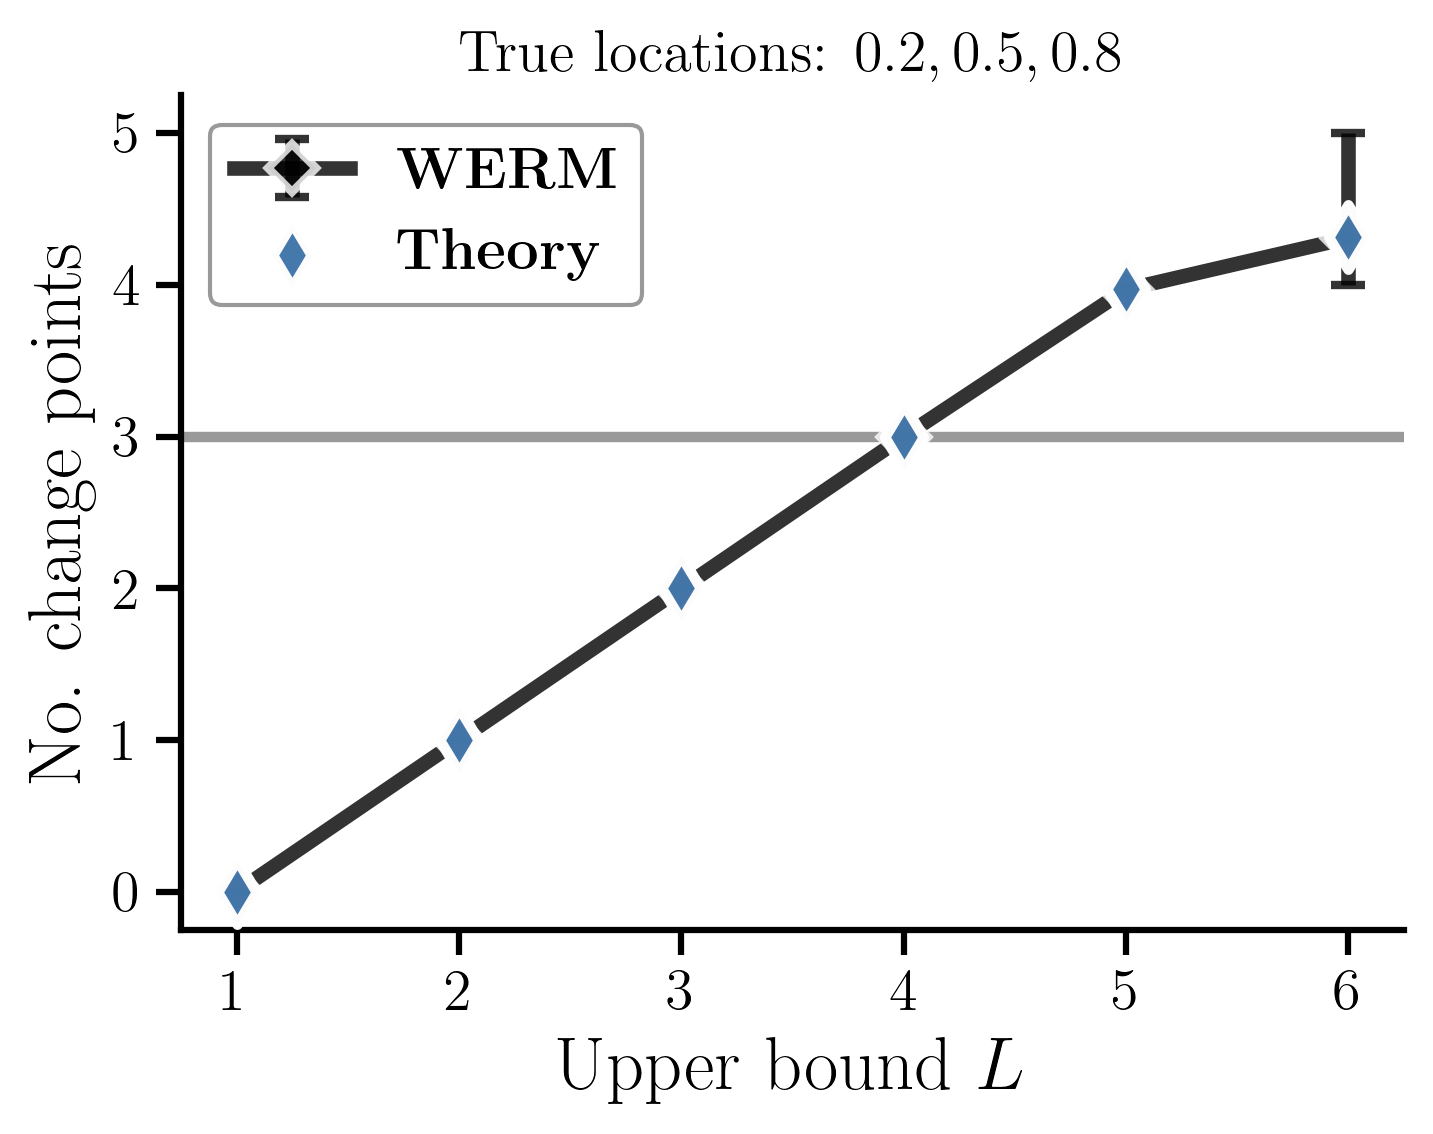

truth_020_050_080_haus


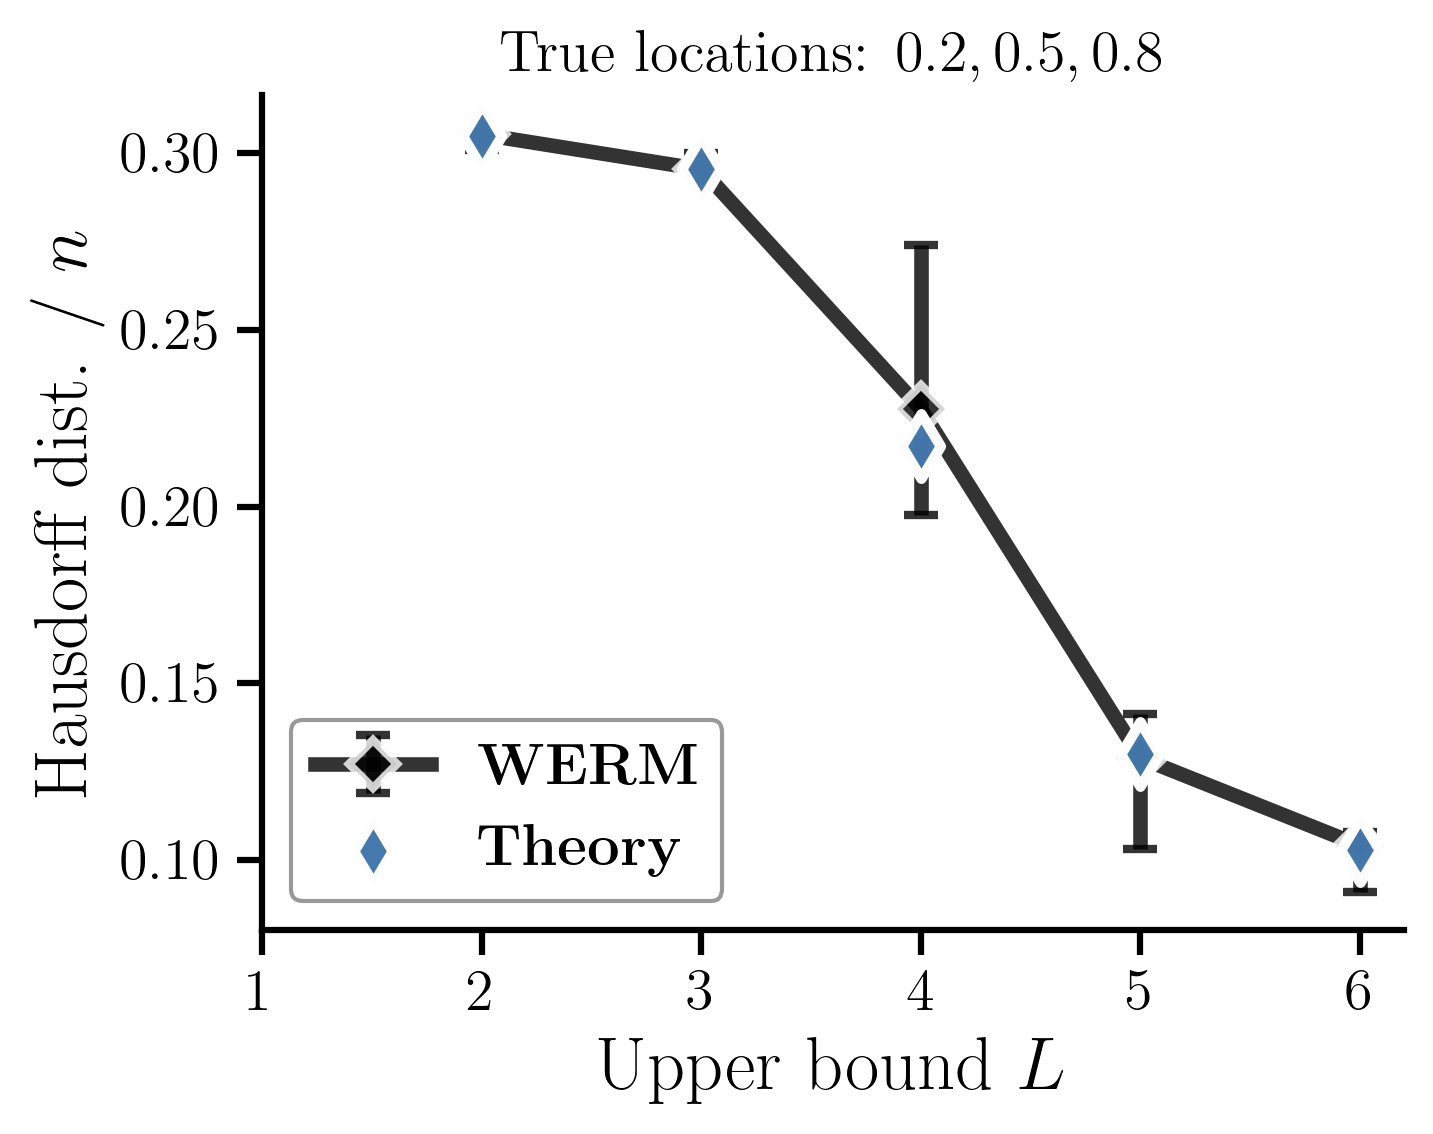

truth_015_030_060_count


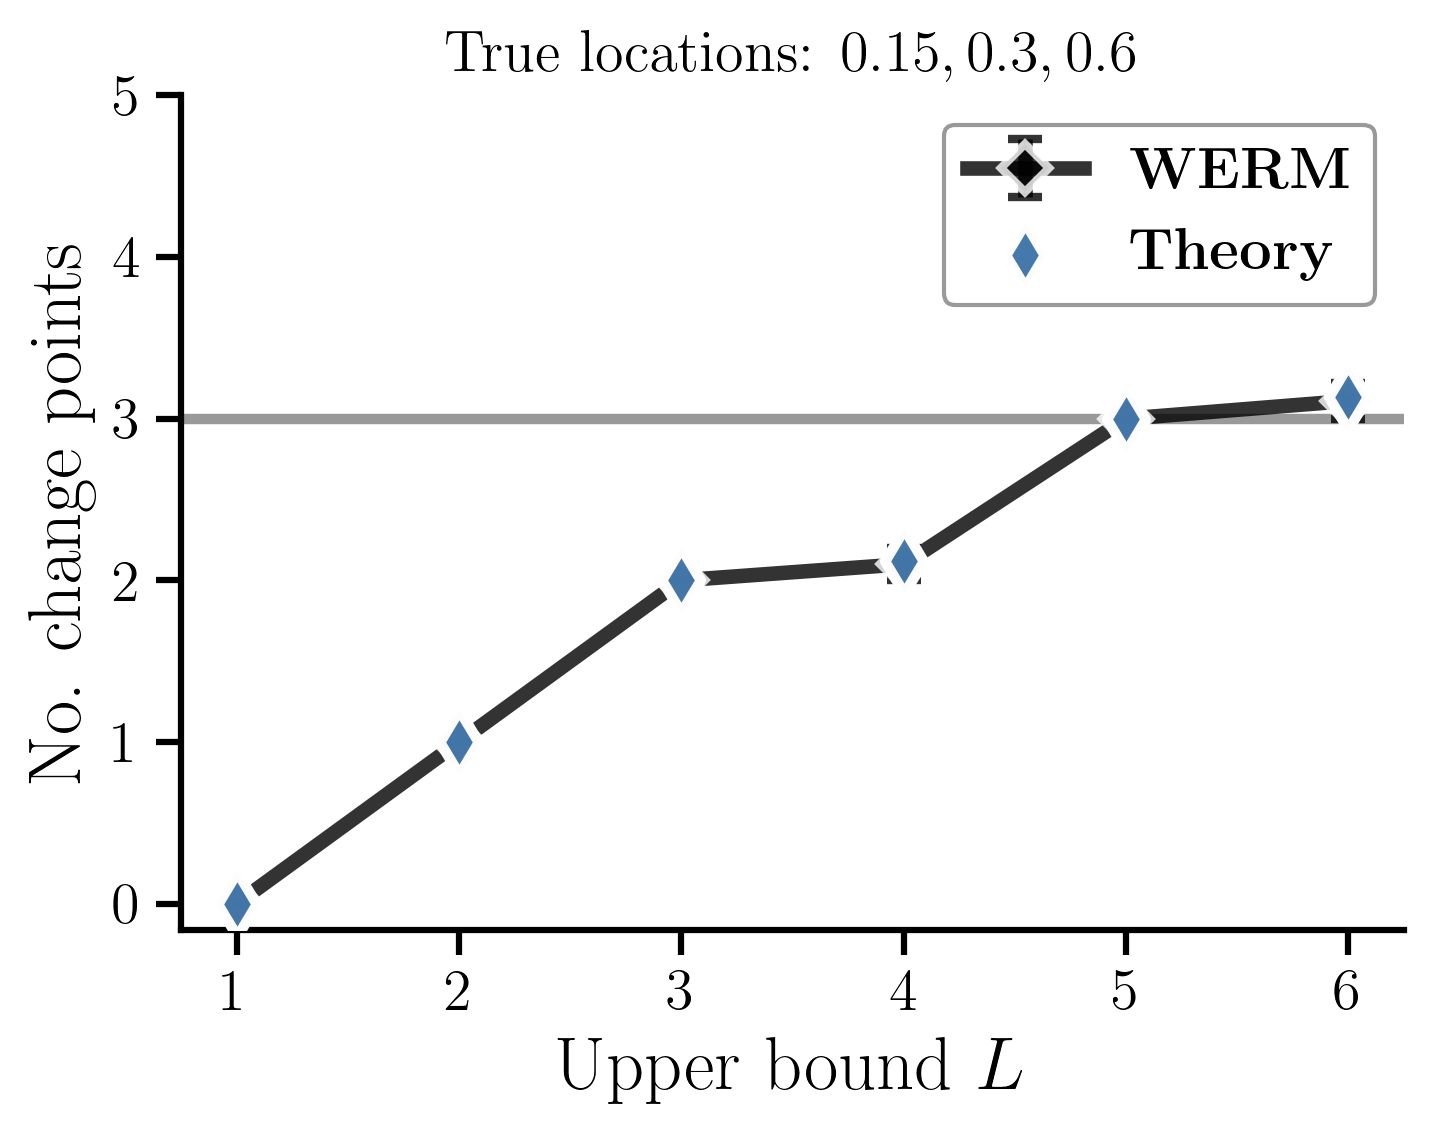

truth_015_030_060_haus


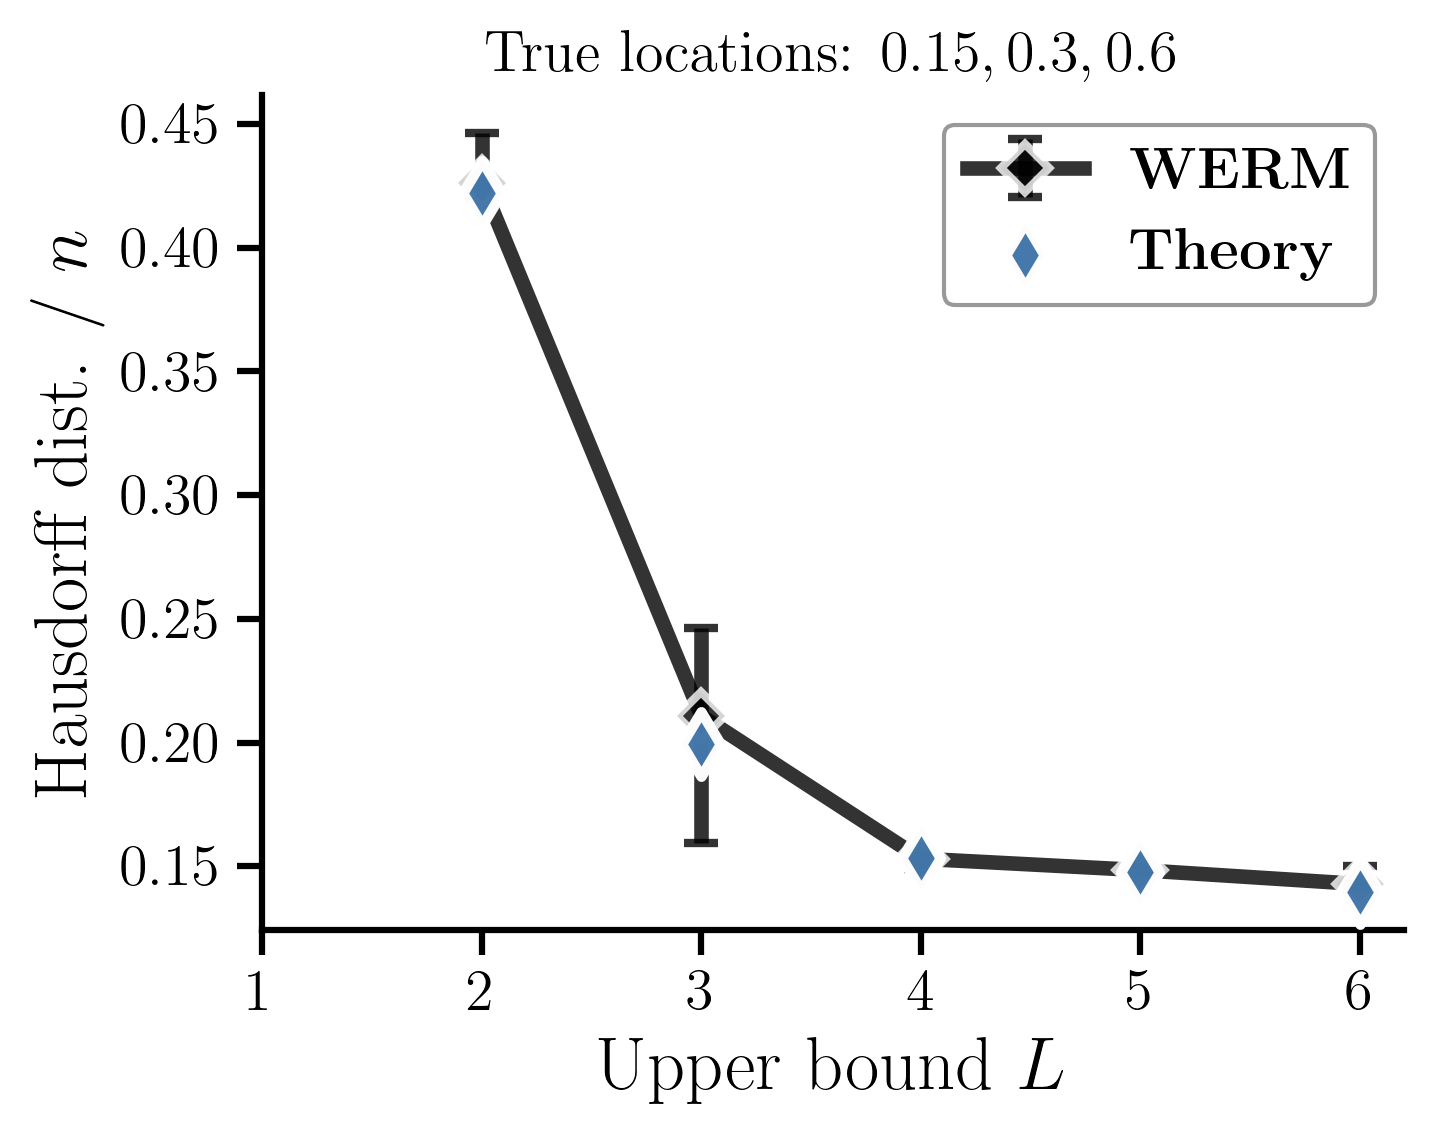

Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


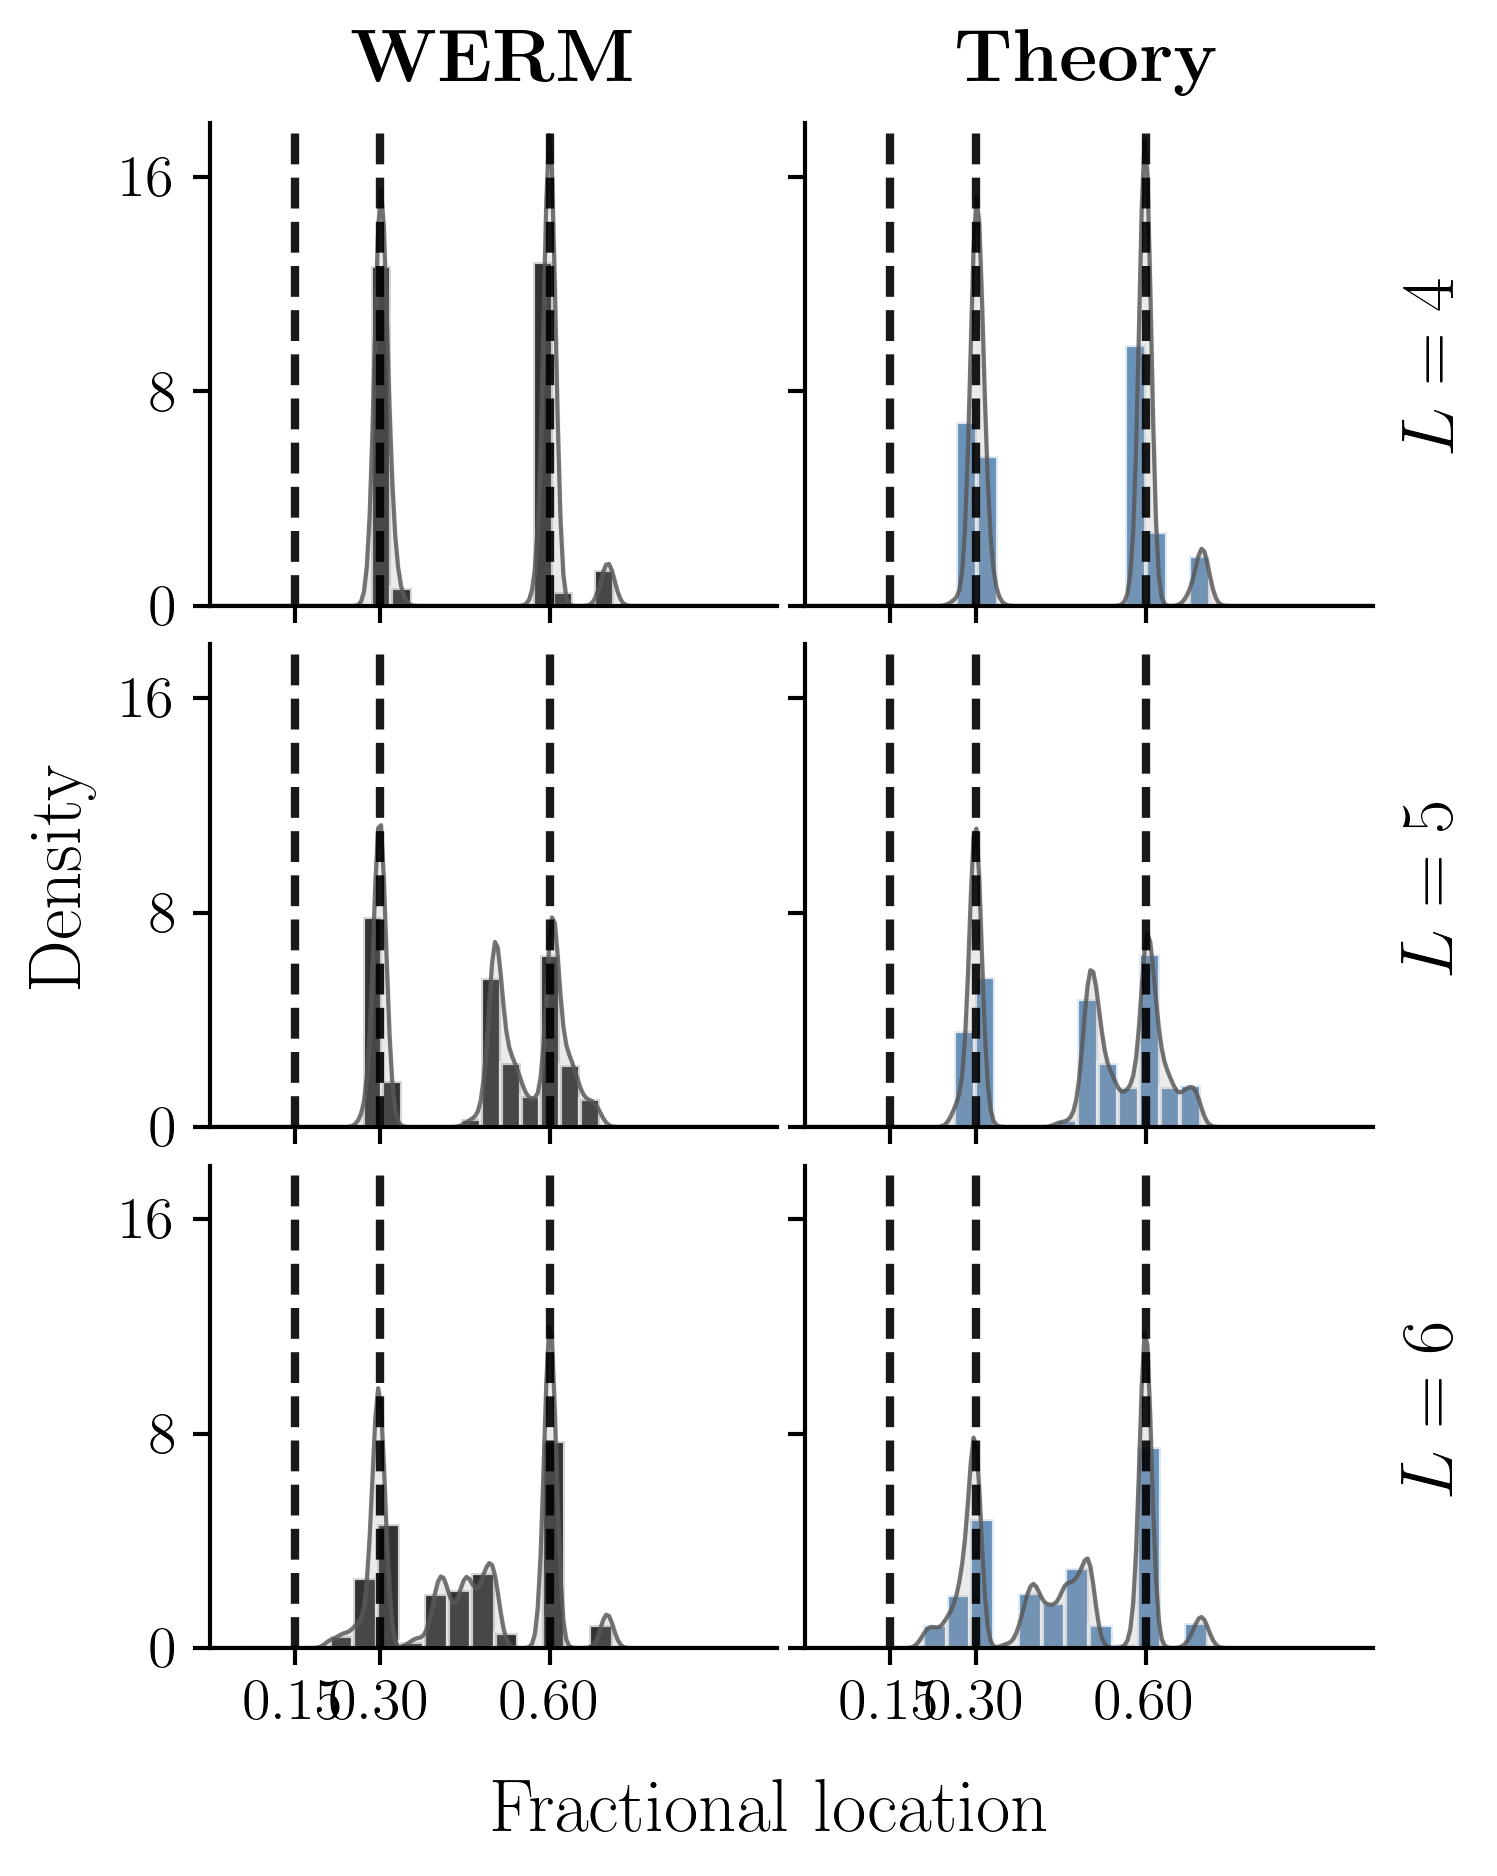

truth_030_045_count


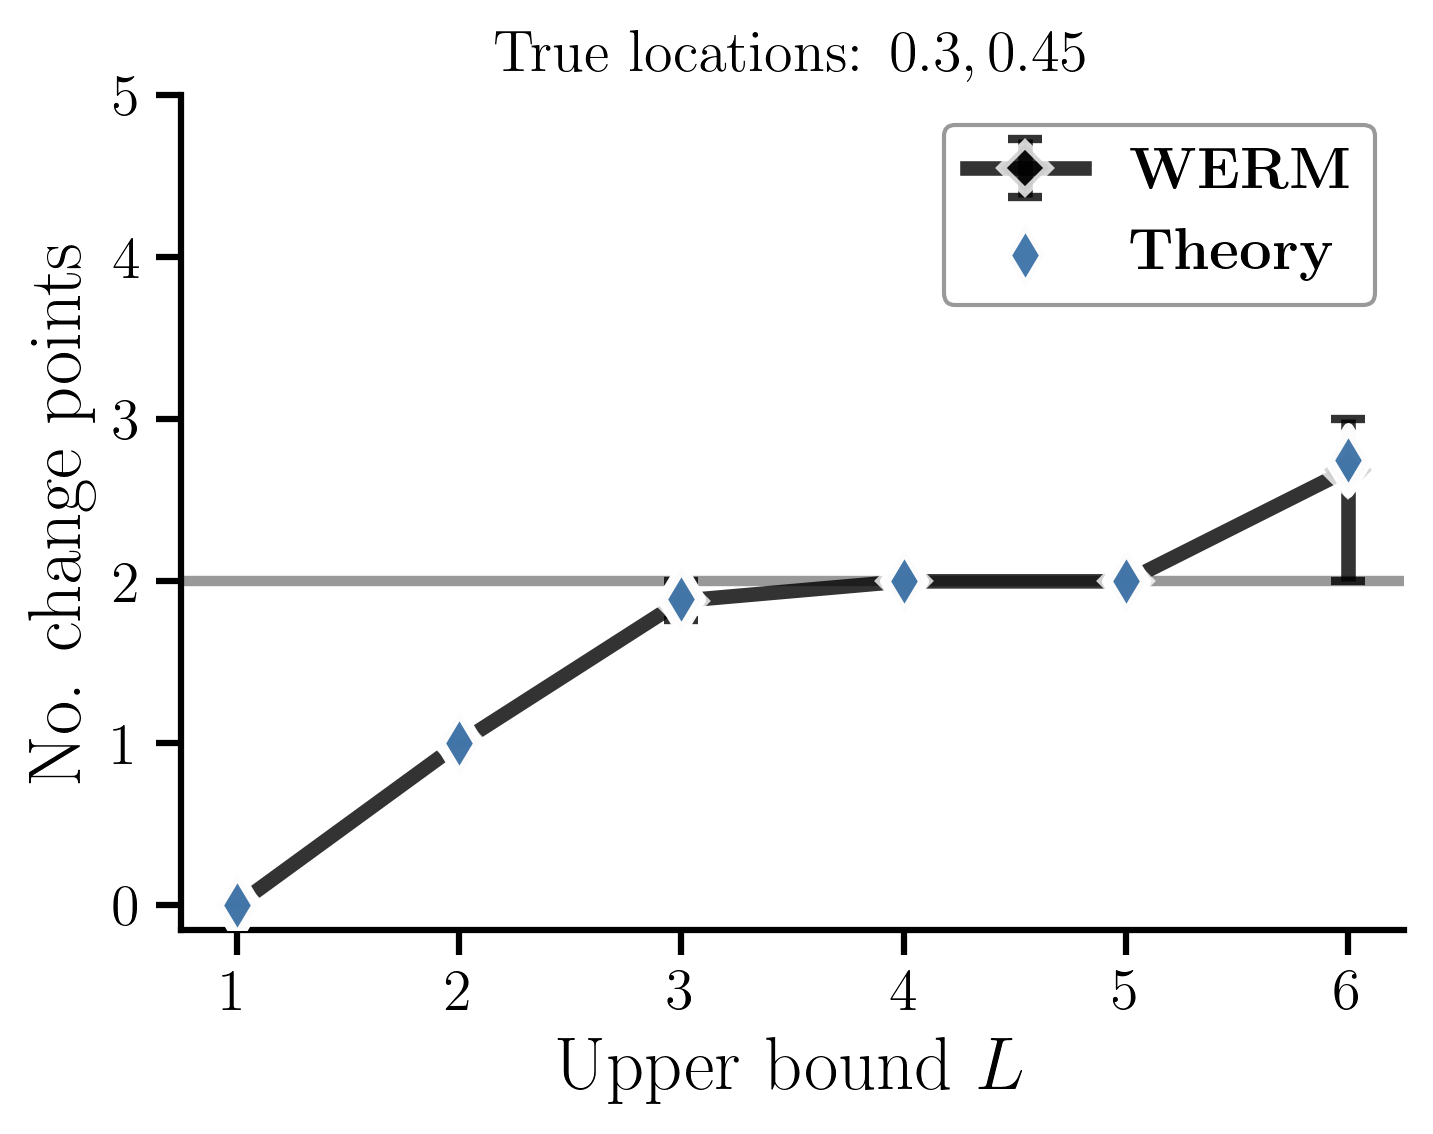

truth_030_045_haus


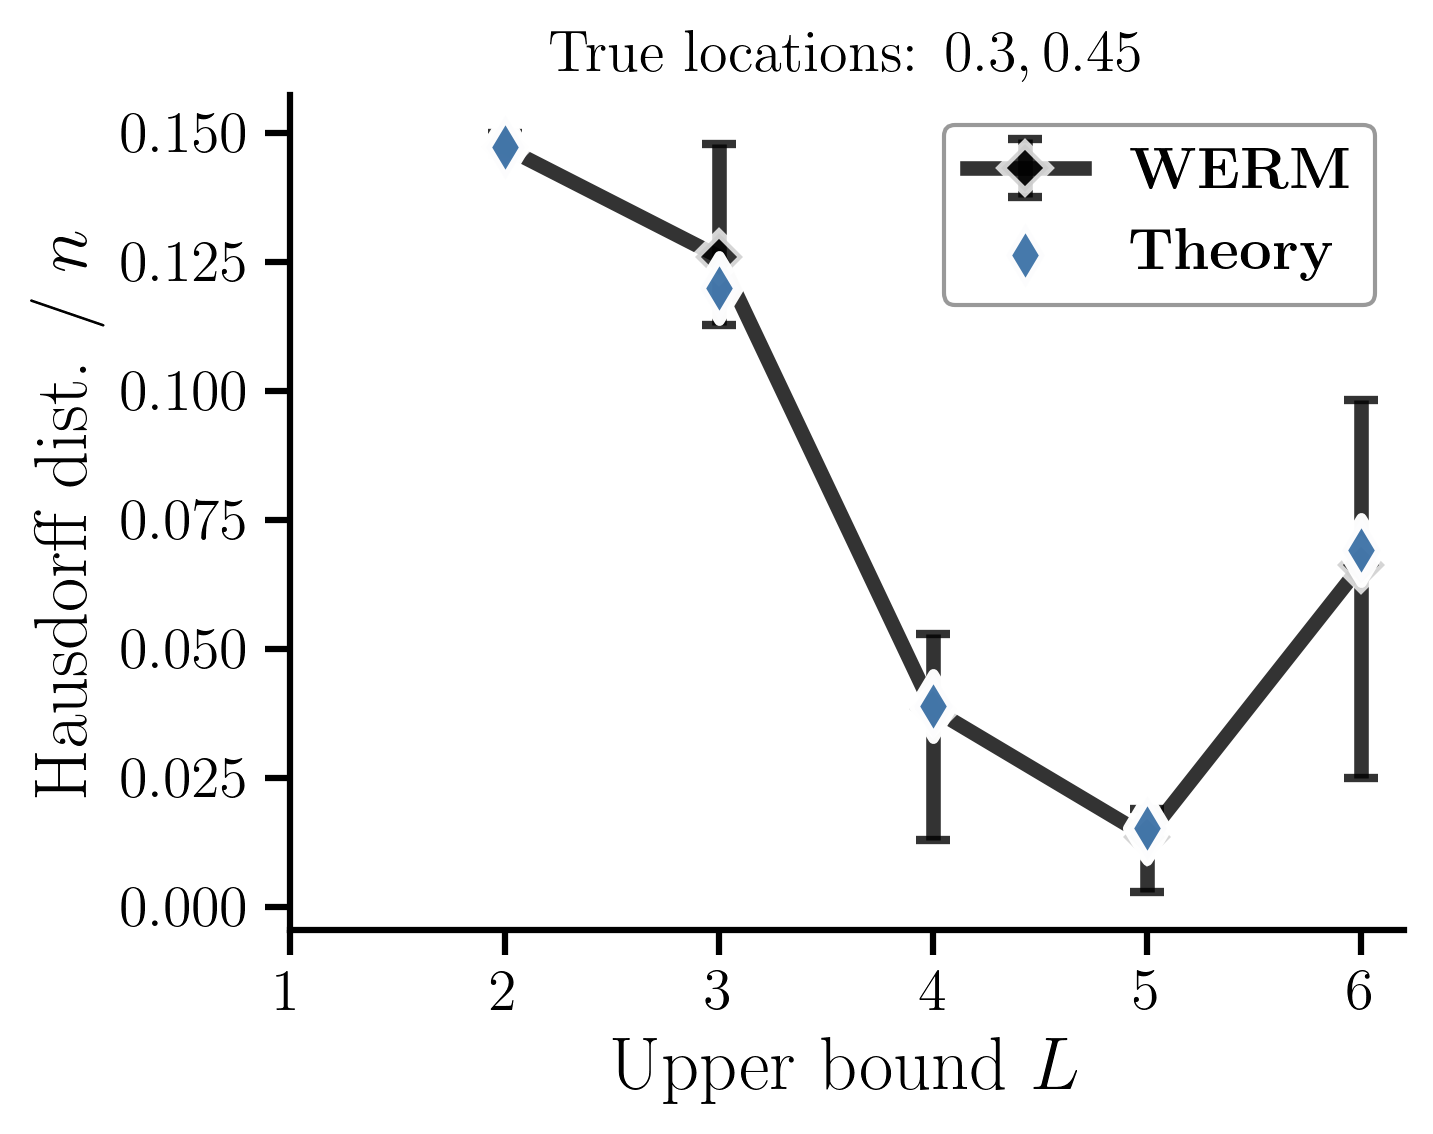

truth_030_045_histograms: maximum density 31.05; canonical display limit 18 (peaks above this are clipped).


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


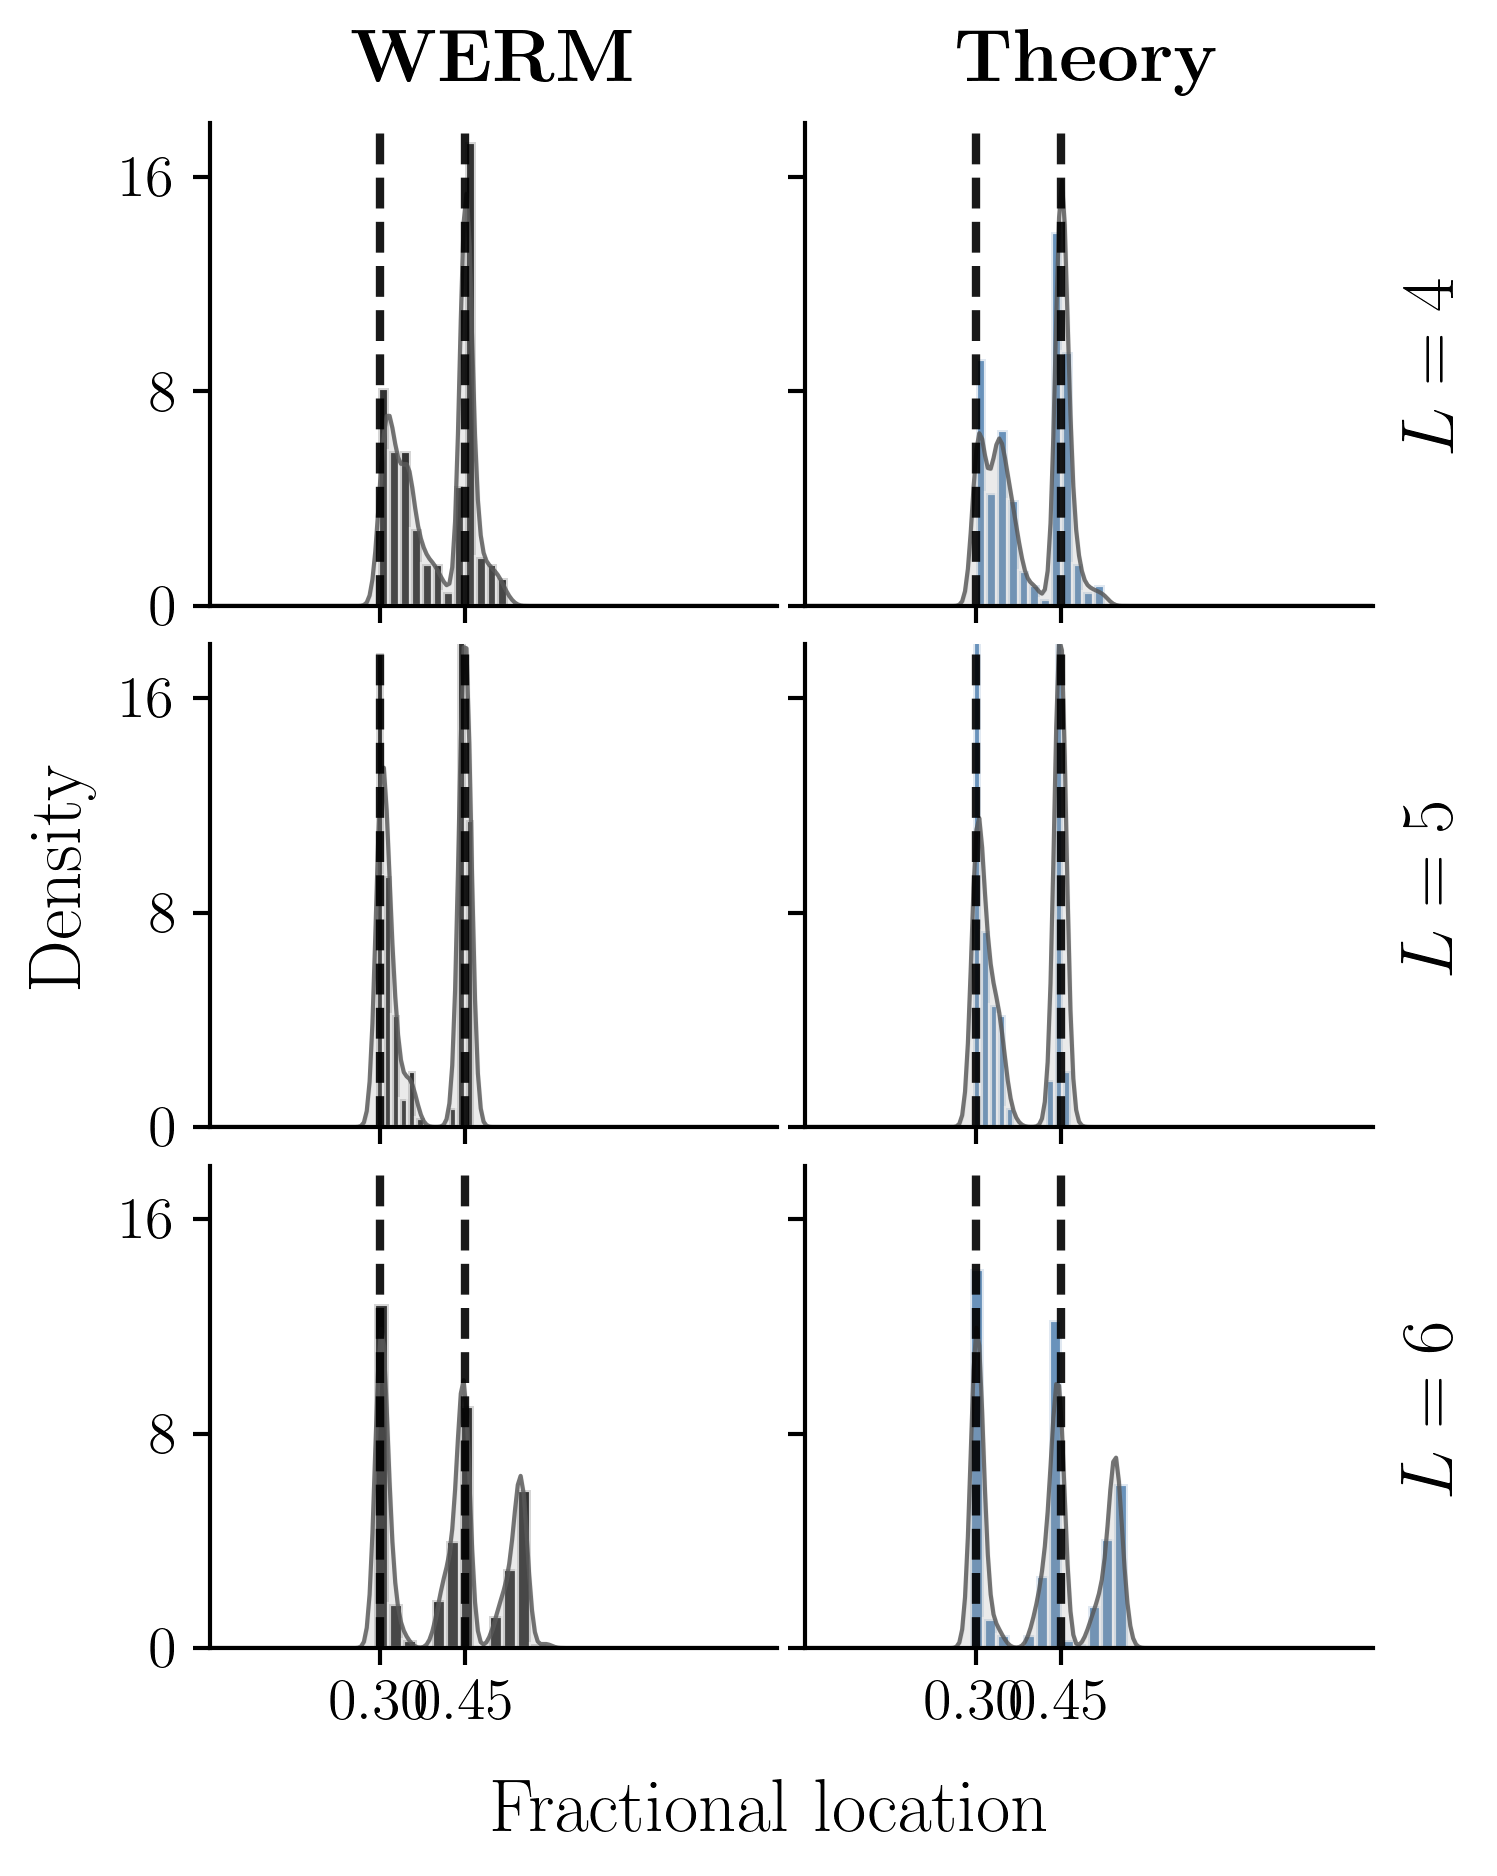

Exported 8 figures to results/E_L_location_exploration/80d0a6defd75/figures; saved inputs unchanged.


In [4]:
import matplotlib.pyplot as plt
import tools.consistent_plotting as exp_style
exp_style.OUTPUT_DIR=EXP_ROOT/'figures'
exp_style.SOURCE_HASHES.clear();exp_style.FIGURE_AUDIT.clear()
saved=exp_style.load_saved(EXP_FILE)
EXP_LABELS=(r'\textbf{WERM}',r'\textbf{Theory}')
EXP_COLORS=('black','#4477AA')
layouts=[exploration.BASELINE]+[tuple(saved['frozen']['choices'][str(k)]) for k in (3,2)]

def exploration_groups(records,source,metric):
    return [np.array([f[metric] for r in records for f in
        ([r['fits'][L]['empirical']] if source=='empirical' else r['fits'][L]['theory'])])
        for L in exploration.COUNTS]

for locations in layouts:
    records=[r for r in saved['records'] if r['locations']==locations]
    prefix='truth_'+exploration.layout_name(locations)
    truth_label=', '.join(f'{v:g}' for v in locations)
    for metric,ylabel in [('count','No. change points'),('haus',r'Hausdorff dist. / $n$')]:
        with plt.rc_context(exp_style.CANONICAL_STYLE):
            fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            groups=exploration_groups(records,'empirical',metric)
            exp_style.error_series(ax,exploration.COUNTS,groups,EXP_LABELS[0],
                                   EXP_COLORS[0],'D','-',scale=1)
            groups=exploration_groups(records,'theory',metric)
            means=[np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in groups]
            ax.scatter(exploration.COUNTS,means,label=EXP_LABELS[1],marker='d',
                color=EXP_COLORS[1],s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
            ax.set(xlabel=r'Upper bound $L$',ylabel=ylabel,xticks=exploration.COUNTS)
            ax.set_title(r'True locations: $'+truth_label+'$',fontsize=14)
            if metric=='count':
                ax.axhline(len(locations),color='gray',lw=2.5,alpha=.8,zorder=0)
                ax.set_yticks(range(6))
            handles,labels=ax.get_legend_handles_labels()
            order=[labels.index(label) for label in EXP_LABELS]
            ax.legend([handles[i] for i in order],EXP_LABELS,loc='best',prop={'size':14},framealpha=.4)
            fig.tight_layout();exp_style.export_plot(fig,prefix+'_'+metric)
    if locations!=exploration.BASELINE:
        pools=[]
        for L in (4,5,6):
            pools.append([np.concatenate([r['fits'][L]['empirical']['cp']/EXP_SPEC['n'] for r in records]),
                          np.concatenate([r['fits'][L]['theory'][0]['cp']/EXP_SPEC['n'] for r in records])])
        exp_style.histogram_grid(pools,EXP_LABELS,EXP_COLORS,locations,prefix+'_histograms',
            row_labels=[rf'$L={L}$' for L in (4,5,6)],density_label_x=.005)
exp_style.verify_sources()

Selection provenance is in `frozen_selection.json`; every pilot layout is in
`pilot_ranking.csv` and `pilot_by_upper_bound.csv`; independent empirical/SE
assessment is in `assessment_summary.csv` and `assessment.pkl`.
Implementation: `tools/el_location_exploration.py`. The original three-change
search-penalty and fixed-count studies above are retained for comparison.

## Matched upper-bound sensitivity: WERM+CV and WERM+P

Both procedures now use **the same 100 datasets** at $n=1000$, $p=100$, with
three true change points at **$(0.25,0.50,0.75)n$** ($L^\star=4$). Each dataset
is reused for every upper bound $L=1,\ldots,6$. The locations are specified in
advance; no layout search or calibration is performed for this comparison.

Retain the existing upper-bound experiment's generator and base seed 20261120:
$X_{ij}\sim N(0,1/n)$, noise standard deviation $0.5$,
$\beta^{(1)}\sim N(0,(n/p)I_p)$, and independent successive coefficient jumps
distributed as $N(0,1.5^2(n/p)I_p)$. Both methods use half-squared loss and
unpenalized coefficient fits.

- **WERM+CV:** for each candidate $K\le L$, use its fixed-count conditional
  uniform-prior weights, perform exhaustive interlaced 10-fold CV, refit each
  estimated training segment by ordinary squared-loss regression, and score
  held-out observations by absolute error. Select the smallest score and rerun
  fixed-count WERM on all observations. Candidate scores are computed once and
  their prefixes give the selections for each $L$.
- **WERM+P:** for each $L$, fit its $L$ weighted regressions using a uniform prior
  on $K\in\{1,\ldots,L\}$ and a conditional uniform location prior. Search using
  the first $K$ of these fitted columns, with the frozen penalty
  $P(K)=6\log\binom{n-1}{K-1}$. There is no candidate-wise coefficient refit or
  tuning of $\gamma=6$.

The differing prior weights are part of the definitions of these two procedures.
Both use the same native 50-point reference grid with gap 5. Marginal curves are
frozen independently of the observed responses using seed 0, as in the preceding
penalty study, and reused across trials and repeated candidates. Full-data weights
are reused from that study; CV training weights use the corresponding 900-row
grid. The earlier CV run regenerated marginal curves using trial-dependent
optimizer seeds; this matched study freezes that numerical approximation.

Both searches preserve the implemented internal change-point separation:
$\Delta_n=100$ on all observations and $\Delta_m=90$ in training folds; endpoint
segments need only be nonempty, following the native implementation.

The empirical comparison is followed by the existing penalty state-evolution
construction evaluated on this same setting. Theory uses 20 independent draws
per true signal matrix and applies its own penalized search; empirical estimates
and selected counts never enter it. These are predictions for **WERM+P** only.
No CV theory overlay is asserted here, since the original CV procedure permits
segment refits with sampling ratio at or below one.

In [1]:
# Self-contained: run directly after restarting the kernel.
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from tools import el_matched_selection as matched

MATCH_ROOT,MATCH_SPEC,MATCH_WEIGHTS=matched.prepare(trials=100,theory_draws=20)
MATCH_FILE=MATCH_ROOT/'study.pkl'
MATCH_STUDY=(pickle.loads(MATCH_FILE.read_bytes()) if MATCH_FILE.exists()
             else matched.run(MATCH_ROOT,MATCH_SPEC,MATCH_WEIGHTS,
                 jobs=int(os.environ.get('EL_MATCHED_JOBS','12'))))
MATCH_SUMMARY=matched.summary(MATCH_STUDY)
print('Matched study:',MATCH_ROOT)
print('True locations:',MATCH_SPEC['true_fractions'],'; gamma:',MATCH_SPEC['gamma'])
display(MATCH_SUMMARY.round(5))

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done   1 tasks      | elapsed:    1.8s


[Parallel(n_jobs=12)]: Done   8 tasks      | elapsed:    2.1s


[Parallel(n_jobs=12)]: Done  17 tasks      | elapsed:    2.5s
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    2.6s


[Parallel(n_jobs=12)]: Done  37 tasks      | elapsed:    2.8s


[Parallel(n_jobs=12)]: Done  48 tasks      | elapsed:    3.0s


... (2 outputs left out)

[Parallel(n_jobs=12)]: Done  88 out of 100 | elapsed:    3.9s remaining:    0.5s


[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    4.1s finished


Matched study: results/E_L_matched_CV_penalty/3af038cb5e34
True locations: (0.25, 0.5, 0.75) ; gamma: 6.0


,L,method,trials,draws,mean_count,correct_count,empty,over_count,under_count,mean_haus,median_haus
0,1,WERM+CV,100,100,0.0000,0.0000,100,0.0000,1.0000,NaN,NaN
1,1,WERM+P,100,100,0.0000,0.0000,100,0.0000,1.0000,NaN,NaN
2,1,Theory,100,2000,0.0000,0.0000,2000,0.0000,1.0000,NaN,NaN
3,2,WERM+CV,100,100,1.0000,0.0000,0,0.0000,1.0000,0.25395,0.2520
4,2,WERM+P,100,100,1.0000,0.0000,0,0.0000,1.0000,0.25557,0.2530
5,2,Theory,100,2000,1.0000,0.0000,0,0.0000,1.0000,0.25658,0.2530
6,3,WERM+CV,100,100,1.8900,0.0000,0,0.0000,1.0000,0.20900,0.2170
7,3,WERM+P,100,100,2.0000,0.0000,0,0.0000,1.0000,0.24361,0.2490
8,3,Theory,100,2000,2.0000,0.0000,0,0.0000,1.0000,0.24329,0.2480
9,4,WERM+CV,100,100,3.0000,1.0000,0,0.0000,0.0000,0.00369,0.0025


### Joint comparison with penalty Theory

Black: **WERM+CV**; purple: **WERM+P**. Both curves summarize the same 100 trials.
Blue diamonds overlay the **WERM+P Theory** predictions on the joint mean panels;
they have no connecting lines or error bars. The boxplots and histograms show
the two empirical methods.
The horizontal gray count reference is the true value, three changes. Mean panels
retain the canonical M1/M2/M3 canvas and mean-to-quartile bars; these bars are not
confidence intervals. Boxplots show 1.5-IQR whiskers and faint trial points.

Hausdorff distance is normalized by $n$ and conditional on a nonempty estimate.
The summary table retains empty-estimate counts; no trials are removed from count
summaries. In particular $L=1$ remains a tick but has no Hausdorff observation.
The compact location histograms show only $L=3$ and $L=6$, use the canonical
12 bins and five-fold bandwidth-selected KDE, and mark the true fractional
locations. The shared legend appears only on the count panels. The
density display limit is 18; any clipped peaks are reported by the plotting helper.
PDF and PNG copies are exported to the printed result directory.

matched_upper_L_count_line


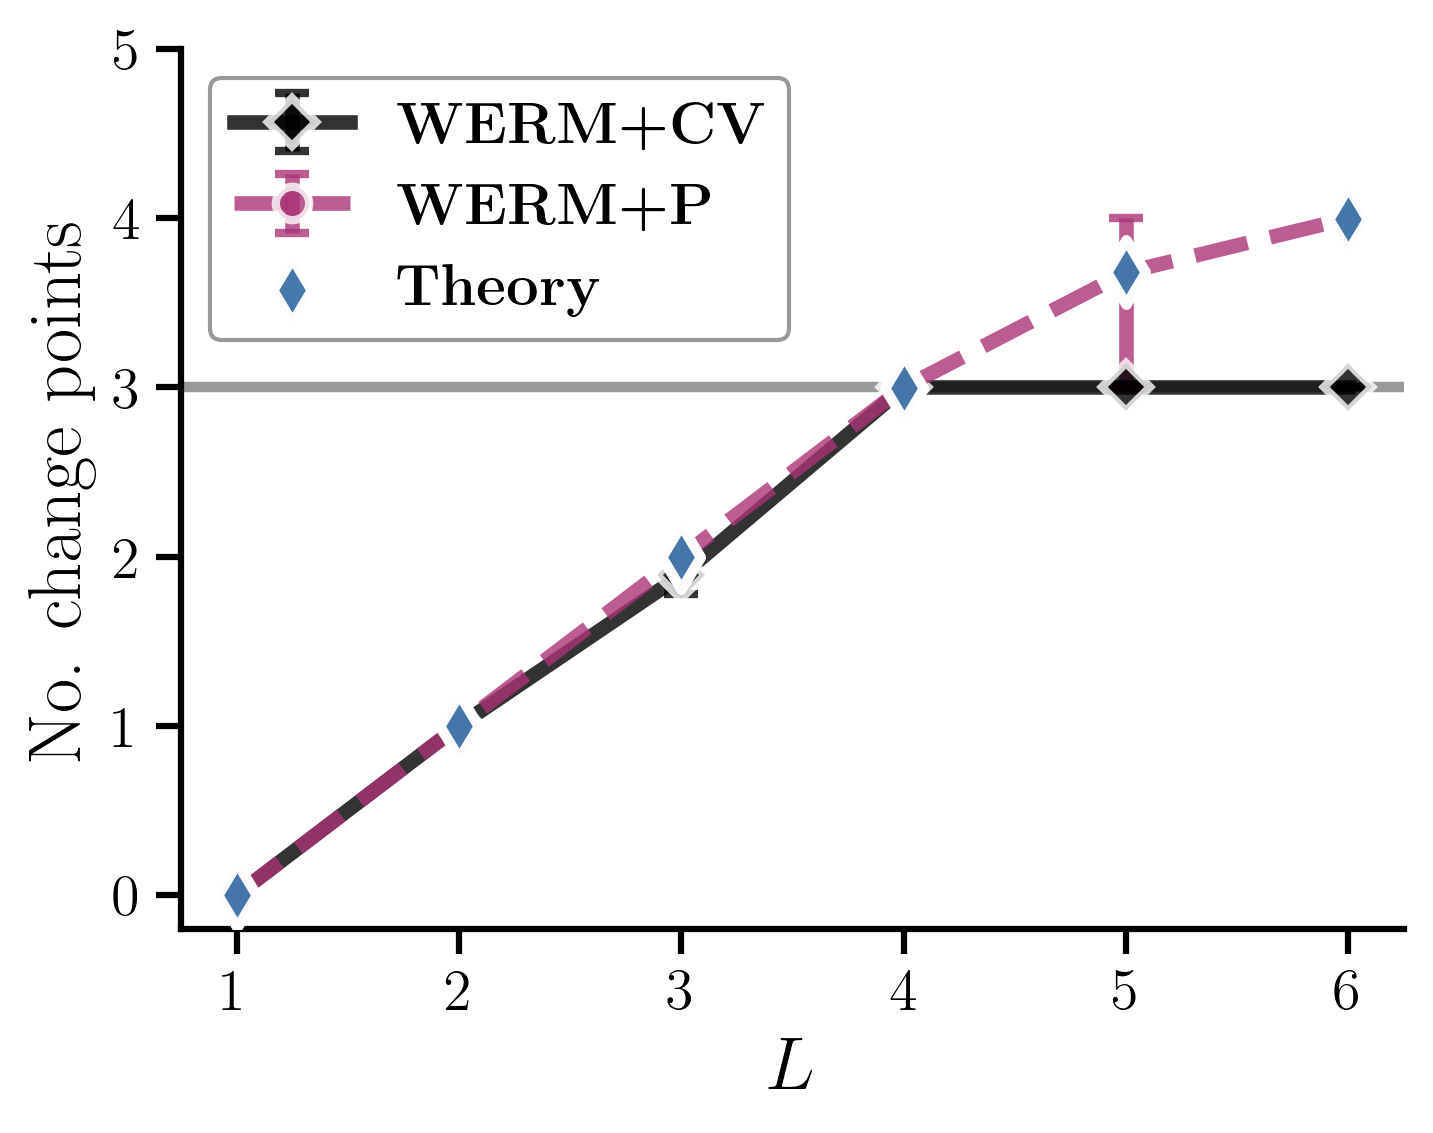

matched_upper_L_count_box


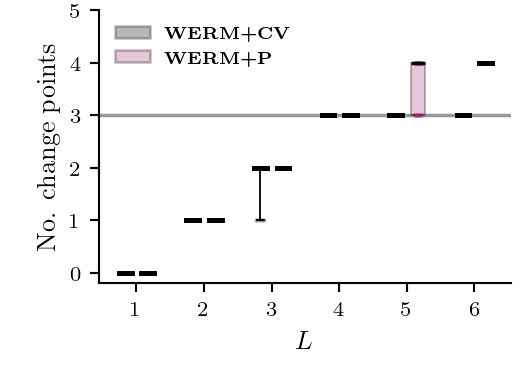

matched_upper_L_haus_line


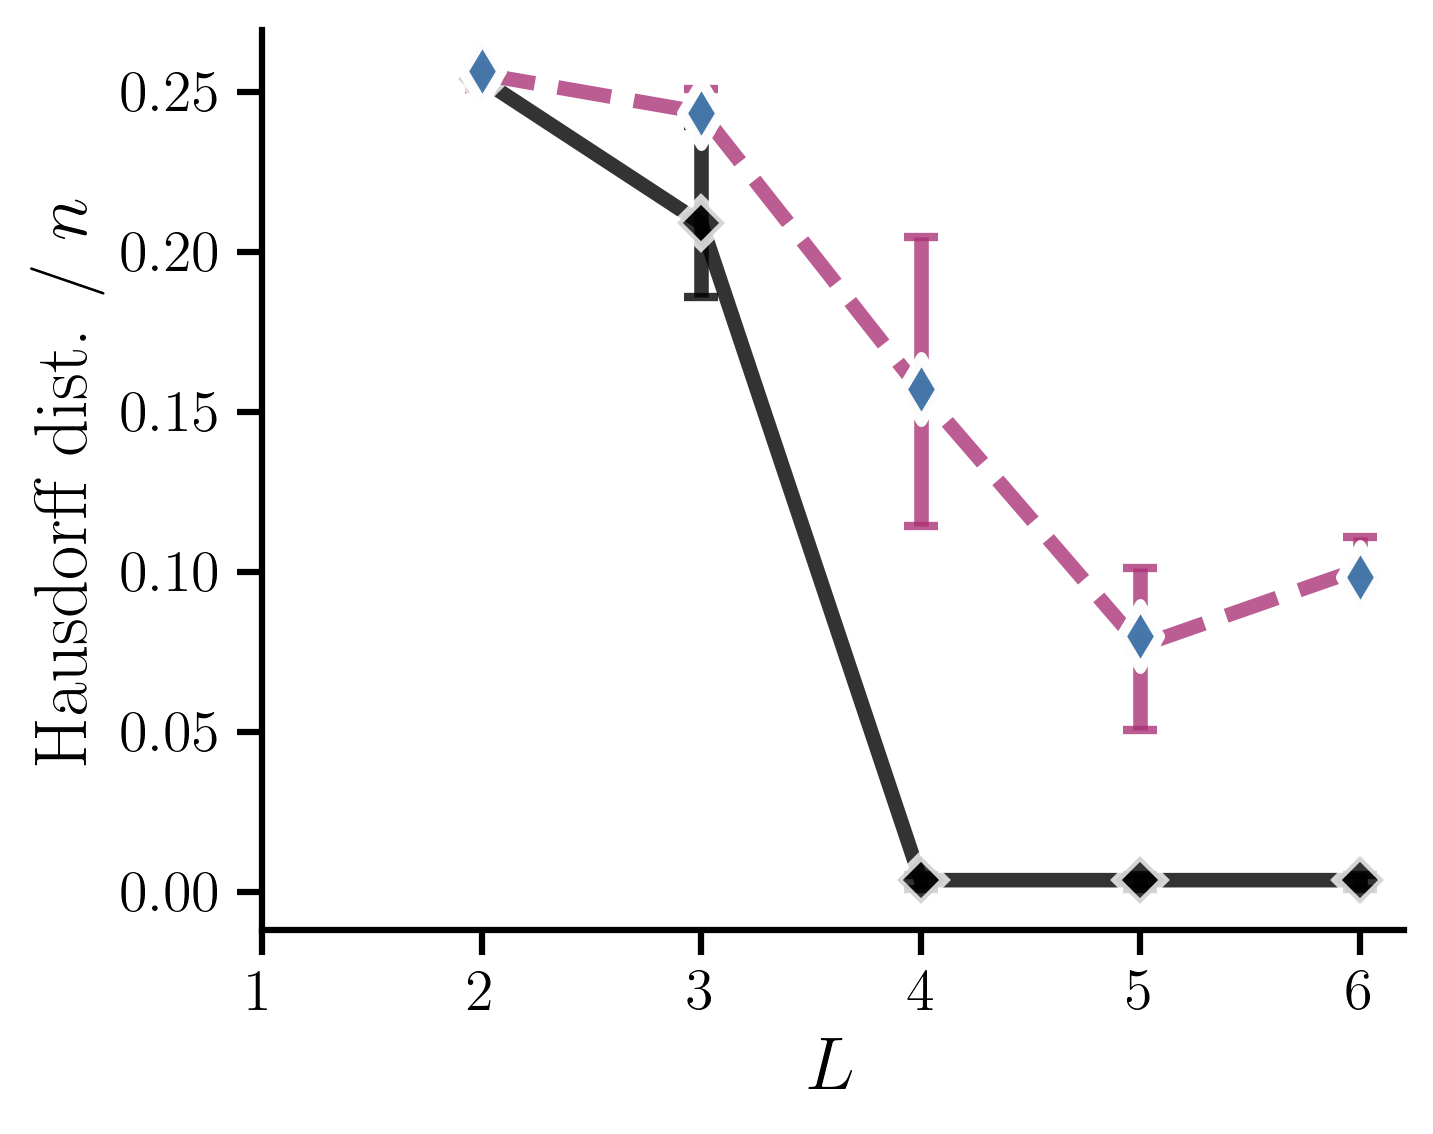

matched_upper_L_haus_box


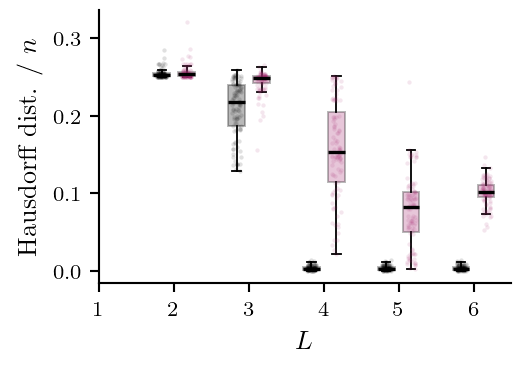

/scratch/ga442/gab-code-env/papers/WeightedERM-reference/tools/consistent_plotting.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[.03,.05,.96,.96])


Change-point location histograms: canonical M1 bins, KDE, ticks and layout.


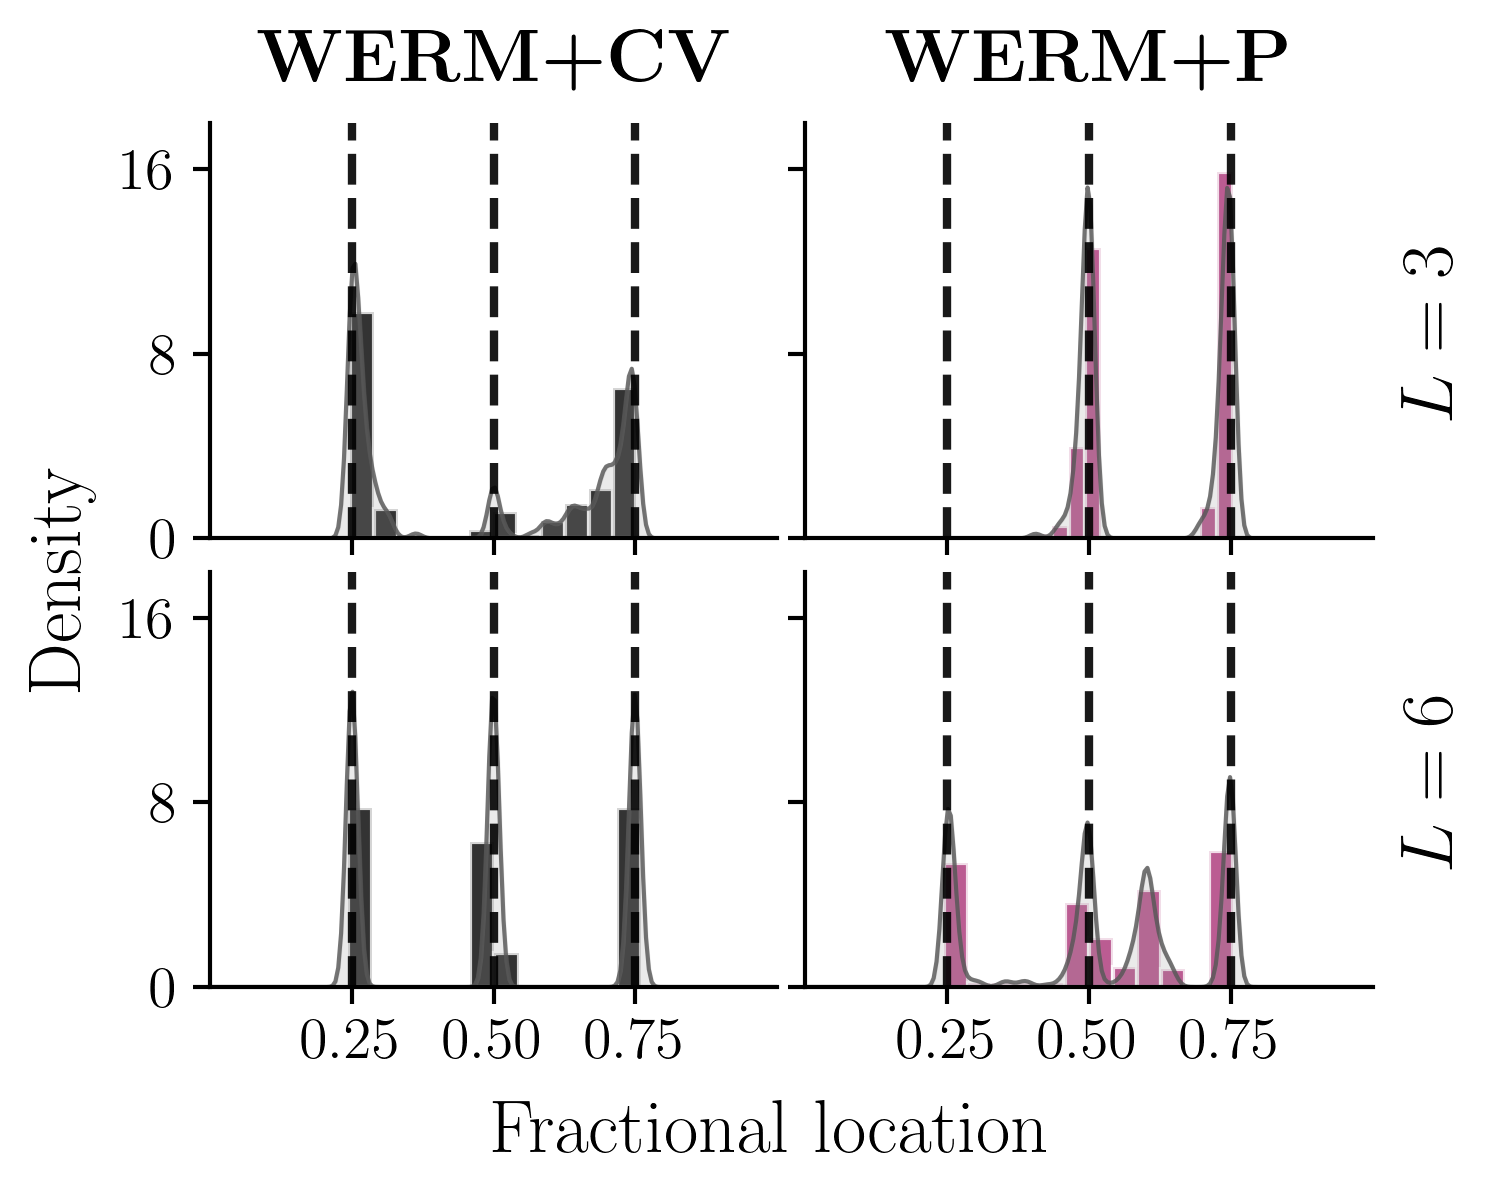

Exported 5 figures to results/E_L_matched_CV_penalty/3af038cb5e34/figures; saved inputs unchanged.


In [1]:
# Independently load the completed matched study for plotting.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
import tools.consistent_plotting as match_style

# Plot the completed, frozen study without preparing or running new experiments.
MATCH_ROOT=Path('results/E_L_matched_CV_penalty/3af038cb5e34')
match_style.OUTPUT_DIR=MATCH_ROOT/'figures'
match_style.SOURCE_HASHES.clear();match_style.FIGURE_AUDIT.clear()
MATCH_SAVED=match_style.load_saved(MATCH_ROOT/'study.pkl')
MATCH_SPEC=MATCH_SAVED['specification']
MATCH_RECORDS=MATCH_SAVED['records']
MATCH_BOUNDS=np.arange(1,7)
MATCH_METHODS=('cv','penalty')
MATCH_LABELS=(r'\textbf{WERM+CV}',r'\textbf{WERM+P}')
MATCH_COLORS=('black','#AA3377')

def matched_groups(method,metric):
    return [np.array([fit[metric] for r in MATCH_RECORDS for fit in
        (r['fits'][L]['theory'] if method=='theory' else [r['fits'][L][method]])])
        for L in MATCH_BOUNDS]

for metric,ylabel in [('count','No. change points'),('haus',r'Hausdorff dist. / $n$')]:
    for kind in ('line','box'):
        with plt.rc_context(match_style.CANONICAL_STYLE if kind=='line' else match_style.PAPER_STYLE):
            if kind=='line':
                fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
            else:
                fig,ax=match_style.paper_panel();rng=np.random.default_rng(42)
            for j,method in enumerate(MATCH_METHODS):
                groups=matched_groups(method,metric)
                if kind=='line':
                    match_style.error_series(ax,MATCH_BOUNDS,groups,MATCH_LABELS[j],
                        MATCH_COLORS[j],('D','o')[j],('-','--')[j],scale=1)
                else:
                    for i,values in enumerate(groups):
                        match_style.box_group(ax,values,3*i+j,MATCH_COLORS[j],rng)
            ax.set(xlabel=r'$L$',ylabel=ylabel)
            if kind=='line':
                theory=matched_groups('theory',metric)
                means=[np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in theory]
                theory_label=r'\textbf{Theory}'
                ax.scatter(MATCH_BOUNDS,means,label=theory_label,marker='d',
                    color='#4477AA',s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
                ax.set_xticks(MATCH_BOUNDS)
                handles,labels=ax.get_legend_handles_labels()
                ordered=(*MATCH_LABELS,theory_label)
                if metric=='count':
                    ax.legend([handles[labels.index(label)] for label in ordered],ordered,
                        loc='best',prop={'size':14},framealpha=.4)
            else:
                ax.set_xticks(np.arange(len(MATCH_BOUNDS))*3+.5,
                              [str(v) for v in MATCH_BOUNDS])
                if metric=='count':
                    ax.legend(handles=[Patch(facecolor=c,alpha=.28,edgecolor='black',label=l)
                        for c,l in zip(MATCH_COLORS,MATCH_LABELS)],loc='best',fontsize=7)
            if metric=='count':
                ax.axhline(3,color='gray',lw=2.5 if kind=='line' else 1.4,alpha=.8,zorder=0)
                ax.set_yticks(range(6))
            if kind=='line':fig.tight_layout()
            match_style.export_plot(fig,f'matched_upper_L_{metric}_{kind}')

MATCH_HIST_BOUNDS=(3,6)
MATCH_POOLS=[[np.concatenate([np.asarray(r['fits'][L][method]['cp'])/MATCH_SPEC['n']
                              for r in MATCH_RECORDS]) for method in MATCH_METHODS]
             for L in MATCH_HIST_BOUNDS]
match_style.histogram_grid(MATCH_POOLS,MATCH_LABELS,MATCH_COLORS,
    MATCH_SPEC['true_fractions'],'matched_upper_L_histograms_L3_L6',
    row_labels=[rf'$L={L}$' for L in MATCH_HIST_BOUNDS],
    density_label_x=.005,figsize=(5,4))
match_style.verify_sources()

### Penalty theory on the matched setting

These two panels compare **WERM+P** with **Theory**, using the squared-loss SE
equations and proximal fitted-value construction documented above. The theory
shares the same frozen upper-bound weights, true signal matrix, spacing, and
$\gamma=6$ penalty. Its empirical design/noise and theoretical Gaussian draws are
independent conditional on the signal matrix. All 2,000 realizations enter each
theory mean. Blue diamonds have no connecting lines or error bars, following the
SE estimation notebook.

matched_upper_L_penalty_theory_count


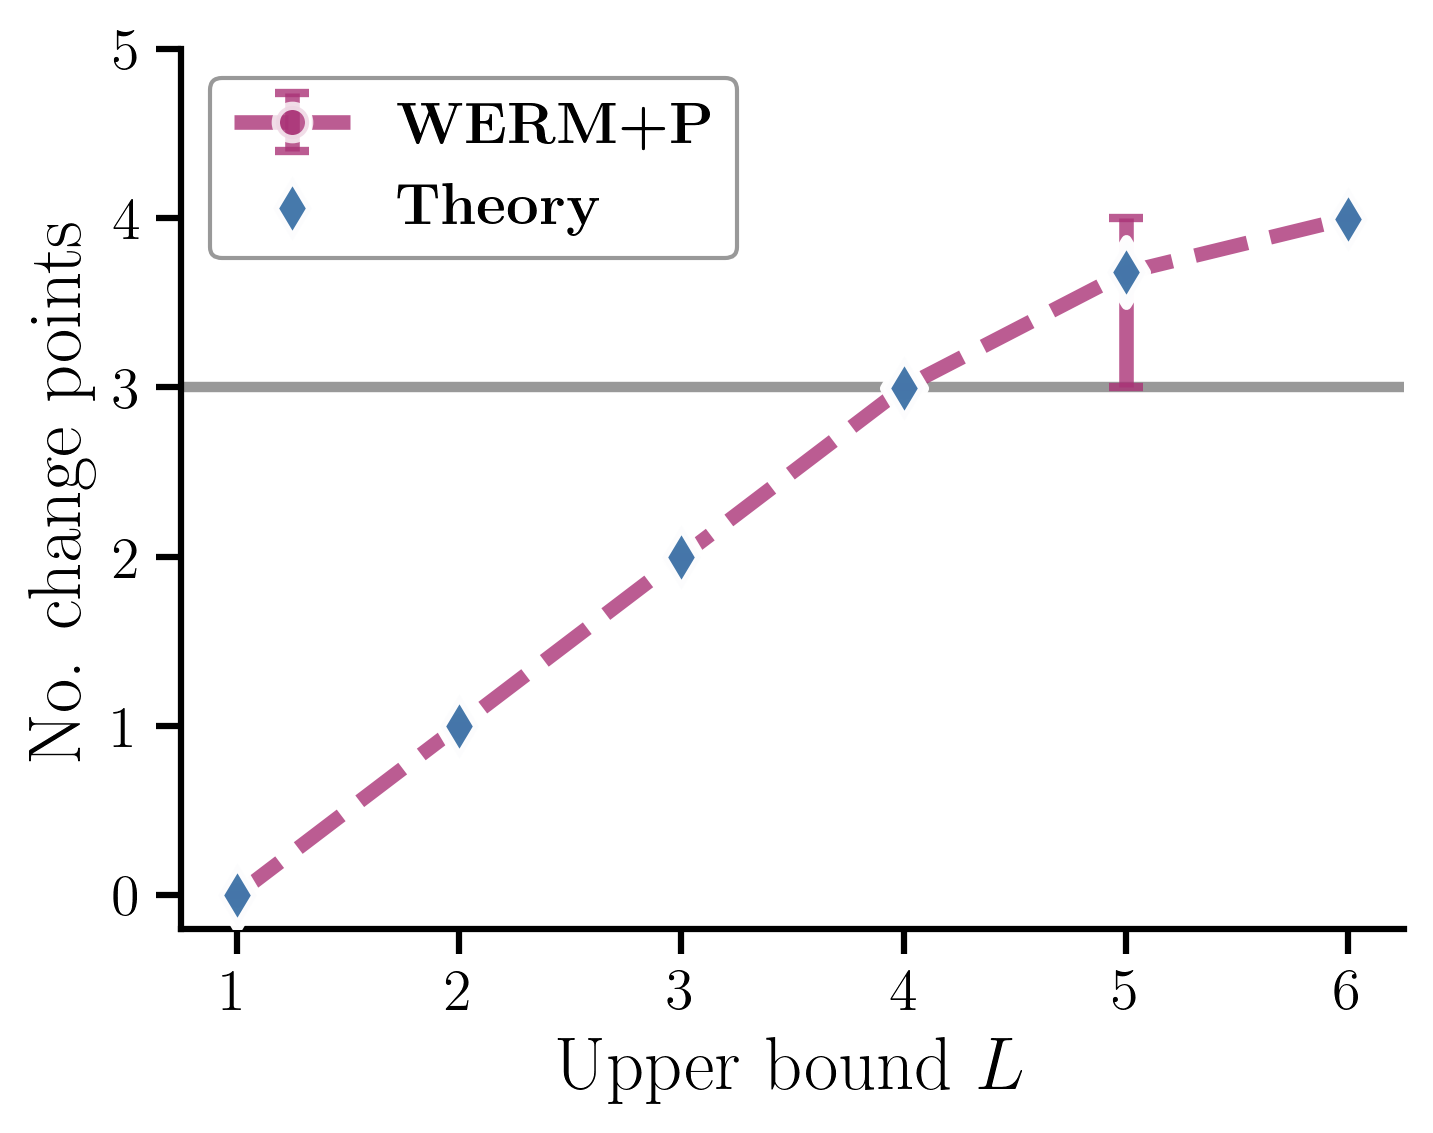

matched_upper_L_penalty_theory_haus


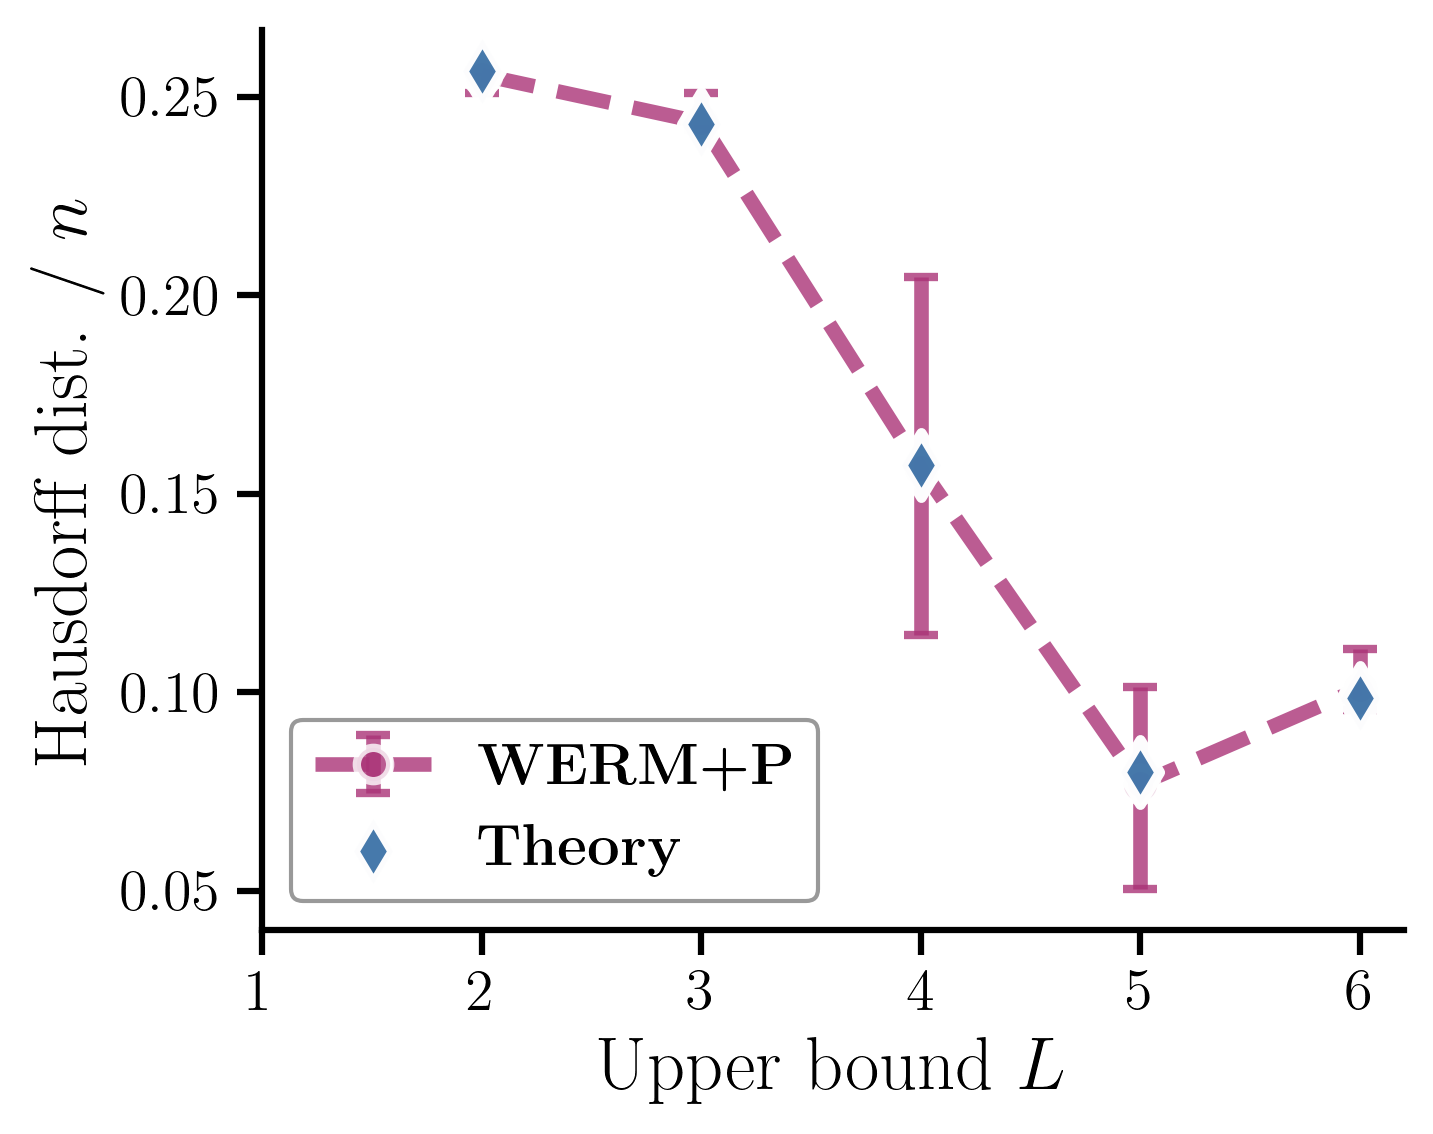

Exported 7 figures to results/E_L_matched_CV_penalty/3af038cb5e34/figures; saved inputs unchanged.


In [3]:
for metric,ylabel in [('count','No. change points'),('haus',r'Hausdorff dist. / $n$')]:
    with plt.rc_context(match_style.CANONICAL_STYLE):
        fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
        match_style.error_series(ax,MATCH_BOUNDS,matched_groups('penalty',metric),
            MATCH_LABELS[1],MATCH_COLORS[1],'o','--',scale=1)
        theory=matched_groups('theory',metric)
        means=[np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in theory]
        ax.scatter(MATCH_BOUNDS,means,label=r'\textbf{Theory}',marker='d',
            color='#4477AA',s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=5)
        ax.set(xlabel=r'Upper bound $L$',ylabel=ylabel,xticks=MATCH_BOUNDS)
        if metric=='count':
            ax.axhline(3,color='gray',lw=2.5,alpha=.8,zorder=0)
            ax.set_yticks(range(6))
        handles,labels=ax.get_legend_handles_labels()
        order=[labels.index(label) for label in (MATCH_LABELS[1],r'\textbf{Theory}')]
        ax.legend([handles[i] for i in order],(MATCH_LABELS[1],r'\textbf{Theory}'),
                  loc='best',prop={'size':14},framealpha=.4)
        fig.tight_layout();match_style.export_plot(fig,f'matched_upper_L_penalty_theory_{metric}')
match_style.verify_sources()

### Completeness and provenance

Each trial stores one shared data hash, both empirical procedures, every candidate
CV score, all six upper-bound selections, and the independent penalty-theory
outcomes. The checks retain every trial and verify the fixed settings and SE
residuals. Raw source data are not altered by plotting. Earlier notebook sections
and artifacts remain unchanged.

In [4]:
assert MATCH_SPEC['gamma']==6.
assert MATCH_SPEC['n']==1000 and MATCH_SPEC['p']==100
np.testing.assert_array_equal(MATCH_SPEC['true_fractions'],[.25,.5,.75])
assert len(MATCH_RECORDS)==100
assert {r['trial'] for r in MATCH_RECORDS}==set(range(100))
assert len({r['data_hash'] for r in MATCH_RECORDS})==100
for record in MATCH_RECORDS:
    np.testing.assert_array_equal(record['truth'],[250,500,750])
    assert set(record['fits'])==set(MATCH_BOUNDS)
    scores=np.asarray(record['cv']['cv_scores'])
    assert scores.shape==(6,) and np.isfinite(scores).all()
    for L in MATCH_BOUNDS:
        outcomes=record['fits'][L]
        assert outcomes['cv']['segments']==int(np.argmin(scores[:L]))+1
        assert len(outcomes['theory'])==20
        for fit in [outcomes['cv'],outcomes['penalty'],*outcomes['theory']]:
            assert fit['count']==len(fit['cp'])==fit['segments']-1
            assert 0<=fit['count']<L
            assert bool(fit['empty'])==(fit['count']==0)
            assert (not np.isfinite(fit['haus'])) if fit['empty'] else np.isfinite(fit['haus'])
max_residual=max(r['se_residual'] for r in MATCH_RECORDS)
assert max_residual<1e-9
match_style.verify_sources()
print('Validated 100 paired datasets, six bounds, gamma=6, and all theory realizations.')
print('Maximum SE residual:',max_residual)
print('Implementation: tools/el_matched_selection.py')
print('Summary:',MATCH_ROOT/'summary.csv')
print('Figures:',MATCH_ROOT/'figures')

Exported 7 figures to results/E_L_matched_CV_penalty/3af038cb5e34/figures; saved inputs unchanged.
Validated 100 paired datasets, six bounds, gamma=6, and all theory realizations.
Maximum SE residual: 3.03381153868899e-15
Implementation: tools/el_matched_selection.py
Summary: results/E_L_matched_CV_penalty/3af038cb5e34/summary.csv
Figures: results/E_L_matched_CV_penalty/3af038cb5e34/figures


## Joint comparison with Theory for WERM+CV and WERM+P

This approved companion experiment uses **$n=1500$, $p=100$, 100 paired trials**,
with true changes at **$(0.25,0.50,0.75)n$**, upper bounds $L=1,\ldots,6$, and
the frozen penalty coefficient **$\gamma=6$**. Both empirical methods and both
theory predictions use this new setting. The preceding $n=1000$ results remain
a separate comparison.

The larger sample size supports the uniform-refit CV theory: the earlier
$n=1000$ setting produced 90-row refits for some five- and six-segment
candidates, below $p=100$. Here each training fold has 1350 observations.
The native internal-gap constraints are 150 rows in full-data searches and
135 rows in training searches; endpoint segments remain merely nonempty.
Every empirical and theoretical segment, including endpoints and unselected
candidates, is audited below for $m_s/p>1$. No trial or candidate is removed
to satisfy that audit.

Retain the Gaussian coefficient random walk, design normalization
$X_{ij}\sim N(0,1/n)$, noise standard deviation $0.5$, base seed 20261120,
half-squared fitting loss, and unpenalized coefficients. The initial coefficient
variance is $n/p$ and each independent jump has variance $1.5^2n/p$.
WERM+CV uses exhaustive interlaced 10-fold CV, squared-loss segment refits,
absolute held-out error, and conditional fixed-count prior weights.
WERM+P uses upper-bound mixture weights and minimizes the unnormalized
half-squared partition loss plus $6\log\binom{n-1}{K-1}$, with $1\le K\le L$.
Native marginal curves use the same 50-point grid, gap 5, and frozen seed 0,
recomputed at the new full and training sample sizes.

### CV Theory construction

Use the same first-order construction as `E-WERM-CV-theory.ipynb`.
For a training fold of size $m$, solve the weighted squared-loss equations with
$\delta_{\rm train}=m/p$ and $\Gamma=B^\top B/n$. The latter is unchanged by
the equivalent fold normalization $\widetilde X=X_{\rm train}/\sqrt{m/n}$,
$\widetilde B=\sqrt{m/n}B$.

For each candidate count, search the deterministic expected SE residual-loss
profile over the same admissible training partitions. In each resulting segment
$s$, let $q_s$ be its true-regime proportions, $\delta_s=m_s/p$, and
$D_s=q_s^\top\operatorname{diag}(\Gamma)$, $Q_s=q_s^\top\Gamma q_s$.
Uniform-weight squared-loss refit theory gives
$$\lambda_s=q_s,\qquad
\kappa_s=\frac{\sigma^2+D_s-Q_s}{\delta_s-1},\qquad \delta_s>1.$$
For a held-out observation in true regime $r$, the predicted absolute loss is
$$R_{sr}=\sqrt{\frac{2}{\pi}}
\sqrt{\sigma^2+(q_s-e_r)^\top\Gamma(q_s-e_r)+\kappa_s}.$$
Average over the actual held-out segment/regime overlaps and folds, then take
the theory's own CV argmin among $1,\ldots,L$. At that selected count, solve SE
again using the full-data weights and ratio, and apply the fixed-count partition
search to 20 independent proximal fitted-value realizations. WERM+P Theory
uses the separate upper-bound weights and its own penalized search, as above.

Neither prediction receives empirical fitted coefficients, estimated partitions,
validation scores, or selected counts. The oracle true signal matrix is used
only to evaluate theory predictions. CV Theory has one selected count per true
signal matrix; its 20 final draws describe localization, not 20 separate CV
selections. They are not treated as independent datasets.

This composition is a **first-order extension to CV**, requiring stability of
the limiting training partitions and their data-selected refits, and separated
limiting score minima. It is not a proved finite-sample joint law for overlapping
folds or selection frequencies. Finite-union concentration does not require
independent folds, but does not by itself supply those stability assumptions.
As in the earlier CV theory notebook, native weights can have zero-support
regions; extending the paper's strict-positivity regularity assumption remains
a separate theoretical requirement.

In [1]:
# Self-contained companion run; matching completed checkpoints are reused.
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from tools import el_matched_cv_theory as both

BOTH_ROOT,BOTH_SPEC,BOTH_WEIGHTS=both.prepare(trials=100,theory_draws=20)
BOTH_FILE=BOTH_ROOT/'study.pkl'
BOTH_STUDY=(pickle.loads(BOTH_FILE.read_bytes()) if BOTH_FILE.exists()
            else both.run(BOTH_ROOT,BOTH_SPEC,BOTH_WEIGHTS,
                jobs=int(os.environ.get('EL_BOTH_THEORY_JOBS','12'))))
BOTH_SUMMARY=both.summary(BOTH_STUDY)
print('Both-Theory companion:',BOTH_ROOT)
print('n =',BOTH_SPEC['n'],'; p =',BOTH_SPEC['p'],'; gamma =',BOTH_SPEC['gamma'])
display(BOTH_SUMMARY.round(5))

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (53 outputs left out)

[Parallel(n_jobs=12)]: Done  88 out of 100 | elapsed:    4.8s remaining:    0.6s


[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    5.2s finished


Both-Theory companion: results/E_L_matched_CV_penalty_both_theory/a202b683a096
n = 1500 ; p = 100 ; gamma = 6.0


,L,method,trials,draws,count_draws,mean_count,correct_count,empty,mean_haus,median_haus
0,1,WERM+CV,100,100,100,0.000,0.000,100,NaN,NaN
1,1,WERM+P,100,100,100,0.000,0.000,100,NaN,NaN
2,1,Theory (CV),100,2000,100,0.000,0.000,100,NaN,NaN
3,1,Theory (P),100,2000,2000,0.000,0.000,2000,NaN,NaN
4,2,WERM+CV,100,100,100,1.000,0.000,0,0.25218,0.25100
5,2,WERM+P,100,100,100,1.000,0.000,0,0.25694,0.25133
6,2,Theory (CV),100,2000,100,1.000,0.000,0,0.25230,0.25133
7,2,Theory (P),100,2000,2000,1.000,0.000,0,0.25485,0.25133
8,3,WERM+CV,100,100,100,2.000,0.000,0,0.22014,0.23167
9,3,WERM+P,100,100,100,2.000,0.000,0,0.24670,0.24900


### Joint count and localization plots

Black: **WERM+CV**; purple: **WERM+P**. Both empirical curves retain the
canonical mean-to-quartile bars. Hollow green diamonds are **Theory (CV)** and
filled blue diamonds are **Theory (P)**, so both remain visible when predictions
overlap. Both are scatter markers without connecting lines
or error bars. The count reference line is three true changes.

Hausdorff distance is normalized by $n$ and conditional on a nonempty estimate;
empty estimates remain in count summaries. Thus $L=1$ has no Hausdorff value.
The plots use the same 100 datasets across bounds and methods, with all 20 final
theory realizations retained for localization.

matched_both_theory_count


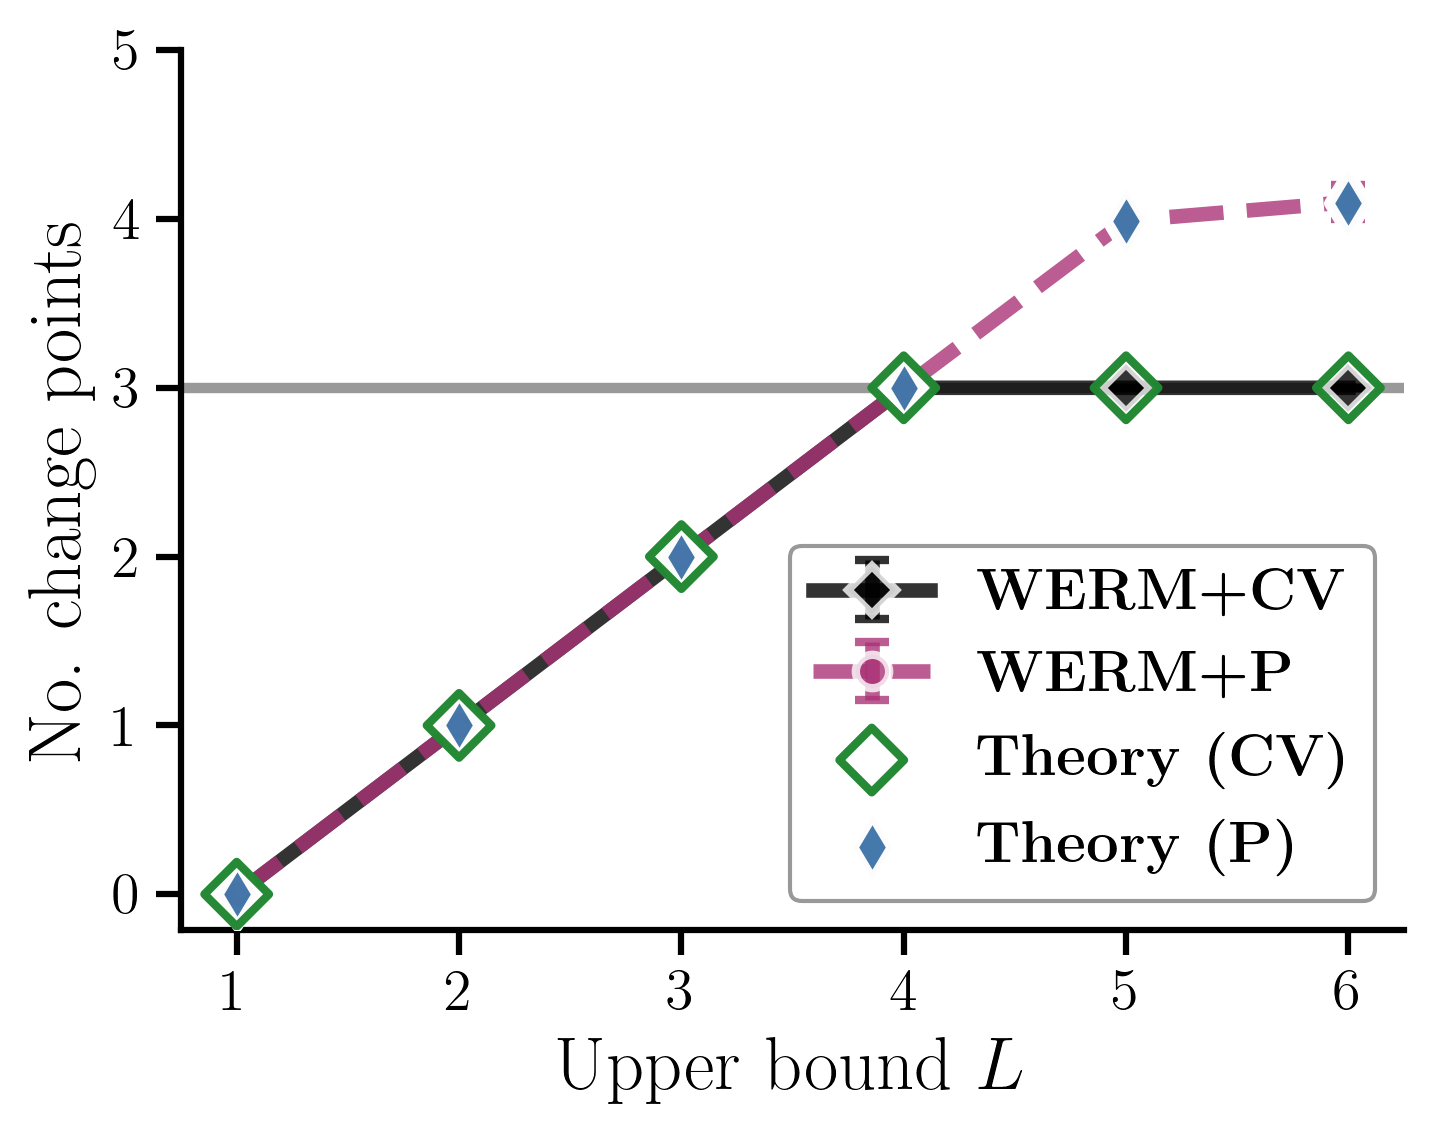

matched_both_theory_haus


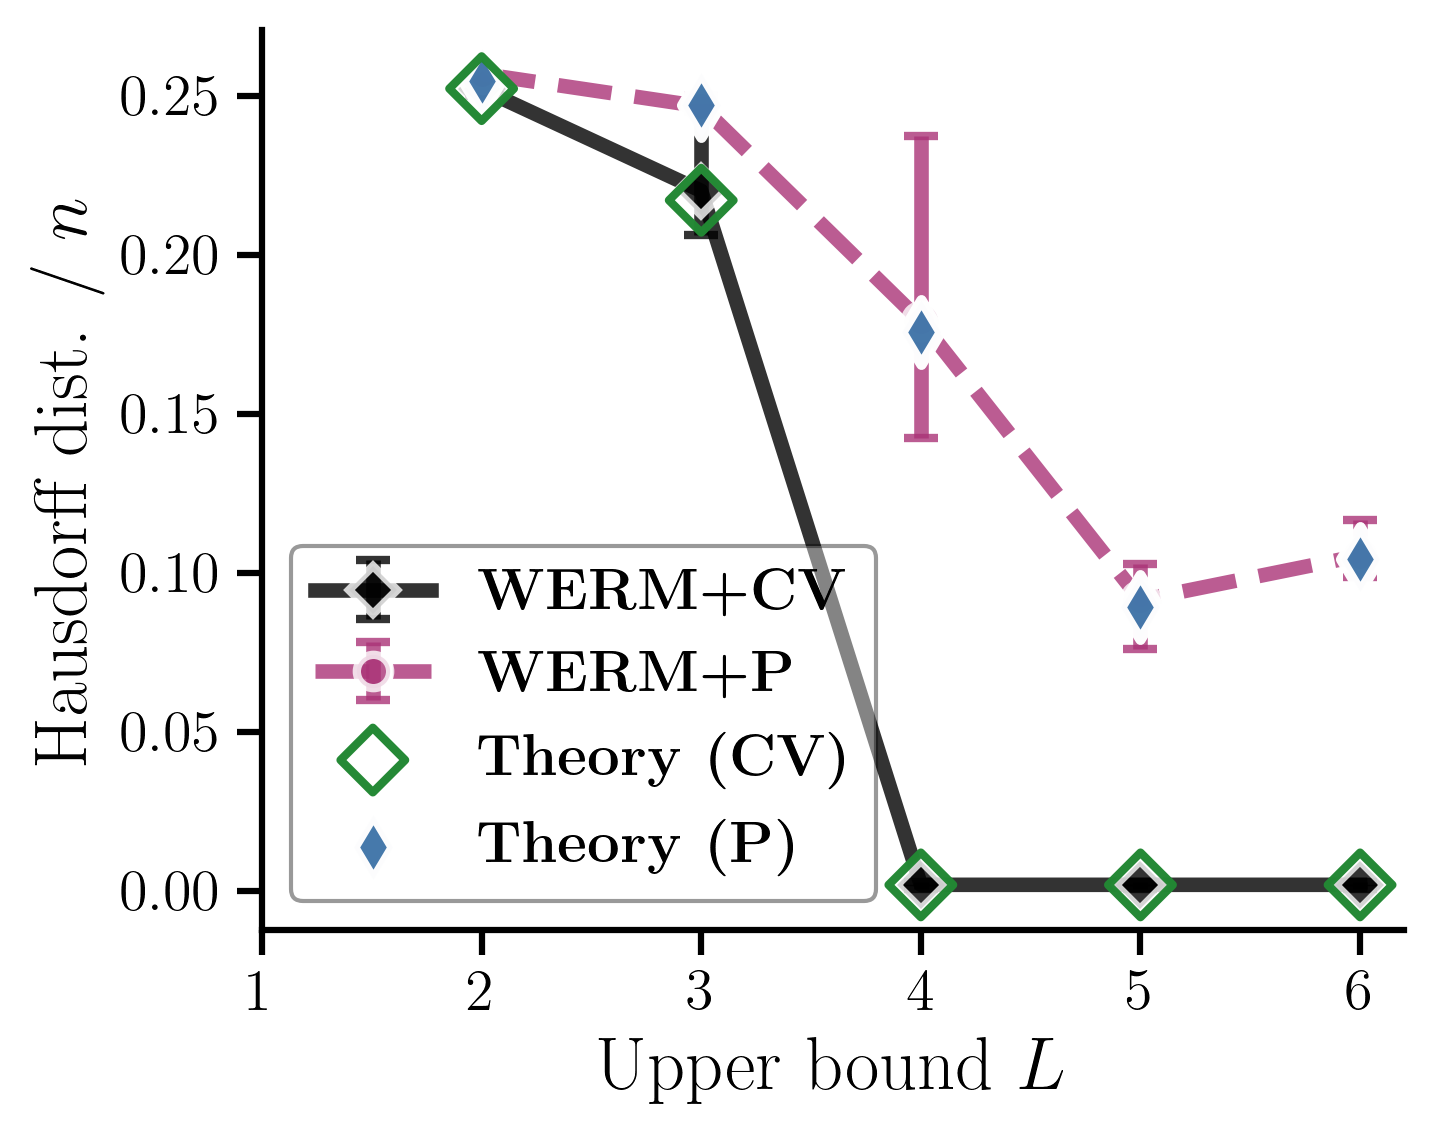

Exported 2 figures to results/E_L_matched_CV_penalty_both_theory/a202b683a096/figures; saved inputs unchanged.


In [2]:
# Independently load the completed companion results for these plots.
import numpy as np
import matplotlib.pyplot as plt
from tools import el_matched_cv_theory as both
import tools.consistent_plotting as both_style

BOTH_ROOT,BOTH_SPEC,_=both.prepare(trials=100,theory_draws=20)
both_style.OUTPUT_DIR=BOTH_ROOT/'figures'
both_style.SOURCE_HASHES.clear();both_style.FIGURE_AUDIT.clear()
BOTH_SAVED=both_style.load_saved(BOTH_ROOT/'study.pkl')
BOTH_RECORDS=BOTH_SAVED['records']
BOTH_BOUNDS=np.arange(1,7)
BOTH_LABELS=(r'\textbf{WERM+CV}',r'\textbf{WERM+P}',
             r'\textbf{Theory (CV)}',r'\textbf{Theory (P)}')
BOTH_COLORS=('black','#AA3377','#228833','#4477AA')

def both_groups(method,metric):
    if method=='cv_theory' and metric=='count':
        return [np.array([r['cv_theory']['selected_by_bound'][L]['selected_segments']-1
                          for r in BOTH_RECORDS],float) for L in BOTH_BOUNDS]
    return [np.array([fit[metric] for r in BOTH_RECORDS for fit in
        (r['fits'][L][method] if method.endswith('_theory') else [r['fits'][L][method]])])
        for L in BOTH_BOUNDS]

for metric,ylabel in [('count','No. change points'),('haus',r'Hausdorff dist. / $n$')]:
    with plt.rc_context(both_style.CANONICAL_STYLE):
        fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
        for j,method in enumerate(('cv','penalty')):
            both_style.error_series(ax,BOTH_BOUNDS,both_groups(method,metric),
                BOTH_LABELS[j],BOTH_COLORS[j],('D','o')[j],('-','--')[j],scale=1)
        for j,method in enumerate(('cv_theory','penalty_theory'),start=2):
            values=both_groups(method,metric)
            means=[np.mean(v[np.isfinite(v)]) if np.isfinite(v).any() else np.nan for v in values]
            if method=='cv_theory':
                ax.scatter(BOTH_BOUNDS,means,label=BOTH_LABELS[j],marker='D',
                    facecolor='none',edgecolor=BOTH_COLORS[j],s=120,linewidth=2,alpha=.99,zorder=9)
            else:
                ax.scatter(BOTH_BOUNDS,means,label=BOTH_LABELS[j],marker='d',
                    color=BOTH_COLORS[j],s=120,edgecolor='white',linewidth=2.5,alpha=.99,zorder=8)
        ax.set(xlabel=r'Upper bound $L$',ylabel=ylabel,xticks=BOTH_BOUNDS)
        if metric=='count':
            ax.axhline(3,color='gray',lw=2.5,alpha=.8,zorder=0)
            ax.set_yticks(range(6))
        handles,labels=ax.get_legend_handles_labels()
        ax.legend([handles[labels.index(label)] for label in BOTH_LABELS],BOTH_LABELS,
                  loc='best',prop={'size':14},framealpha=.4)
        fig.tight_layout();both_style.export_plot(fig,f'matched_both_theory_{metric}')
both_style.verify_sources()

### Candidate-score agreement and numerical validity

The CV score panel displays all six candidates before upper-bound selection.
Scores are normalized absolute held-out errors, averaged across the 100
datasets. Theory uses its own limiting intervals and uniform-refit risks.
This check helps distinguish agreement of mean count curves from agreement of
the underlying risks. The table reports the minimum empirical and theoretical
segment ratios across all candidates/folds and the fixed-point residuals.
Every dataset and every candidate is retained.

matched_both_theory_cv_scores


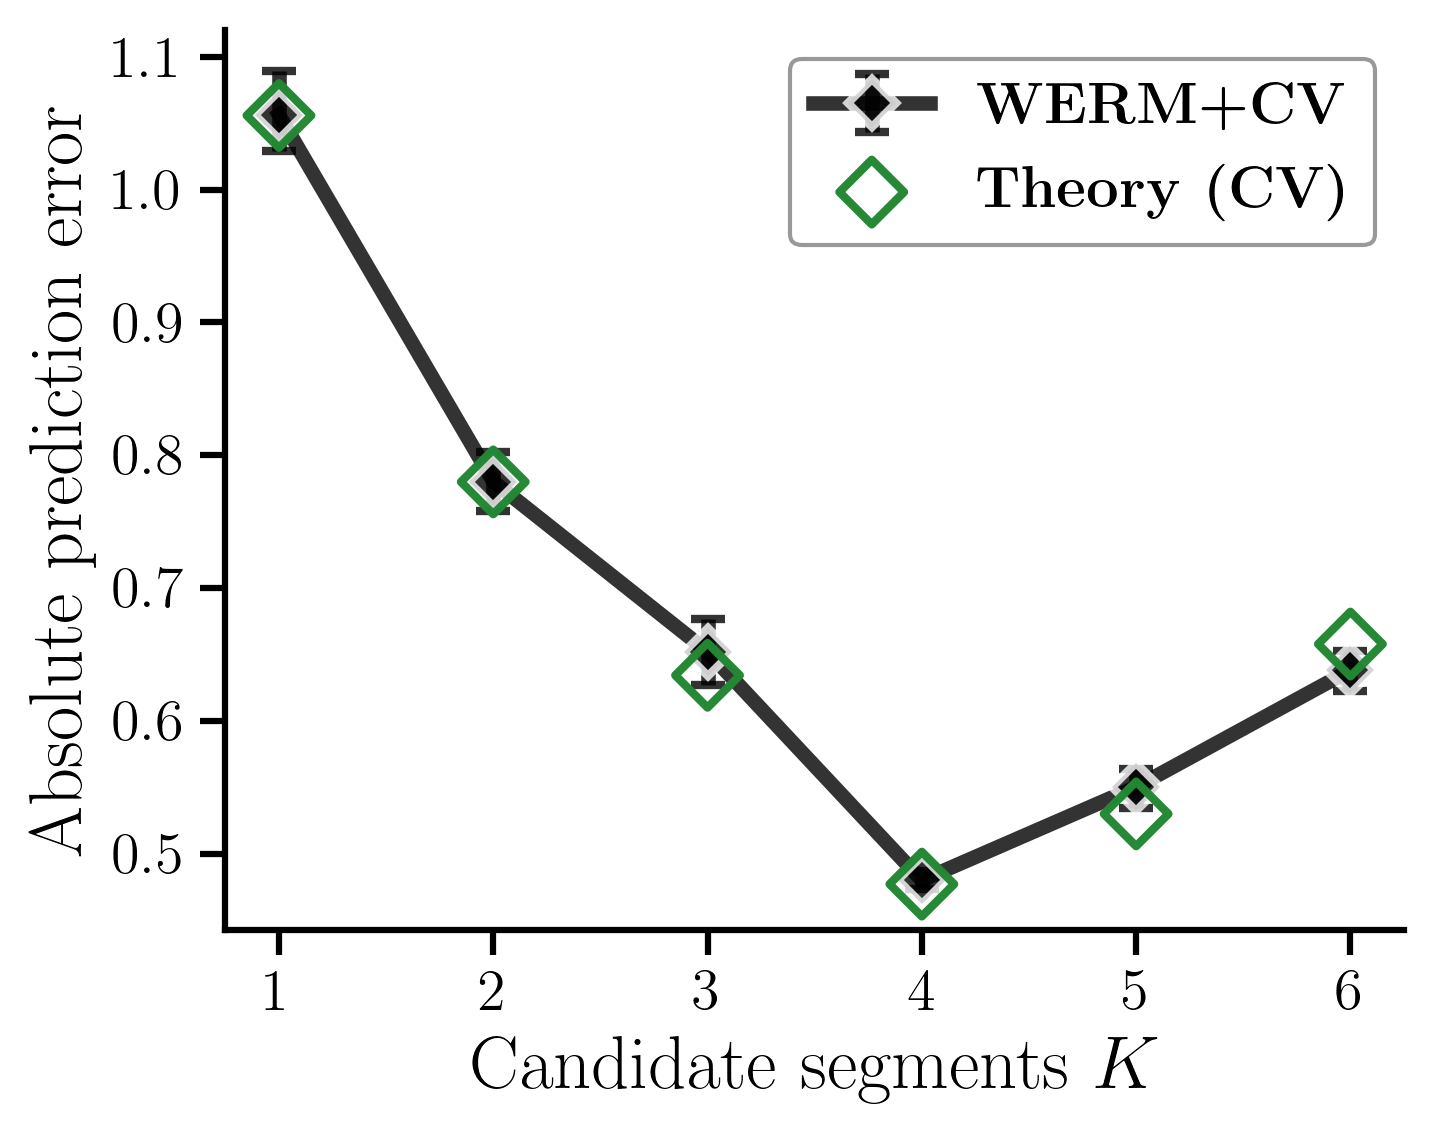

,trial,min_empirical_segment_ratio,min_theory_segment_ratio,max_se_residual,cv_score_mae
count,100.000000,100.00,100.00,100.0,100.000000
mean,49.500000,1.35,1.35,0.0,0.018959
std,29.011492,0.00,0.00,0.0,0.005576
min,0.000000,1.35,1.35,0.0,0.007595
25%,24.750000,1.35,1.35,0.0,0.015604
50%,49.500000,1.35,1.35,0.0,0.018507
75%,74.250000,1.35,1.35,0.0,0.021788
max,99.000000,1.35,1.35,0.0,0.036487


Exported 3 figures to results/E_L_matched_CV_penalty_both_theory/a202b683a096/figures; saved inputs unchanged.
Validated all 100 datasets and 6000 empirical / 6000 theoretical CV folds.
Minimum empirical segment ratio: 1.35
Minimum theoretical segment ratio: 1.35
Maximum SE residual: 7.258247972422166e-14
Figures: results/E_L_matched_CV_penalty_both_theory/a202b683a096/figures


In [3]:
empirical_scores=np.array([r['cv']['normalized_cv_scores'] for r in BOTH_RECORDS])
theory_scores=np.array([r['cv_theory']['normalized_cv_scores'] for r in BOTH_RECORDS])
with plt.rc_context(both_style.CANONICAL_STYLE):
    fig,ax=plt.subplots(figsize=(5,4));fig._canonical_m1=True
    both_style.error_series(ax,BOTH_BOUNDS,empirical_scores.T,
        BOTH_LABELS[0],BOTH_COLORS[0],'D','-',scale=1)
    ax.scatter(BOTH_BOUNDS,theory_scores.mean(axis=0),label=BOTH_LABELS[2],marker='D',
        facecolor='none',edgecolor=BOTH_COLORS[2],s=120,linewidth=2,alpha=.99,zorder=5)
    ax.set(xlabel=r'Candidate segments $K$',ylabel='Absolute prediction error',xticks=BOTH_BOUNDS)
    handles,labels=ax.get_legend_handles_labels()
    ordered=(BOTH_LABELS[0],BOTH_LABELS[2])
    ax.legend([handles[labels.index(label)] for label in ordered],ordered,
              loc='best',prop={'size':14},framealpha=.4)
    fig.tight_layout();both_style.export_plot(fig,'matched_both_theory_cv_scores')

import pandas as pd
from IPython.display import display
BOTH_DIAGNOSTICS=pd.DataFrame([dict(trial=r['trial'],**r['diagnostics']) for r in BOTH_RECORDS])
BOTH_DIAGNOSTICS.to_csv(BOTH_ROOT/'notebook_diagnostics.csv',index=False)
display(BOTH_DIAGNOSTICS.describe().round(6))
assert BOTH_SPEC['n']==1500 and BOTH_SPEC['p']==100 and BOTH_SPEC['gamma']==6.
np.testing.assert_array_equal(BOTH_SPEC['true_fractions'],[.25,.5,.75])
assert len(BOTH_RECORDS)==100
assert {r['trial'] for r in BOTH_RECORDS}==set(range(100))
assert len({r['data_hash'] for r in BOTH_RECORDS})==100
assert np.isfinite(empirical_scores).all() and np.isfinite(theory_scores).all()
for record in BOTH_RECORDS:
    np.testing.assert_array_equal(record['truth'],[375,750,1125])
    assert len(record['cv']['fold_results'])==len(record['cv_theory']['fold_results'])==60
    assert all(np.min(f['segment_sample_ratios'])>1 for f in record['cv']['fold_results'].values())
    assert all(np.min(f['segment_ratios'])>1 for f in record['cv_theory']['fold_results'].values())
    for L in BOTH_BOUNDS:
        fits=record['fits'][L]
        empirical_k=int(np.argmin(record['cv']['cv_scores'][:L]))+1
        theory_k=int(np.argmin(record['cv_theory']['cv_scores'][:L]))+1
        assert fits['cv']['segments']==empirical_k
        assert record['cv_theory']['selected_by_bound'][L]['selected_segments']==theory_k
        assert len(fits['cv_theory'])==len(fits['penalty_theory'])==20
        assert all(fit['segments']==theory_k for fit in fits['cv_theory'])
        for fit in [fits['cv'],fits['penalty'],*fits['cv_theory'],*fits['penalty_theory']]:
            assert fit['count']==len(fit['cp'])==fit['segments']-1
            assert 0<=fit['count']<L
            assert bool(fit['empty'])==(fit['count']==0)
assert BOTH_DIAGNOSTICS.min_empirical_segment_ratio.min()>1
assert BOTH_DIAGNOSTICS.min_theory_segment_ratio.min()>1
assert BOTH_DIAGNOSTICS.max_se_residual.max()<1e-9
both_style.verify_sources()
print('Validated all 100 datasets and 6000 empirical / 6000 theoretical CV folds.')
print('Minimum empirical segment ratio:',BOTH_DIAGNOSTICS.min_empirical_segment_ratio.min())
print('Minimum theoretical segment ratio:',BOTH_DIAGNOSTICS.min_theory_segment_ratio.min())
print('Maximum SE residual:',BOTH_DIAGNOSTICS.max_se_residual.max())
print('Figures:',BOTH_ROOT/'figures')